In [15]:
# Purpose: Load original flows and retain their provenance for later auditing and splitting.
# Explain: Timestamp correction is a documented assumption; source IDs are audit metadata.

import pandas as pd
import numpy as np
from pathlib import Path

# Sort paths so ingestion order is reproducible on every machine.
# Sort file paths so repeated runs use the same ingestion order.
files = sorted(
    Path("GeneratedLabelledFlows").rglob("*.csv"),
    key=lambda path: path.as_posix(),
)

# Collect each loaded file as one DataFrame; concatenation occurs later.
raw_frames = []
for file in files:
    # The web-attack labels contain a Windows-1252 dash. Using cp1252
    # decodes it as punctuation instead of the control character produced
    # by latin-1. low_memory=False also avoids mixed-type chunk inference.
    frame = pd.read_csv(file, encoding="cp1252", low_memory=False)
    # Remove accidental spaces so the same column has one consistent name.
    frame.columns = frame.columns.str.strip()

    # A source-based identifier remains stable even if file loading order changes.
    frame["source_file"] = file.name
    frame["source_row"] = np.arange(1, len(frame) + 1, dtype=np.int64)
    # Keep the frame with its original row provenance attached.
    raw_frames.append(frame)

raw_columns = raw_frames[0].columns.drop(["source_file", "source_row"]).tolist()
df = pd.concat(raw_frames, ignore_index=True)
del raw_frames

# Preserve empty CSV records for the full raw-data audit. They are flagged
# here rather than silently removed. Modeling datasets will exclude them only
# after their count and treatment have been reported.
df["is_empty_record"] = df[raw_columns].isna().all(axis=1)

# Keep the source text so timestamp parsing decisions remain auditable.
df["Timestamp_raw"] = df["Timestamp"].astype("string")
parsed_timestamp = pd.to_datetime(
    df["Timestamp_raw"],
    dayfirst=True,
    format="mixed",
    errors="coerce",
)

# The source timestamps use a 12-hour clock without AM/PM. The official
# documentation states that collection ran during working hours (roughly
# 09:00-17:00). Therefore raw clock hours 1-7 represent 13:00-19:00.
# This rule does not depend on row order, which is not strictly chronological.
raw_hour = parsed_timestamp.dt.hour
afternoon_clock_value = raw_hour.between(1, 7, inclusive="both")
adjustment_hours = 12 * afternoon_clock_value.fillna(False).astype("int8")

df["Timestamp_adjustment_hours"] = adjustment_hours
df["Timestamp"] = parsed_timestamp + pd.to_timedelta(adjustment_hours, unit="h")
df["Day"] = df["Timestamp"].dt.day_name()
df["row_id"] = (
    df["source_file"].astype("string")
    + "::"
    + df["source_row"].astype("string")
)

ingestion_summary = pd.Series({
    "source_files": len(files),
    "physical_csv_records": len(df),
    "completely_empty_records": int(df["is_empty_record"].sum()),
    "nonempty_records": int((~df["is_empty_record"]).sum()),
    "malformed_nonempty_timestamps": int(
        df.loc[~df["is_empty_record"], "Timestamp"].isna().sum()
    ),
    "unique_row_ids": int(df["row_id"].nunique()),
}, name="value")

display(ingestion_summary.to_frame())
display(df.loc[~df["is_empty_record"]].head())

,value
source_files,8
physical_csv_records,3119345
completely_empty_records,288602
nonempty_records,2830743
malformed_nonempty_timestamps,0
unique_row_ids,3119345


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,Idle Max,Idle Min,Label,source_file,source_row,is_empty_record,Timestamp_raw,Timestamp_adjustment_hours,Day,row_id
0,192.168.10.5-104.16.207.165-54865-443-6,104.16.207.165,443.0,192.168.10.5,54865.0,6.0,2017-07-07 15:30:00,3.0,2.0,0.0,...,0.0,0.0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,1,False,7/7/2017 3:30,12,Friday,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...
1,192.168.10.5-104.16.28.216-55054-80-6,104.16.28.216,80.0,192.168.10.5,55054.0,6.0,2017-07-07 15:30:00,109.0,1.0,1.0,...,0.0,0.0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,2,False,7/7/2017 3:30,12,Friday,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...
2,192.168.10.5-104.16.28.216-55055-80-6,104.16.28.216,80.0,192.168.10.5,55055.0,6.0,2017-07-07 15:30:00,52.0,1.0,1.0,...,0.0,0.0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,3,False,7/7/2017 3:30,12,Friday,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...
3,192.168.10.16-104.17.241.25-46236-443-6,104.17.241.25,443.0,192.168.10.16,46236.0,6.0,2017-07-07 15:30:00,34.0,1.0,1.0,...,0.0,0.0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,4,False,7/7/2017 3:30,12,Friday,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...
4,192.168.10.5-104.19.196.102-54863-443-6,104.19.196.102,443.0,192.168.10.5,54863.0,6.0,2017-07-07 15:30:00,3.0,2.0,0.0,...,0.0,0.0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,5,False,7/7/2017 3:30,12,Friday,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...


In [16]:
df.shape

(3119345, 92)

# Part 1: Understand how the data were generated

## 1.1 What one row represents

Each row is a **bidirectional network flow** constructed by CICFlowMeter from packets that share connection characteristics. The row is not a raw packet and it is not an entire attack episode. It summarizes behavior such as duration, packet and byte counts, packet sizes, inter-arrival times, TCP flags, and active/idle periods.

This distinction matters because a classifier learns patterns in these summaries. A high score does not automatically mean it learned the causal attack mechanism; it may instead recognize the experiment's host addresses, ports, time windows, NAT path, attack tool, or source file.

## 1.2 Evidence policy

We keep two kinds of evidence separate:

1. **Documented schedule:** facts reported by the official UNB CICIDS2017 documentation and the dataset paper.
2. **CSV-observed evidence:** values we calculate directly from the supplied flow files.

A disagreement is something to investigate, not something to silently overwrite. In particular, a common CSV endpoint is not automatically the attacker: NAT and bidirectional flow orientation can make the firewall address or victim appear as the source.


In [17]:
# Purpose: Record the official attack schedule before examining predictive plots.
# Explain: Hosts, services, and attack times suggest possible shortcuts, not verified mechanisms.

# Ground-truth experiment schedule reported by the official UNB documentation.
# Times are written explicitly in 24-hour form so afternoon attacks are not
# accidentally interpreted as early-morning traffic.

schedule_records = [
    {"Label": "FTP-Patator", "Day": "Tuesday", "Time": "09:20-10:20", "Attacker": "Kali, 205.174.165.73 (NAT path includes 172.16.0.1)", "Victim": "Web server, 192.168.10.50", "Service": "FTP / TCP 21", "Tool_or_scenario": "Patator brute force"},
    {"Label": "SSH-Patator", "Day": "Tuesday", "Time": "14:00-15:00", "Attacker": "Kali, 205.174.165.73 (NAT path includes 172.16.0.1)", "Victim": "Web server, 192.168.10.50", "Service": "SSH / TCP 22", "Tool_or_scenario": "Patator brute force"},
    {"Label": "DoS slowloris", "Day": "Wednesday", "Time": "09:47-10:10", "Attacker": "Kali, 205.174.165.73 (NAT path includes 172.16.0.1)", "Victim": "Web server, 192.168.10.50", "Service": "HTTP / TCP 80", "Tool_or_scenario": "Slowloris"},
    {"Label": "DoS Slowhttptest", "Day": "Wednesday", "Time": "10:14-10:35", "Attacker": "Kali, 205.174.165.73 (NAT path includes 172.16.0.1)", "Victim": "Web server, 192.168.10.50", "Service": "HTTP / TCP 80", "Tool_or_scenario": "slowhttptest"},
    {"Label": "DoS Hulk", "Day": "Wednesday", "Time": "10:43-11:00", "Attacker": "Kali, 205.174.165.73 (NAT path includes 172.16.0.1)", "Victim": "Web server, 192.168.10.50", "Service": "HTTP / TCP 80", "Tool_or_scenario": "Hulk"},
    {"Label": "DoS GoldenEye", "Day": "Wednesday", "Time": "11:10-11:23", "Attacker": "Kali, 205.174.165.73 (NAT path includes 172.16.0.1)", "Victim": "Web server, 192.168.10.50", "Service": "HTTP / TCP 80", "Tool_or_scenario": "GoldenEye"},
    {"Label": "Heartbleed", "Day": "Wednesday", "Time": "15:12-15:32", "Attacker": "Kali, 205.174.165.73", "Victim": "Ubuntu 12 server, 192.168.10.51", "Service": "TLS-like service / TCP 444", "Tool_or_scenario": "Heartbleed exploit"},
    {"Label": "Web Attack - Brute Force", "Day": "Thursday", "Time": "09:20-10:00", "Attacker": "Kali, 205.174.165.73 (NAT path includes 172.16.0.1)", "Victim": "Web server, 192.168.10.50", "Service": "HTTP web application / TCP 80", "Tool_or_scenario": "Web-login brute-force scenario; tool not stated in official schedule"},
    {"Label": "Web Attack - XSS", "Day": "Thursday", "Time": "10:15-10:35", "Attacker": "Kali, 205.174.165.73 (NAT path includes 172.16.0.1)", "Victim": "Web server, 192.168.10.50", "Service": "HTTP web application / TCP 80", "Tool_or_scenario": "XSS scenario; tool not stated in official schedule"},
    {"Label": "Web Attack - Sql Injection", "Day": "Thursday", "Time": "10:40-10:42", "Attacker": "Kali, 205.174.165.73 (NAT path includes 172.16.0.1)", "Victim": "Web server, 192.168.10.50", "Service": "HTTP web application / TCP 80", "Tool_or_scenario": "SQL-injection scenario; tool not stated in official schedule"},
    {"Label": "Infiltration", "Day": "Thursday", "Time": "14:19-15:45 (several episodes)", "Attacker": "Kali, then compromised Vista host 192.168.10.8", "Victim": "Vista 192.168.10.8, Mac 192.168.10.25, then other clients", "Service": "Multiple services", "Tool_or_scenario": "Metasploit/Dropbox followed by Nmap"},
    {"Label": "Bot", "Day": "Friday", "Time": "10:02-11:02", "Attacker": "Kali, 205.174.165.73", "Victim": "Windows hosts .5, .8, .9, .14 and .15", "Service": "Bot/C2 scenario; port not stated in official schedule", "Tool_or_scenario": "ARES botnet"},
    {"Label": "PortScan", "Day": "Friday", "Time": "13:55-15:29 (many scan intervals)", "Attacker": "Kali, 205.174.165.73 (NAT path includes 172.16.0.1)", "Victim": "Ubuntu web server, 192.168.10.50", "Service": "Many TCP services/ports", "Tool_or_scenario": "Nmap scan modes"},
    {"Label": "DDoS", "Day": "Friday", "Time": "15:56-16:16", "Attacker": "Three Windows hosts, 205.174.165.69-.71", "Victim": "Ubuntu web server, 192.168.10.50", "Service": "HTTP / TCP 80", "Tool_or_scenario": "LOIT (name used by official schedule)"},
]

official_schedule = pd.DataFrame(schedule_records)
display(official_schedule)

,Label,Day,Time,Attacker,Victim,Service,Tool_or_scenario
0,FTP-Patator,Tuesday,09:20-10:20,"Kali, 205.174.165.73 (NAT path includes 172.16...","Web server, 192.168.10.50",FTP / TCP 21,Patator brute force
1,SSH-Patator,Tuesday,14:00-15:00,"Kali, 205.174.165.73 (NAT path includes 172.16...","Web server, 192.168.10.50",SSH / TCP 22,Patator brute force
2,DoS slowloris,Wednesday,09:47-10:10,"Kali, 205.174.165.73 (NAT path includes 172.16...","Web server, 192.168.10.50",HTTP / TCP 80,Slowloris
3,DoS Slowhttptest,Wednesday,10:14-10:35,"Kali, 205.174.165.73 (NAT path includes 172.16...","Web server, 192.168.10.50",HTTP / TCP 80,slowhttptest
4,DoS Hulk,Wednesday,10:43-11:00,"Kali, 205.174.165.73 (NAT path includes 172.16...","Web server, 192.168.10.50",HTTP / TCP 80,Hulk
5,DoS GoldenEye,Wednesday,11:10-11:23,"Kali, 205.174.165.73 (NAT path includes 172.16...","Web server, 192.168.10.50",HTTP / TCP 80,GoldenEye
6,Heartbleed,Wednesday,15:12-15:32,"Kali, 205.174.165.73","Ubuntu 12 server, 192.168.10.51",TLS-like service / TCP 444,Heartbleed exploit
7,Web Attack - Brute Force,Thursday,09:20-10:00,"Kali, 205.174.165.73 (NAT path includes 172.16...","Web server, 192.168.10.50",HTTP web application / TCP 80,Web-login brute-force scenario; tool not state...
8,Web Attack - XSS,Thursday,10:15-10:35,"Kali, 205.174.165.73 (NAT path includes 172.16...","Web server, 192.168.10.50",HTTP web application / TCP 80,XSS scenario; tool not stated in official sche...
9,Web Attack - Sql Injection,Thursday,10:40-10:42,"Kali, 205.174.165.73 (NAT path includes 172.16...","Web server, 192.168.10.50",HTTP web application / TCP 80,SQL-injection scenario; tool not stated in off...


## 1.3 CSV-observed support table

The next cell summarizes what appears in the supplied CSV files. It is useful for checking label counts, parsed time ranges, and frequent endpoints, but it must **not** be treated as the official schedule.

Two cautions are already visible:

- The frequent source `172.16.0.1` is part of the NAT path, not the documented external attacker.
- Afternoon CSV times can be parsed as early-morning times because the text lacks an explicit AM/PM marker. The documented 24-hour times above are authoritative for reconstructing chronology.

The malformed dash visible in the earlier web-attack labels was an input-decoding issue. The revised loader now uses Windows-1252 decoding, which preserves the intended dash.


In [18]:
# Purpose: Compare the CSV-observed hosts, services, and time ranges with the schedule.
# Explain: Observed metadata supports the audit but cannot confirm packet-level attack behavior.

print(df.columns.tolist())
def most_common(values):
    return values.mode().iloc[0] if not values.mode().empty else None

attack_table = (
    df.groupby("Label")
    .agg(
        Day=("Day", most_common),
        Start=("Timestamp", "min"),
        End=("Timestamp", "max"),
        Common_source=("Source IP", most_common),
        Common_destination=("Destination IP", most_common),
        Common_port=("Destination Port", most_common),
        Flows=("Label", "size")
    )
)

display(attack_table)

['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH 

,Day,Start,End,Common_source,Common_destination,Common_port,Flows
Label,,,,,,,
BENIGN,Monday,2017-07-03 08:55:58,2017-07-07 17:02:00,192.168.10.3,192.168.10.3,53.0,2273097
Bot,Friday,2017-07-07 09:34:00,2017-07-07 12:59:00,205.174.165.73,205.174.165.73,8080.0,1966
DDoS,Friday,2017-07-07 15:56:00,2017-07-07 16:16:00,172.16.0.1,192.168.10.50,80.0,128027
DoS GoldenEye,Wednesday,2017-07-05 11:10:00,2017-07-05 11:19:00,172.16.0.1,192.168.10.50,80.0,10293
DoS Hulk,Wednesday,2017-07-05 10:43:00,2017-07-05 11:07:00,172.16.0.1,192.168.10.50,80.0,231073
DoS Slowhttptest,Wednesday,2017-07-05 10:15:00,2017-07-05 10:37:00,172.16.0.1,192.168.10.50,80.0,5499
DoS slowloris,Wednesday,2017-07-05 09:01:00,2017-07-05 14:25:00,172.16.0.1,192.168.10.50,80.0,5796
FTP-Patator,Tuesday,2017-07-04 09:17:00,2017-07-04 10:30:00,172.16.0.1,192.168.10.50,21.0,7938
Heartbleed,Wednesday,2017-07-05 15:12:00,2017-07-05 15:32:00,172.16.0.1,192.168.10.51,444.0,11


## 1.4 Variables that may act as label proxies

A **proxy** predicts the label because of how this experiment was organized, without necessarily describing the attack mechanism. Important candidates are:

1. **Day, time, and source file.** Every attack family was executed in a narrow scheduled window. A model could learn that Friday afternoon means PortScan or DDoS.
2. **IP addresses and NAT endpoints.** Many attacks follow a fixed path through `172.16.0.1` toward `192.168.10.50`. These addresses identify the testbed and may not transfer to another organization.
3. **Destination port and protocol.** Ports 21, 22, 80, and 444 strongly narrow the possible label. Port 22 can identify the SSH scenario without showing that repeated authentication attempts occurred.
4. **Attack-tool fingerprints.** Patator, Hulk, Slowloris, Nmap, ARES, and LOIT can generate consistent flow shapes. A model may recognize one implementation rather than the broader attack family.
5. **Capture and flow-construction artifacts.** A duplicated or derived CICFlowMeter feature, unusual constant, or file-specific parsing pattern may correlate with a label even though it has no security meaning.

## 1.5 Attack mechanism versus scenario recognition

Detecting an **attack mechanism** means learning behavior that should persist when the host, time, network, and tool change. For example, brute force should still involve repeated authentication attempts even when it targets another server and uses another program.

Recognizing a **scenario-specific clue** means learning that one IP, port, minute, or tool fingerprint happened to correspond to an attack in CICIDS2017. Such a rule can score very well on a random-row split because nearly identical collection conditions appear in training and testing, yet fail on a new network.

Later metadata-only, behavior-only, grouped, and chronological experiments are designed to distinguish these possibilities. They provide evidence of scenario dependence, although they cannot by themselves prove what caused every prediction.

## 1.6 Behavioral hypotheses declared before plotting

### Hypothesis 1 - authentication brute force

FTP-Patator and SSH-Patator should produce many repeated, relatively small authentication flows to a fixed service. Compared with benign FTP/SSH traffic, we expect concentration on ports 21/22, repeated endpoint pairs, relatively small payloads, and characteristic packet/direction counts.

**Why this would help a model:** repeated small request-response attempts are connected to the brute-force mechanism. However, IP address, port, and attack time are competing scenario-specific explanations and must be excluded or probed separately.

### Hypothesis 2 - slow HTTP denial of service

Slowloris and Slowhttptest attempt to occupy server resources while communicating slowly. Compared with high-rate Hulk traffic, we expect longer flow durations, lower packet rates, and larger inter-arrival or idle periods.

**Why this would help a model:** duration and timing behavior are closer to the slow-DoS mechanism than the attacker's address is. A competing explanation is that one tool's implementation or CICFlowMeter's timeout rules created the observed timing signature.

## Sources

- Official UNB CICIDS2017 documentation and schedule: https://www.unb.ca/cic/datasets/ids-2017.html
- Sharafaldin, Lashkari, and Ghorbani (2018), *Toward Generating a New Intrusion Detection Dataset and Intrusion Traffic Characterization*: https://doi.org/10.5220/0006639801080116


## Part 2 :  Audit data quality and class balance

### 2.1 Exact duplicate complete records

An exact duplicate is a nonempty flow record whose complete original CSV content is identical to another record: original timestamp text, endpoints, ports, protocol, label, and every CICFlowMeter feature must all agree. Sharing only a `Flow ID` is not sufficient because multiple records can legitimately belong to the same network conversation.

The 288,602 comma-only records are excluded from this calculation because they are empty file artifacts, not network flows. The audit uses paired row hashes to find a small candidate set efficiently, then verifies those candidates using exact equality across all original fields.


In [19]:
# Purpose: Remove extra copies of complete original records before constructing protocols.
# Explain: Hashing finds candidates; exact comparisons verify them. Keep distinct flows sharing behavior.

# Compare original CSV content. Timestamp_raw is used instead of the corrected
# analytical Timestamp so formatting differences are not hidden.
duplicate_content_columns = [
    column for column in raw_columns if column != "Timestamp"
] + ["Timestamp_raw"]

auditable_flow_mask = (~df["is_empty_record"] & df["Label"].notna()).to_numpy()
auditable_positions = np.flatnonzero(auditable_flow_mask)

def paired_row_signatures(frame, positions, columns, chunk_size=200_000):
    """Create two row signatures in chunks to limit peak memory usage."""
    first = np.empty(len(positions), dtype="uint64")
    second = np.empty(len(positions), dtype="uint64")
    reversed_columns = list(reversed(columns))

    for start in range(0, len(positions), chunk_size):
        stop = min(start + chunk_size, len(positions))
        block = frame.iloc[positions[start:stop]]
        first[start:stop] = pd.util.hash_pandas_object(
            block[columns],
            index=False,
            hash_key="0123456789abcdef",
        ).to_numpy(dtype="uint64")
        second[start:stop] = pd.util.hash_pandas_object(
            block[reversed_columns],
            index=False,
            hash_key="fedcba9876543210",
        ).to_numpy(dtype="uint64")

    return pd.DataFrame({"signature_1": first, "signature_2": second})

row_signatures = paired_row_signatures(
    df, auditable_positions, duplicate_content_columns
)
signature_counts = row_signatures.value_counts(sort=False)
repeated_signatures = signature_counts[signature_counts > 1]
signature_index = pd.MultiIndex.from_frame(row_signatures)
candidate_mask = signature_index.isin(repeated_signatures.index)
candidate_positions = auditable_positions[candidate_mask]

# Hashes only locate candidates. This second step verifies exact equality and
# therefore prevents a theoretical hash collision from becoming a duplicate.
duplicate_candidates = df.iloc[candidate_positions][
    duplicate_content_columns + ["source_file", "source_row", "row_id"]
].copy()
exact_involved = duplicate_candidates.duplicated(
    subset=duplicate_content_columns, keep=False
)
exact_rows = duplicate_candidates.loc[exact_involved].copy()
exact_rows["exact_duplicate_group"] = (
    exact_rows.groupby(
        duplicate_content_columns, dropna=False, sort=False
    ).ngroup() + 1
)
exact_rows = exact_rows.sort_values(
    ["exact_duplicate_group", "source_file", "source_row"]
)
exact_rows["is_redundant_copy"] = (
    exact_rows.groupby("exact_duplicate_group").cumcount() > 0
)

# Preserve every raw row and attach audit flags. The modeling mask keeps the
# first stable source-file/source-row representative from each duplicate group.
df["exact_duplicate_group"] = pd.Series(pd.NA, index=df.index, dtype="Int64")
df.loc[exact_rows.index, "exact_duplicate_group"] = (
    exact_rows["exact_duplicate_group"].astype("Int64")
)
df["is_redundant_exact_duplicate"] = False
redundant_indices = exact_rows.index[exact_rows["is_redundant_copy"]]
df.loc[redundant_indices, "is_redundant_exact_duplicate"] = True

model_base_mask = (
    ~df["is_empty_record"]
    & df["Label"].notna()
    & ~df["is_redundant_exact_duplicate"]
)

groups_spanning_files = (
    exact_rows.groupby("exact_duplicate_group")["source_file"].nunique() > 1
).sum()
duplicate_audit_summary = pd.Series({
    "duplicate_groups": int(exact_rows["exact_duplicate_group"].nunique()),
    "rows_in_duplicate_groups": int(len(exact_rows)),
    "redundant_copies_flagged": int(len(redundant_indices)),
    "groups_spanning_multiple_files": int(groups_spanning_files),
    "records_available_for_modeling": int(model_base_mask.sum()),
}, name="count")

display(duplicate_audit_summary.to_frame())
display(exact_rows[[
    "exact_duplicate_group", "source_file", "source_row",
    "row_id", "is_redundant_copy"
]].head(12))

,count
duplicate_groups,106
rows_in_duplicate_groups,309
redundant_copies_flagged,203
groups_spanning_multiple_files,0
records_available_for_modeling,2830540


,exact_duplicate_group,source_file,source_row,row_id,is_redundant_copy
17643,1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,17644,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,False
17644,1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,17645,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,True
59708,2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,59709,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,False
59709,2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,59710,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,True
494261,3,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,268517,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,False
494265,3,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,268521,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,True
666747,4,Friday-WorkingHours-Morning.pcap_ISCX.csv,154536,Friday-WorkingHours-Morning.pcap_ISCX.csv::154536,False
666750,4,Friday-WorkingHours-Morning.pcap_ISCX.csv,154539,Friday-WorkingHours-Morning.pcap_ISCX.csv::154539,True
688966,5,Friday-WorkingHours-Morning.pcap_ISCX.csv,176755,Friday-WorkingHours-Morning.pcap_ISCX.csv::176755,False
688969,5,Friday-WorkingHours-Morning.pcap_ISCX.csv,176758,Friday-WorkingHours-Morning.pcap_ISCX.csv::176758,True


**Verified result.** There are 106 exact-duplicate groups containing 309 rows. After retaining one representative per group, 203 redundant copies are excluded from modeling and 2,830,540 nonempty labelled records remain. No duplicate group spans multiple source files.

**Treatment and justification.** The raw dataframe is preserved and the duplicate rows receive explicit audit flags. Later partitions use `model_base_mask`, which retains the first deterministic `source_file`/`source_row` representative from every group. This prevents a copied record from entering both training and evaluation and prevents repeated copies from receiving extra statistical weight. The treatment does not claim why duplication occurred; confirming a packet-capture or flow-generation cause would require evidence beyond identical CSV rows.


In [20]:
# Purpose: Inspect raw dimensions and class frequencies as a global quality audit.
# Explain: These counts describe the loaded data, not necessarily the cleaned modeling population.

# Full dataset
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Source files:", df["source_file"].nunique())
display(df["source_file"].value_counts())

full_counts = df["Label"].value_counts() # counts how much each distinct value appears within a column
display(full_counts.rename("Flows"))
# count of different attack classes
print(df["Label"].nunique())

Rows: 3119345
Columns: 94
Source files: 8


source_file
Wednesday-workingHours.pcap_ISCX.csv                           692703
Monday-WorkingHours.pcap_ISCX.csv                              529918
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv         458968
Tuesday-WorkingHours.pcap_ISCX.csv                             445909
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv    288602
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv           286467
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv               225745
Friday-WorkingHours-Morning.pcap_ISCX.csv                      191033
Name: count, dtype: int64

Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack – Brute Force         1507
Web Attack – XSS                  652
Infiltration                       36
Web Attack – Sql Injection         21
Heartbleed                         11
Name: Flows, dtype: int64

15


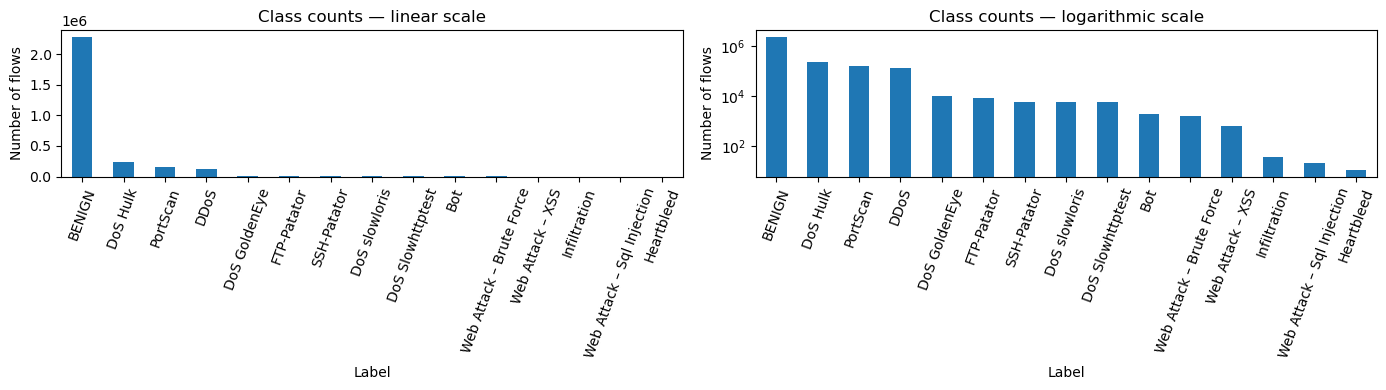

In [21]:
# Purpose: Show class imbalance on linear and logarithmic axes.
# Explain: The log plot makes rare categories visible; it does not change training frequencies.

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# linear plot shows how BENIGN is dominant
full_counts.plot.bar(ax=axes[0])
axes[0].set_title("Class counts — linear scale")

# Logarithmic plot make the less dominant classes visible as well
full_counts.plot.bar(ax=axes[1], logy=True)
axes[1].set_title("Class counts — logarithmic scale")

for ax in axes:
    ax.set_ylabel("Number of flows")
    ax.tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()

## Evaluation protocols

### Random-row protocol

**Deployment question:** How well does the model classify another flow drawn from approximately the same mixture of days, hosts, services, tools, and attack episodes?

This is expected to be the most optimistic protocol because related traffic can occur in every partition. It is still useful as a conventional baseline. We use a predeclared 60% training, 20% validation, and 20% test allocation with stratification by label. Stratification preserves rare-class representation as closely as integer counts allow; it does not remove scenario similarity.


In [29]:
# Purpose: Create and save the reproducible random-row train/validation/test membership.
# Explain: Stratify by the original categories; this tests another flow from a similar collection mixture.

import json
from sklearn.model_selection import train_test_split

# Use the audited modeling base: nonempty, labelled, and one deterministic
# representative from each exact-duplicate group. Keep only position, ID, and
# label arrays here instead of copying all 92 dataframe columns.
model_row_positions = np.flatnonzero(model_base_mask.to_numpy())
model_row_ids = df.iloc[model_row_positions]["row_id"].to_numpy()
model_labels = df.iloc[model_row_positions]["Label"].to_numpy()

RANDOM_SPLIT_SEED = 42
all_positions = np.arange(len(model_row_positions), dtype=np.int64)

# First split: 60% training and 40% temporary. Splitting integer positions
# avoids copying the full 92-column dataframe multiple times.
train_random_positions, temporary_positions = train_test_split(
    all_positions,
    test_size=0.4,
    random_state=RANDOM_SPLIT_SEED,
    stratify=model_labels
)

# Divide the temporary positions equally into validation and test sets.
validation_random_positions, test_random_positions = train_test_split(
    temporary_positions,
    test_size=0.5,
    random_state=RANDOM_SPLIT_SEED,
    stratify=model_labels[temporary_positions]
)

train_random_ids = pd.Series(model_row_ids[train_random_positions], name="row_id")
validation_random_ids = pd.Series(model_row_ids[validation_random_positions], name="row_id")
test_random_ids = pd.Series(model_row_ids[test_random_positions], name="row_id")

random_partition = np.full(len(model_row_positions), "", dtype="U10")
random_partition[train_random_positions] = "train"
random_partition[validation_random_positions] = "validation"
random_partition[test_random_positions] = "test"
random_assignments = pd.DataFrame({
    "row_id": model_row_ids,
    "partition": pd.Categorical(
        random_partition, categories=["train", "validation", "test"]
    ),
})

# Protocol checks: every eligible row appears exactly once, partitions do not
# overlap, and no retained exact-duplicate group has multiple representatives.
assert random_assignments["row_id"].is_unique
assert not (random_partition == "").any()
assert len(train_random_ids) + len(validation_random_ids) + len(test_random_ids) == len(model_row_positions)
retained_duplicate_group_sizes = df.loc[
    model_base_mask & df["exact_duplicate_group"].notna(),
    "exact_duplicate_group",
].value_counts()
assert retained_duplicate_group_sizes.empty or retained_duplicate_group_sizes.max() == 1

random_class_counts = pd.crosstab(
    model_labels,
    random_partition,
    rownames=["Label"],
    colnames=["partition"],
).reindex(columns=["train", "validation", "test"], fill_value=0)

random_split_summary = pd.Series({
    "seed": RANDOM_SPLIT_SEED,
    "eligible_rows": len(model_row_positions),
    "training_rows": len(train_random_ids),
    "validation_rows": len(validation_random_ids),
    "test_rows": len(test_random_ids),
    "unassigned_rows": int((random_partition == "").sum()),
    "duplicate_row_ids": int(random_assignments["row_id"].duplicated().sum()),
}, name="value")

# Save the stable assignments and machine-readable protocol metadata. CSV.GZ
# is used because this environment does not require an optional Parquet engine.
split_output_dir = Path("outputs/splits")
split_output_dir.mkdir(parents=True, exist_ok=True)
random_assignment_path = split_output_dir / "random_row_assignments.csv.gz"
random_metadata_path = split_output_dir / "random_row_metadata.json"
random_assignments.to_csv(
    random_assignment_path,
    index=False,
    compression={"method": "gzip", "compresslevel": 6, "mtime": 0},
)
random_metadata = {
    "protocol": "stratified random-row 60/20/20",
    "seed": RANDOM_SPLIT_SEED,
    "input_rows": int(len(model_row_positions)),
    "train_rows": int(len(train_random_ids)),
    "validation_rows": int(len(validation_random_ids)),
    "test_rows": int(len(test_random_ids)),
    "input_treatment": "empty records excluded; one representative retained per exact complete-record duplicate group",
}
random_metadata_path.write_text(
    json.dumps(random_metadata, indent=2) + "\n", encoding="utf-8"
)

display(random_split_summary.to_frame())
display(random_class_counts)
print("Saved assignments to:", random_assignment_path)
print("Saved metadata to:", random_metadata_path)

,value
seed,42
eligible_rows,2830540
training_rows,1698324
validation_rows,566108
test_rows,566108
unassigned_rows,0
duplicate_row_ids,0


partition,train,validation,test
Label,,,
BENIGN,1363737,454579,454579
Bot,1180,393,393
DDoS,76816,25606,25605
DoS GoldenEye,6176,2059,2058
DoS Hulk,138643,46214,46215
DoS Slowhttptest,3299,1100,1100
DoS slowloris,3477,1159,1160
FTP-Patator,4763,1587,1588
Heartbleed,7,2,2


Saved assignments to: outputs/splits/random_row_assignments.csv.gz
Saved metadata to: outputs/splits/random_row_metadata.json


In [34]:
# Purpose: Keep every bidirectional five-tuple together when allocating grouped partitions.
# Explain: Canonical endpoints combine both directions; shared hosts and episodes can still cross groups.

# ============================================================
# GROUPED PROTOCOL — BIDIRECTIONAL FIVE-TUPLE
# ============================================================
# Deployment question:
# Can the model classify flows belonging to network
# conversations that were not present during training?
#
# Group definition:
# (
#     endpoint_A_IP,
#     endpoint_A_port,
#     endpoint_B_IP,
#     endpoint_B_port,
#     protocol
# )
#
# The endpoints are placed in a canonical order so that:
# A:port1 -> B:port2
# and
# B:port2 -> A:port1
# receive the same group identifier.

GROUPED_SPLIT_SEED = 42

five_tuple_columns = [
    "Source IP",
    "Source Port",
    "Destination IP",
    "Destination Port",
    "Protocol",
]

# Select only the required columns and only modeling-eligible rows.
grouped_rows = (
    df.iloc[
        model_row_positions,
        df.columns.get_indexer(five_tuple_columns)
    ]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 1. Convert IP addresses into stable integer codes
# ------------------------------------------------------------
ip_columns = (
    grouped_rows[["Source IP", "Destination IP"]]
    .astype("string")
    .fillna("<MISSING_IP>")
)

all_ip_values = pd.Index(
    sorted(pd.unique(ip_columns.to_numpy().ravel()).tolist())
)

source_ip_codes = pd.Categorical(
    ip_columns["Source IP"],
    categories=all_ip_values
).codes.astype(np.int32)

destination_ip_codes = pd.Categorical(
    ip_columns["Destination IP"],
    categories=all_ip_values
).codes.astype(np.int32)

# Ports and protocols are numeric identifiers.
source_ports = (
    pd.to_numeric(grouped_rows["Source Port"], errors="coerce")
    .fillna(-1)
    .astype(np.int32)
    .to_numpy()
)

destination_ports = (
    pd.to_numeric(grouped_rows["Destination Port"], errors="coerce")
    .fillna(-1)
    .astype(np.int32)
    .to_numpy()
)

protocol_codes = (
    pd.to_numeric(grouped_rows["Protocol"], errors="coerce")
    .fillna(-1)
    .astype(np.int16)
    .to_numpy()
)

# ------------------------------------------------------------
# 2. Canonicalize flow direction
# ------------------------------------------------------------
# Decide whether the source and destination endpoints should
# be swapped. IP is compared first and port is used to break ties.

# Swap when the source endpoint sorts after the destination endpoint.
# Compare IP codes first; use ports to break a tie when the IPs match.
swap_endpoints = (
    (source_ip_codes > destination_ip_codes)
    |
    (
        (source_ip_codes == destination_ip_codes)
        & (source_ports > destination_ports)
    )
)

# Use the same swap mask for both IP and port so endpoint pairs stay intact.
# Endpoint A is the earlier pair; endpoint B is the later pair.
endpoint_a_ip = np.where(
    swap_endpoints,
    destination_ip_codes,
    source_ip_codes
)

endpoint_a_port = np.where(
    swap_endpoints,
    destination_ports,
    source_ports
)

endpoint_b_ip = np.where(
    swap_endpoints,
    source_ip_codes,
    destination_ip_codes
)

endpoint_b_port = np.where(
    swap_endpoints,
    source_ports,
    destination_ports
)

# Give every distinct five-tuple one integer group identifier.
five_tuple_index = pd.MultiIndex.from_arrays(
    [
        endpoint_a_ip,
        endpoint_a_port,
        endpoint_b_ip,
        endpoint_b_port,
        protocol_codes,
    ],
    names=[
        "endpoint_a_ip",
        "endpoint_a_port",
        "endpoint_b_ip",
        "endpoint_b_port",
        "protocol",
    ],
)

# Assign the same integer to rows with the same canonical key.
# These IDs will constrain partition allocation; they are not predictors.
five_tuple_codes, unique_five_tuples = pd.factorize(
    five_tuple_index,
    sort=True
)

number_of_groups = len(unique_five_tuples)

# ------------------------------------------------------------
# 3. Determine a label stratum for each complete group
# ------------------------------------------------------------
all_label_order = pd.Index(
    sorted(pd.unique(model_labels)),
    name="Label"
)

label_codes = pd.Categorical(
    model_labels,
    categories=all_label_order
).codes

# Find the minimum and maximum label code in each group.
# If they agree, the group has one label.
# If they differ, the group contains multiple labels.
group_min_label = np.full(
    number_of_groups,
    len(all_label_order),
    dtype=np.int16
)

group_max_label = np.full(
    number_of_groups,
    -1,
    dtype=np.int16
)

np.minimum.at(
    group_min_label,
    five_tuple_codes,
    label_codes
)

np.maximum.at(
    group_max_label,
    five_tuple_codes,
    label_codes
)

MIXED_LABEL_STRATUM = len(all_label_order)

group_stratum = np.where(
    group_min_label == group_max_label,
    group_min_label,
    MIXED_LABEL_STRATUM
).astype(np.int16)

# ------------------------------------------------------------
# 4. Split complete groups approximately 60/20/20
# ------------------------------------------------------------
# Groups are randomized separately inside every label stratum.
# This improves class representation without splitting a
# five-tuple across partitions.

rng = np.random.default_rng(GROUPED_SPLIT_SEED)

# Codes: 0 = train, 1 = validation, 2 = test
group_partition_codes = np.full(
    number_of_groups,
    -1,
    dtype=np.int8
)

for stratum_code in range(len(all_label_order) + 1):
    stratum_group_ids = np.flatnonzero(
        group_stratum == stratum_code
    )

    rng.shuffle(stratum_group_ids)
    number_in_stratum = len(stratum_group_ids)

    train_count = int(round(0.60 * number_in_stratum))
    validation_count = int(round(0.20 * number_in_stratum))

    # When at least three groups exist, try to place at least
    # one in every partition.
    if number_in_stratum >= 3:
        train_count = max(
            1,
            min(number_in_stratum - 2, train_count)
        )

        validation_count = max(
            1,
            min(
                number_in_stratum - train_count - 1,
                validation_count
            )
        )

    elif number_in_stratum == 2:
        train_count = 1
        validation_count = 0

    elif number_in_stratum == 1:
        train_count = 1
        validation_count = 0

    train_end = train_count
    validation_end = train_count + validation_count

    group_partition_codes[
        stratum_group_ids[:train_end]
    ] = 0

    group_partition_codes[
        stratum_group_ids[train_end:validation_end]
    ] = 1

    group_partition_codes[
        stratum_group_ids[validation_end:]
    ] = 2

assert (group_partition_codes >= 0).all()

partition_names = np.array(
    ["train", "validation", "test"]
)

grouped_partition = partition_names[
    group_partition_codes[five_tuple_codes]
]

train_grouped_positions = np.flatnonzero(
    grouped_partition == "train"
)

validation_grouped_positions = np.flatnonzero(
    grouped_partition == "validation"
)

test_grouped_positions = np.flatnonzero(
    grouped_partition == "test"
)

train_grouped_ids = pd.Series(
    model_row_ids[train_grouped_positions],
    name="row_id"
)

validation_grouped_ids = pd.Series(
    model_row_ids[validation_grouped_positions],
    name="row_id"
)

test_grouped_ids = pd.Series(
    model_row_ids[test_grouped_positions],
    name="row_id"
)

# ------------------------------------------------------------
# 5. Verify that groups do not cross partitions
# ------------------------------------------------------------
train_group_codes = set(
    five_tuple_codes[train_grouped_positions]
)

validation_group_codes = set(
    five_tuple_codes[validation_grouped_positions]
)

test_group_codes = set(
    five_tuple_codes[test_grouped_positions]
)

train_validation_overlap = (
    train_group_codes & validation_group_codes
)

train_test_overlap = (
    train_group_codes & test_group_codes
)

validation_test_overlap = (
    validation_group_codes & test_group_codes
)

assert not train_validation_overlap
assert not train_test_overlap
assert not validation_test_overlap
assert len(grouped_partition) == len(model_row_positions)
assert not pd.Series(model_row_ids).duplicated().any()

# ------------------------------------------------------------
# 6. Count classes, including explicit zeros
# ------------------------------------------------------------
grouped_class_counts = pd.crosstab(
    model_labels,
    grouped_partition,
    rownames=["Label"],
    colnames=["partition"]
).reindex(
    index=all_label_order,
    columns=["train", "validation", "test"],
    fill_value=0
)

train_grouped_classes = set(
    model_labels[train_grouped_positions]
)

validation_grouped_classes = set(
    model_labels[validation_grouped_positions]
)

test_grouped_classes = set(
    model_labels[test_grouped_positions]
)

grouped_unseen_validation = sorted(
    validation_grouped_classes - train_grouped_classes
)

grouped_unseen_test = sorted(
    test_grouped_classes - train_grouped_classes
)

# ------------------------------------------------------------
# 7. Display the results
# ------------------------------------------------------------
grouped_split_summary = pd.Series(
    {
        "seed": GROUPED_SPLIT_SEED,
        "eligible_rows": len(model_row_positions),
        "unique_five_tuple_groups": number_of_groups,
        "mixed_label_five_tuple_groups": int(
            (group_stratum == MIXED_LABEL_STRATUM).sum()
        ),
        "training_rows": len(train_grouped_ids),
        "validation_rows": len(validation_grouped_ids),
        "test_rows": len(test_grouped_ids),
        "training_percentage": (
            f"{100 * len(train_grouped_ids) / len(model_row_positions):.2f}%"
        ),
        "validation_percentage": (
            f"{100 * len(validation_grouped_ids) / len(model_row_positions):.2f}%"
        ),
        "test_percentage": (
            f"{100 * len(test_grouped_ids) / len(model_row_positions):.2f}%"
        ),
        "train_validation_group_overlap": len(
            train_validation_overlap
        ),
        "train_test_group_overlap": len(
            train_test_overlap
        ),
        "validation_test_group_overlap": len(
            validation_test_overlap
        ),
        "unassigned_rows": int(
            len(model_row_positions)
            - len(train_grouped_positions)
            - len(validation_grouped_positions)
            - len(test_grouped_positions)
        ),
    },
    name="value",
    dtype="object"
)

print("GROUPED FIVE-TUPLE PROTOCOL SUMMARY")
display(grouped_split_summary.to_frame())

print("\nCLASS COUNTS — GROUPED FIVE-TUPLE PROTOCOL")
display(grouped_class_counts)

print("\nValidation classes absent from training:")
print(grouped_unseen_validation or "None")

print("\nTest classes absent from training:")
print(grouped_unseen_test or "None")

GROUPED FIVE-TUPLE PROTOCOL SUMMARY


,value
seed,42
eligible_rows,2830540
unique_five_tuple_groups,1085071
mixed_label_five_tuple_groups,29346
training_rows,1700178
validation_rows,564700
test_rows,565662
training_percentage,60.07%
validation_percentage,19.95%
test_percentage,19.98%



CLASS COUNTS — GROUPED FIVE-TUPLE PROTOCOL


partition,train,validation,test
Label,,,
BENIGN,1364886,454082,453927
Bot,1186,398,382
DDoS,76985,25499,25543
DoS GoldenEye,6242,2007,2044
DoS Hulk,139036,45448,46588
DoS Slowhttptest,3302,1102,1095
DoS slowloris,3525,1155,1116
FTP-Patator,4766,1592,1580
Heartbleed,11,0,0



Validation classes absent from training:
None

Test classes absent from training:
None


In [32]:
# Purpose: Create a globally chronological protocol using corrected flow start/end times.
# Explain: Train Monday-Wednesday, validate Thursday, test Friday; later categories may be unseen.

# ============================================================
# CHRONOLOGICAL PROTOCOL
# ============================================================
# Deployment question:
# Can a model trained on earlier days classify traffic from
# later days?
#
# Training:   Monday-Wednesday
# Validation: Thursday
# Test:       Friday
#
# There is no random seed because this protocol contains no
# random assignment.

CHRONOLOGICAL_TRAIN_END = pd.Timestamp(
    "2017-07-06 00:00:00"
)

CHRONOLOGICAL_VALIDATION_END = pd.Timestamp(
    "2017-07-07 00:00:00"
)

chronological_rows = (
    df.iloc[model_row_positions][
        ["row_id", "Label", "Timestamp", "Flow Duration"]
    ]
    .copy()
    .reset_index(drop=True)
)

chronological_start = chronological_rows["Timestamp"]

# CICFlowMeter Flow Duration is measured in microseconds.
chronological_duration_us = pd.to_numeric(
    chronological_rows["Flow Duration"],
    errors="coerce"
)

valid_duration = (
    chronological_duration_us.notna()
    & np.isfinite(chronological_duration_us)
    & chronological_duration_us.ge(0)
)

valid_timing = (
    chronological_start.notna()
    & valid_duration
)

safe_duration_us = chronological_duration_us.where(
    valid_duration
)

chronological_end = (
    chronological_start
    + pd.to_timedelta(
        safe_duration_us,
        unit="us",
        errors="coerce"
    )
)

chronological_rows["EndTime"] = chronological_end

# ------------------------------------------------------------
# Explicitly identify flows that cross either time boundary.
# ------------------------------------------------------------
crosses_training_boundary = (
    valid_timing
    & chronological_start.lt(CHRONOLOGICAL_TRAIN_END)
    & chronological_end.gt(CHRONOLOGICAL_TRAIN_END)
)

crosses_validation_boundary = (
    valid_timing
    & chronological_start.ge(CHRONOLOGICAL_TRAIN_END)
    & chronological_start.lt(
        CHRONOLOGICAL_VALIDATION_END
    )
    & chronological_end.gt(
        CHRONOLOGICAL_VALIDATION_END
    )
)

boundary_crossing_mask = (
    crosses_training_boundary
    | crosses_validation_boundary
)

# ------------------------------------------------------------
# Construct the three chronological partitions.
# Earlier flows are included only if they finish before the
# next boundary.
# ------------------------------------------------------------
train_chronological_mask = (
    valid_timing
    & chronological_start.lt(CHRONOLOGICAL_TRAIN_END)
    & chronological_end.le(CHRONOLOGICAL_TRAIN_END)
)

validation_chronological_mask = (
    valid_timing
    & chronological_start.ge(CHRONOLOGICAL_TRAIN_END)
    & chronological_start.lt(
        CHRONOLOGICAL_VALIDATION_END
    )
    & chronological_end.le(
        CHRONOLOGICAL_VALIDATION_END
    )
)

test_chronological_mask = (
    valid_timing
    & chronological_start.ge(
        CHRONOLOGICAL_VALIDATION_END
    )
)

chronological_partition = np.full(
    len(chronological_rows),
    "excluded_invalid_timing",
    dtype="U24"
)

chronological_partition[
    boundary_crossing_mask.to_numpy()
] = "excluded_boundary"

chronological_partition[
    train_chronological_mask.to_numpy()
] = "train"

chronological_partition[
    validation_chronological_mask.to_numpy()
] = "validation"

chronological_partition[
    test_chronological_mask.to_numpy()
] = "test"

train_chronological_ids = pd.Series(
    model_row_ids[
        train_chronological_mask.to_numpy()
    ],
    name="row_id"
)

validation_chronological_ids = pd.Series(
    model_row_ids[
        validation_chronological_mask.to_numpy()
    ],
    name="row_id"
)

test_chronological_ids = pd.Series(
    model_row_ids[
        test_chronological_mask.to_numpy()
    ],
    name="row_id"
)

# ------------------------------------------------------------
# Verify chronological ordering and boundary constraints.
# ------------------------------------------------------------
assert (
    chronological_end[train_chronological_mask].max()
    <= CHRONOLOGICAL_TRAIN_END
)

assert (
    chronological_start[
        validation_chronological_mask
    ].min()
    >= CHRONOLOGICAL_TRAIN_END
)

assert (
    chronological_end[
        validation_chronological_mask
    ].max()
    <= CHRONOLOGICAL_VALIDATION_END
)

assert (
    chronological_start[
        test_chronological_mask
    ].min()
    >= CHRONOLOGICAL_VALIDATION_END
)

assigned_chronological_rows = (
    train_chronological_mask
    | validation_chronological_mask
    | test_chronological_mask
)

assert not (
    assigned_chronological_rows
    & boundary_crossing_mask
).any()

# ------------------------------------------------------------
# Class counts, including zeros.
# ------------------------------------------------------------
chronological_class_counts = pd.crosstab(
    chronological_rows["Label"],
    chronological_partition,
    rownames=["Label"],
    colnames=["partition"]
).reindex(
    index=all_label_order,
    columns=["train", "validation", "test"],
    fill_value=0
)

train_chronological_classes = set(
    chronological_rows.loc[
        train_chronological_mask,
        "Label"
    ]
)

validation_chronological_classes = set(
    chronological_rows.loc[
        validation_chronological_mask,
        "Label"
    ]
)

test_chronological_classes = set(
    chronological_rows.loc[
        test_chronological_mask,
        "Label"
    ]
)

chronological_unseen_validation = sorted(
    validation_chronological_classes
    - train_chronological_classes
)

chronological_unseen_test = sorted(
    test_chronological_classes
    - train_chronological_classes
)

chronological_split_summary = pd.Series({
    "training_cutoff":
        CHRONOLOGICAL_TRAIN_END.isoformat(),
    "validation_cutoff":
        CHRONOLOGICAL_VALIDATION_END.isoformat(),
    "eligible_rows":
        len(chronological_rows),
    "training_rows":
        len(train_chronological_ids),
    "validation_rows":
        len(validation_chronological_ids),
    "test_rows":
        len(test_chronological_ids),
    "flows_crossing_training_boundary":
        int(crosses_training_boundary.sum()),
    "flows_crossing_validation_boundary":
        int(crosses_validation_boundary.sum()),
    "invalid_timing_rows":
        int((~valid_timing).sum())
}, name="value")

In [33]:
# Purpose: Verify grouped separation and chronological attack-category coverage.
# Explain: Zero counts reveal unsupported categories; group separation does not imply class balance.

# ============================================================
# DISPLAY AND VERIFY THE GROUPED AND CHRONOLOGICAL PROTOCOLS
# ============================================================

print("GROUPED PROTOCOL SUMMARY")
display(grouped_split_summary.to_frame())

print("\nCLASS COUNTS — GROUPED PROTOCOL")
display(grouped_class_counts)

print("\nValidation classes absent from grouped training:")
print(grouped_unseen_validation or "None")

print("\nTest classes absent from grouped training:")
print(grouped_unseen_test or "None")

print("\n" + "=" * 70)

print("CHRONOLOGICAL PROTOCOL SUMMARY")
display(chronological_split_summary.to_frame())

print("\nCLASS COUNTS — CHRONOLOGICAL PROTOCOL")
display(chronological_class_counts)

print("\nValidation classes absent from chronological training:")
print(chronological_unseen_validation or "None")

print("\nTest classes absent from chronological training:")
print(chronological_unseen_test or "None")

GROUPED PROTOCOL SUMMARY


,value
seed,4.200000e+01
eligible_rows,2.830540e+06
unique_host_pairs,6.197900e+04
training_rows,2.192294e+06
validation_rows,2.575000e+05
test_rows,3.807460e+05
training_fraction,7.745144e-01
validation_fraction,9.097204e-02
test_fraction,1.345136e-01
train_validation_group_overlap,0.000000e+00



CLASS COUNTS — GROUPED PROTOCOL


partition,train,validation,test
Label,,,
BENIGN,1634662,257500,380733
Bot,1964,0,2
DDoS,128027,0,0
DoS GoldenEye,10293,0,0
DoS Hulk,231072,0,0
DoS Slowhttptest,5499,0,0
DoS slowloris,5796,0,0
FTP-Patator,7938,0,0
Heartbleed,0,0,11



Validation classes absent from grouped training:
None

Test classes absent from grouped training:
['Heartbleed']

CHRONOLOGICAL PROTOCOL SUMMARY


,value
training_cutoff,2017-07-06T00:00:00
validation_cutoff,2017-07-07T00:00:00
eligible_rows,2830540
training_rows,1668422
validation_rows,458810
test_rows,703193
flows_crossing_training_boundary,0
flows_crossing_validation_boundary,0
invalid_timing_rows,115



CLASS COUNTS — CHRONOLOGICAL PROTOCOL


partition,train,validation,test
Label,,,
BENIGN,1401916,456594,414270
Bot,0,0,1966
DDoS,0,0,128027
DoS GoldenEye,10293,0,0
DoS Hulk,231072,0,0
DoS Slowhttptest,5499,0,0
DoS slowloris,5796,0,0
FTP-Patator,7938,0,0
Heartbleed,11,0,0



Validation classes absent from chronological training:
['Infiltration', 'Web Attack – Brute Force', 'Web Attack – Sql Injection', 'Web Attack – XSS']

Test classes absent from chronological training:
['Bot', 'DDoS', 'PortScan']


In [35]:
# Purpose: Construct Dexplore as the intersection of all three training memberships.
# Explain: Use it for shared label-informed exploration; each baseline uses its own training partition.

# ============================================================
# CONSTRUCT THE SHARED EXPLORATORY DATASET: Dexplore
# ============================================================

number_of_model_rows = len(model_row_positions)

# Mark the rows belonging to each protocol's training set.
# Start with False for every modeling row; mark random-training positions True.
random_training_mask = np.zeros(
    number_of_model_rows,
    dtype=bool
)
random_training_mask[train_random_positions] = True

# Build the equivalent membership mask for grouped training.
grouped_training_mask = np.zeros(
    number_of_model_rows,
    dtype=bool
)
grouped_training_mask[train_grouped_positions] = True

# Reuse the chronological training mask in the same row order.
chronological_training_mask = (
    train_chronological_mask.to_numpy()
)

# A row enters Dexplore only if it is training data
# under all three evaluation protocols.
# Boolean AND implements set intersection, not a union.
dexplore_mask = (
    random_training_mask
    & grouped_training_mask
    & chronological_training_mask
)

# Positions relative to the modeling dataset.
dexplore_model_positions = np.flatnonzero(
    dexplore_mask
)

# Corresponding positions in the complete dataframe.
dexplore_df_positions = model_row_positions[
    dexplore_model_positions
]

# Stable identifiers and labels.
dexplore_ids = pd.Series(
    model_row_ids[dexplore_model_positions],
    name="row_id"
)

dexplore_labels = model_labels[
    dexplore_model_positions
]

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert dexplore_ids.is_unique

assert random_training_mask[
    dexplore_model_positions
].all()

assert grouped_training_mask[
    dexplore_model_positions
].all()

assert chronological_training_mask[
    dexplore_model_positions
].all()

# Count every class, including classes with zero rows.
dexplore_class_counts = (
    pd.Series(dexplore_labels)
    .value_counts()
    .reindex(all_label_order, fill_value=0)
    .rename("rows")
)

dexplore_class_table = dexplore_class_counts.to_frame()

dexplore_class_table["percentage"] = (
    100
    * dexplore_class_table["rows"]
    / len(dexplore_ids)
)

dexplore_absent_classes = (
    dexplore_class_counts[
        dexplore_class_counts == 0
    ]
    .index
    .tolist()
)

dexplore_summary = pd.Series(
    {
        "modeling_rows": number_of_model_rows,
        "Dexplore_rows": len(dexplore_ids),
        "Dexplore_percentage_of_modeling_data": (
            f"{100 * len(dexplore_ids) / number_of_model_rows:.2f}%"
        ),
        "classes_present": int(
            (dexplore_class_counts > 0).sum()
        ),
        "classes_absent": int(
            (dexplore_class_counts == 0).sum()
        ),
    },
    name="value",
    dtype="object"
)

print("Dexplore SUMMARY")
display(dexplore_summary.to_frame())

print("\nCLASS COUNTS IN Dexplore")
display(dexplore_class_table)

print("\nClasses absent from Dexplore:")
print(dexplore_absent_classes or "None")

Dexplore SUMMARY


,value
modeling_rows,2830540
Dexplore_rows,601861
Dexplore_percentage_of_modeling_data,21.26%
classes_present,8
classes_absent,7



CLASS COUNTS IN Dexplore


,rows,percentage
Label,,
BENIGN,505524,83.993480
Bot,0,0.000000
DDoS,0,0.000000
DoS GoldenEye,3752,0.623400
DoS Hulk,83430,13.862005
DoS Slowhttptest,1999,0.332136
DoS slowloris,2119,0.352075
FTP-Patator,2890,0.480177
Heartbleed,7,0.001163



Classes absent from Dexplore:
['Bot', 'DDoS', 'Infiltration', 'PortScan', 'Web Attack – Brute Force', 'Web Attack – Sql Injection', 'Web Attack – XSS']


FULL DATASET SUMMARY


,value
physical_csv_records,3119345
completely_empty_records,288602
nonempty_labelled_flow_records,2830743
original_csv_columns,85
current_working_dataframe_columns,94
added_audit_helper_columns,9
source_files,8
distinct_labels,15
rows_eligible_for_modeling,2830540
Dexplore_rows,601861



RECORDS BY SOURCE FILE


,physical_csv_records,nonempty_labelled_flows,empty_records
source_file,,,
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,225745,0
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,286467,286467,0
Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,191033,0
Monday-WorkingHours.pcap_ISCX.csv,529918,529918,0
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,288602,288602,0
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,458968,170366,288602
Tuesday-WorkingHours.pcap_ISCX.csv,445909,445909,0
Wednesday-workingHours.pcap_ISCX.csv,692703,692703,0



CLASS COUNTS — FULL NONEMPTY DATASET


,rows,percentage
Label,,
BENIGN,2273097,80.300366
Bot,1966,0.069452
DDoS,128027,4.522735
DoS GoldenEye,10293,0.363615
DoS Hulk,231073,8.162981
DoS Slowhttptest,5499,0.194260
DoS slowloris,5796,0.204752
FTP-Patator,7938,0.280421
Heartbleed,11,0.000389



CLASS COUNTS — Dexplore


,rows,percentage
Label,,
BENIGN,505524,83.993480
Bot,0,0.000000
DDoS,0,0.000000
DoS GoldenEye,3752,0.623400
DoS Hulk,83430,13.862005
DoS Slowhttptest,1999,0.332136
DoS slowloris,2119,0.352075
FTP-Patator,2890,0.480177
Heartbleed,7,0.001163


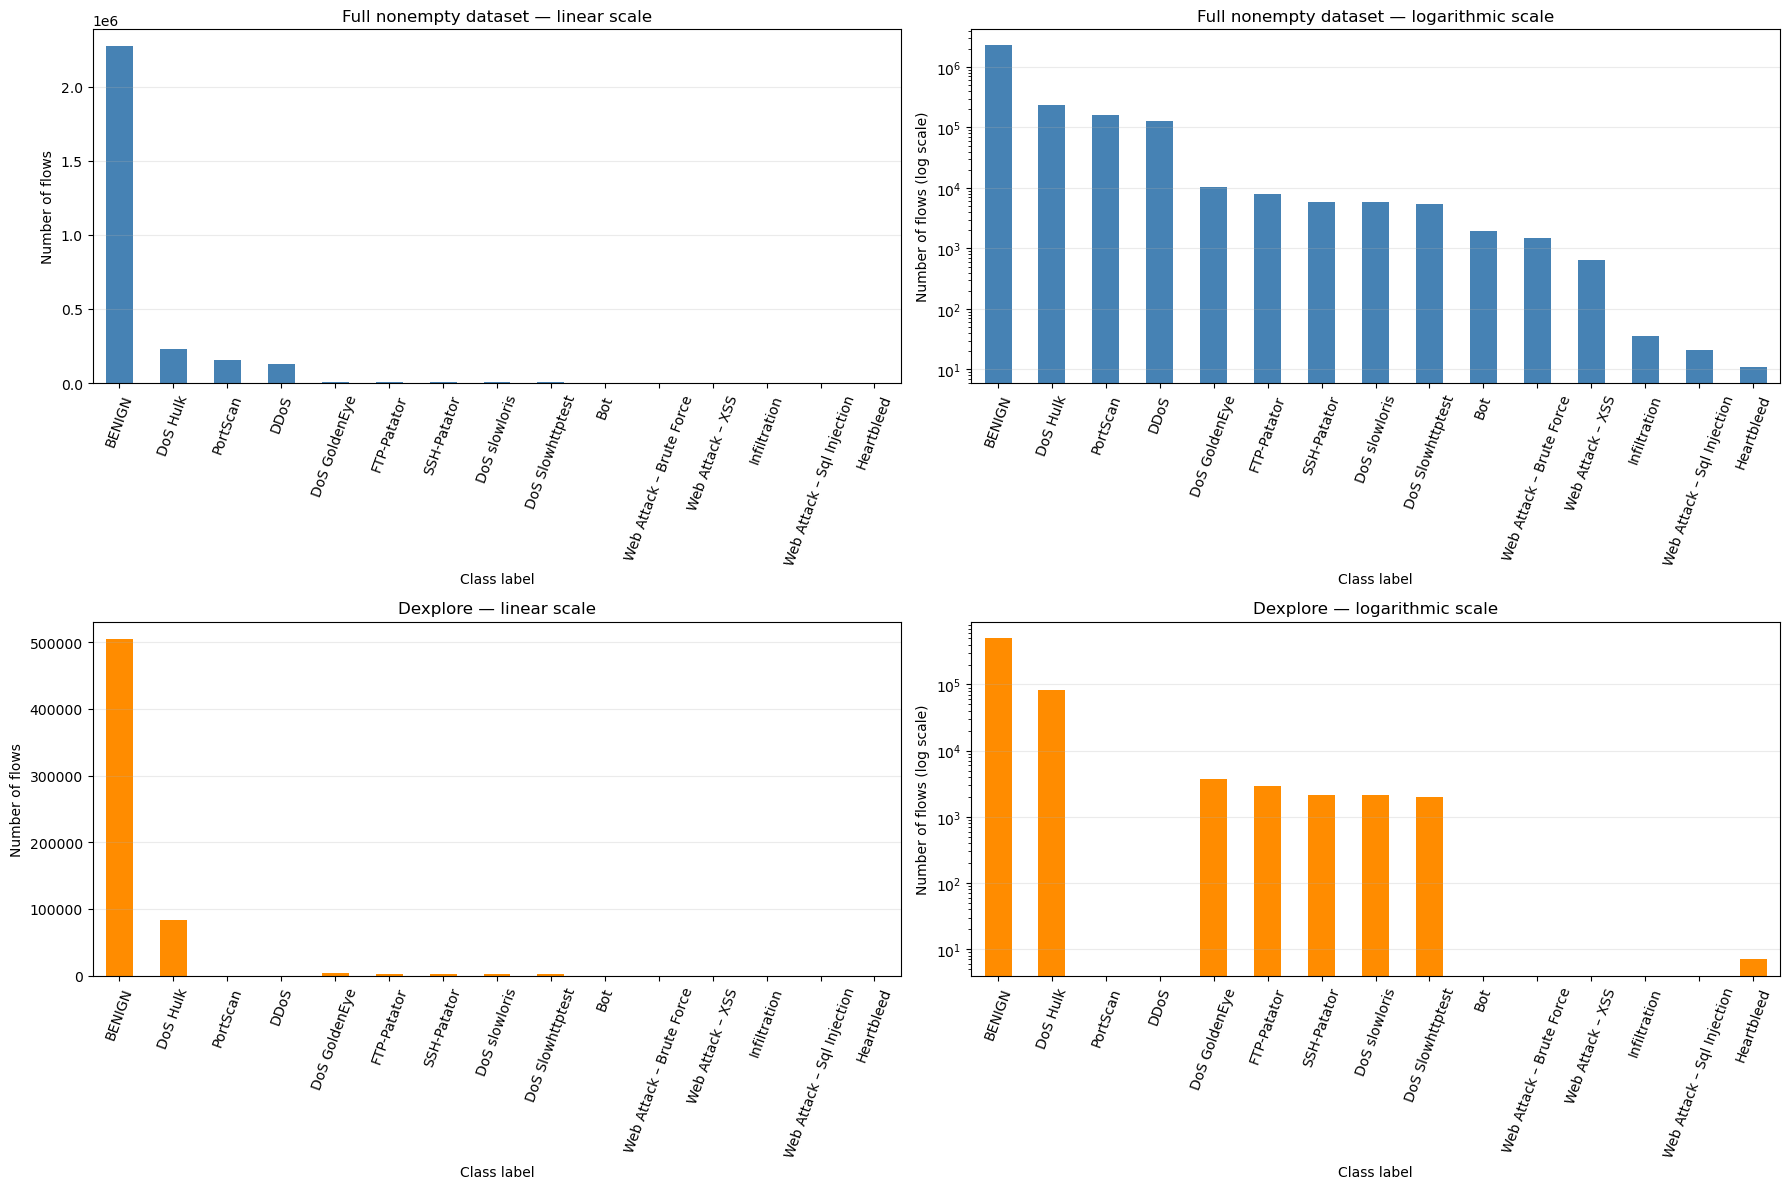

In [36]:
# Purpose: Compare full-data and Dexplore class coverage without hiding absent categories.
# Explain: An exploratory subset safe under all protocols may not represent every attack.

# ============================================================
# PART 2 — TASK 1
# DATASET SIZE, SOURCE FILES, AND CLASS BALANCE
# ============================================================

# A valid raw flow is nonempty and has a label.
# Exact duplicate copies are still included here because this
# section describes the full raw dataset.
full_nonempty_labelled_mask = (
    ~df["is_empty_record"]
    & df["Label"].notna()
)

# ------------------------------------------------------------
# 1. Overall dataset summary
# ------------------------------------------------------------
full_dataset_summary = pd.Series(
    {
        "physical_csv_records": len(df),
        "completely_empty_records": int(
            df["is_empty_record"].sum()
        ),
        "nonempty_labelled_flow_records": int(
            full_nonempty_labelled_mask.sum()
        ),
        "original_csv_columns": len(raw_columns),
        "current_working_dataframe_columns": len(df.columns),
        "added_audit_helper_columns": (
            len(df.columns) - len(raw_columns)
        ),
        "source_files": df["source_file"].nunique(),
        "distinct_labels": df.loc[
            full_nonempty_labelled_mask,
            "Label"
        ].nunique(),
        "rows_eligible_for_modeling": len(model_row_positions),
        "Dexplore_rows": len(dexplore_ids),
    },
    name="value",
    dtype="object"
)

print("FULL DATASET SUMMARY")
display(full_dataset_summary.to_frame())

# ------------------------------------------------------------
# 2. Records contributed by every source file
# ------------------------------------------------------------
physical_records_by_file = (
    df.groupby("source_file", observed=False)
    .size()
    .rename("physical_csv_records")
)

nonempty_flows_by_file = (
    df.loc[full_nonempty_labelled_mask]
    .groupby("source_file", observed=False)
    .size()
    .rename("nonempty_labelled_flows")
)

source_file_summary = pd.concat(
    [
        physical_records_by_file,
        nonempty_flows_by_file
    ],
    axis=1
).fillna(0).astype("int64")

source_file_summary["empty_records"] = (
    source_file_summary["physical_csv_records"]
    - source_file_summary["nonempty_labelled_flows"]
)

print("\nRECORDS BY SOURCE FILE")
display(source_file_summary)

# ------------------------------------------------------------
# 3. Full-dataset class counts
# ------------------------------------------------------------
full_class_counts = (
    df.loc[full_nonempty_labelled_mask, "Label"]
    .value_counts()
    .reindex(all_label_order, fill_value=0)
    .astype("int64")
    .rename("rows")
)

full_class_table = full_class_counts.to_frame()

full_class_table["percentage"] = (
    100
    * full_class_table["rows"]
    / full_class_table["rows"].sum()
)

print("\nCLASS COUNTS — FULL NONEMPTY DATASET")
display(full_class_table)

# ------------------------------------------------------------
# 4. Dexplore class counts
# ------------------------------------------------------------
# Recalculate from the saved Dexplore positions so the result
# remains directly connected to the constructed intersection.
dexplore_class_counts_task1 = (
    pd.Series(dexplore_labels)
    .value_counts()
    .reindex(all_label_order, fill_value=0)
    .astype("int64")
    .rename("rows")
)

dexplore_class_table_task1 = (
    dexplore_class_counts_task1.to_frame()
)

dexplore_class_table_task1["percentage"] = (
    100
    * dexplore_class_table_task1["rows"]
    / dexplore_class_table_task1["rows"].sum()
)

print("\nCLASS COUNTS — Dexplore")
display(dexplore_class_table_task1)

# ------------------------------------------------------------
# 5. Linear and logarithmic class-frequency plots
# ------------------------------------------------------------
import matplotlib.pyplot as plt

# Use the same label order in both scopes to make comparisons easier.
plot_label_order = (
    full_class_counts
    .sort_values(ascending=False)
    .index
)

full_plot_counts = full_class_counts.reindex(
    plot_label_order
)

dexplore_plot_counts = dexplore_class_counts_task1.reindex(
    plot_label_order
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(18, 12)
)

# Full dataset — linear scale
full_plot_counts.plot.bar(
    ax=axes[0, 0],
    color="steelblue"
)
axes[0, 0].set_title(
    "Full nonempty dataset — linear scale"
)
axes[0, 0].set_ylabel("Number of flows")

# Full dataset — logarithmic scale
full_plot_counts.plot.bar(
    ax=axes[0, 1],
    color="steelblue"
)
axes[0, 1].set_yscale("log")
axes[0, 1].set_title(
    "Full nonempty dataset — logarithmic scale"
)
axes[0, 1].set_ylabel("Number of flows (log scale)")

# Dexplore — linear scale
dexplore_plot_counts.plot.bar(
    ax=axes[1, 0],
    color="darkorange"
)
axes[1, 0].set_title(
    "Dexplore — linear scale"
)
axes[1, 0].set_ylabel("Number of flows")

# Dexplore — logarithmic scale
# Zero-count classes have no visible bar, but remain present
# in the table above.
dexplore_plot_counts.plot.bar(
    ax=axes[1, 1],
    color="darkorange"
)
axes[1, 1].set_yscale("log")
axes[1, 1].set_title(
    "Dexplore — logarithmic scale"
)
axes[1, 1].set_ylabel("Number of flows (log scale)")

for axis in axes.flat:
    axis.set_xlabel("Class label")
    axis.tick_params(
        axis="x",
        rotation=70
    )
    axis.grid(
        axis="y",
        alpha=0.25
    )

plt.tight_layout()
plt.show()

In [37]:
# Purpose: Audit non-finite values, timestamps, whitespace, and repeated headers globally.
# Explain: This establishes quality facts; fitted treatments must use the relevant training partition.

# ============================================================
# PART 2 — TASK 2
# MISSING VALUES, INFINITIES, TIMESTAMPS, AND COLUMN NAMES
# ============================================================

import csv
import re

# Include every nonempty raw record, even if another field such
# as Label happens to be missing.
nonempty_record_mask = ~df["is_empty_record"]

# ------------------------------------------------------------
# 1. Missing and non-finite values by original CSV column
# ------------------------------------------------------------
quality_records = []

for column in raw_columns:

    # Timestamp was converted during ingestion, so use the
    # preserved original text for the raw-data audit.
    if column == "Timestamp":
        values = df["Timestamp_raw"]
    else:
        values = df[column]

    nonempty_values = values.loc[nonempty_record_mask]

    missing_all_records = int(
        values.isna().sum()
    )

    missing_nonempty_records = int(
        nonempty_values.isna().sum()
    )

    positive_infinity = 0
    negative_infinity = 0

    # Infinity is meaningful only for numeric columns.
    if pd.api.types.is_numeric_dtype(values.dtype):
        numeric_values = nonempty_values.to_numpy(
            dtype=np.float64,
            na_value=np.nan
        )

        positive_infinity = int(
            np.isposinf(numeric_values).sum()
        )

        negative_infinity = int(
            np.isneginf(numeric_values).sum()
        )

    quality_records.append(
        {
            "column": column,
            "missing_all_physical_records":
                missing_all_records,
            "missing_from_empty_records":
                missing_all_records
                - missing_nonempty_records,
            "missing_within_nonempty_records":
                missing_nonempty_records,
            "positive_infinity":
                positive_infinity,
            "negative_infinity":
                negative_infinity,
        }
    )

column_quality_counts = (
    pd.DataFrame(quality_records)
    .set_index("column")
)

# Display only columns with problems inside real flow records.
# The full 85-column result remains available in
# column_quality_counts.
affected_value_columns = column_quality_counts.loc[
    (
        column_quality_counts[
            "missing_within_nonempty_records"
        ] > 0
    )
    |
    (
        column_quality_counts[
            "positive_infinity"
        ] > 0
    )
    |
    (
        column_quality_counts[
            "negative_infinity"
        ] > 0
    )
].sort_values(
    [
        "missing_within_nonempty_records",
        "positive_infinity",
        "negative_infinity",
    ],
    ascending=False
)

value_quality_summary = pd.Series(
    {
        "original_columns_audited":
            len(raw_columns),

        "completely_empty_records":
            int(df["is_empty_record"].sum()),

        "missing_cells_from_empty_records":
            int(
                column_quality_counts[
                    "missing_from_empty_records"
                ].sum()
            ),

        "additional_missing_cells_within_nonempty_records":
            int(
                column_quality_counts[
                    "missing_within_nonempty_records"
                ].sum()
            ),

        "columns_with_missing_values_in_nonempty_records":
            int(
                (
                    column_quality_counts[
                        "missing_within_nonempty_records"
                    ] > 0
                ).sum()
            ),

        "positive_infinity_values":
            int(
                column_quality_counts[
                    "positive_infinity"
                ].sum()
            ),

        "columns_containing_positive_infinity":
            int(
                (
                    column_quality_counts[
                        "positive_infinity"
                    ] > 0
                ).sum()
            ),

        "negative_infinity_values":
            int(
                column_quality_counts[
                    "negative_infinity"
                ].sum()
            ),

        "columns_containing_negative_infinity":
            int(
                (
                    column_quality_counts[
                        "negative_infinity"
                    ] > 0
                ).sum()
            ),
    },
    name="count",
    dtype="object"
)

print("MISSING AND NON-FINITE VALUE SUMMARY")
display(value_quality_summary.to_frame())

print(
    "\nCOLUMNS WITH MISSING OR NON-FINITE VALUES "
    "INSIDE NONEMPTY RECORDS"
)

if affected_value_columns.empty:
    print("None")
else:
    display(affected_value_columns)

# ------------------------------------------------------------
# 2. Malformed timestamp audit
# ------------------------------------------------------------
raw_timestamp_text = df["Timestamp_raw"]

reparsed_timestamps = pd.to_datetime(
    raw_timestamp_text,
    dayfirst=True,
    format="mixed",
    errors="coerce"
)

missing_timestamp_mask = (
    nonempty_record_mask
    & raw_timestamp_text.isna()
)

malformed_timestamp_mask = (
    nonempty_record_mask
    & raw_timestamp_text.notna()
    & reparsed_timestamps.isna()
)

timestamp_audit_summary = pd.Series(
    {
        "nonempty_records":
            int(nonempty_record_mask.sum()),

        "missing_timestamp_values":
            int(missing_timestamp_mask.sum()),

        "malformed_nonmissing_timestamp_values":
            int(malformed_timestamp_mask.sum()),

        "successfully_parsed_timestamp_values":
            int(
                (
                    nonempty_record_mask
                    & reparsed_timestamps.notna()
                ).sum()
            ),

        "timestamps_receiving_12_hour_correction":
            int(
                (
                    nonempty_record_mask
                    & df[
                        "Timestamp_adjustment_hours"
                    ].eq(12)
                ).sum()
            ),
    },
    name="count",
    dtype="object"
)

print("\nTIMESTAMP AUDIT")
display(timestamp_audit_summary.to_frame())

if malformed_timestamp_mask.any():
    print("\nExamples of malformed timestamp text:")
    display(
        df.loc[
            malformed_timestamp_mask,
            [
                "source_file",
                "source_row",
                "Timestamp_raw",
            ]
        ].head(10)
    )

# ------------------------------------------------------------
# 3. Audit the original CSV header names
# ------------------------------------------------------------
header_audit_records = []
schema_by_file = {}
duplicate_header_records = []

for file in files:
    with file.open(
        "r",
        encoding="cp1252",
        newline=""
    ) as handle:
        original_header = next(csv.reader(handle))

    stripped_header = [
        name.strip()
        for name in original_header
    ]

    normalized_header = [
        re.sub(r"\s+", " ", name.strip()).casefold()
        for name in original_header
    ]

    schema_by_file[file.name] = tuple(
        stripped_header
    )

    for position, (
        original_name,
        stripped_name,
        normalized_name
    ) in enumerate(
        zip(
            original_header,
            stripped_header,
            normalized_header
        ),
        start=1
    ):
        header_audit_records.append(
            {
                "source_file": file.name,
                "column_position": position,
                "original_name": original_name,
                "stripped_name": stripped_name,
                "normalized_name": normalized_name,
                "has_outer_whitespace": (
                    original_name != original_name.strip()
                ),
            }
        )

    stripped_name_counts = pd.Series(
        stripped_header
    ).value_counts()

    for duplicated_name, count in (
        stripped_name_counts[
            stripped_name_counts > 1
        ].items()
    ):
        duplicate_header_records.append(
            {
                "source_file": file.name,
                "duplicated_name": duplicated_name,
                "occurrences": int(count),
            }
        )

header_audit = pd.DataFrame(
    header_audit_records
)

duplicate_normalized_headers = pd.DataFrame(
    duplicate_header_records
)

reference_file = files[0].name
reference_schema = schema_by_file[reference_file]

schema_mismatch_files = [
    filename
    for filename, schema in schema_by_file.items()
    if schema != reference_schema
]

whitespace_header_issues = header_audit.loc[
    header_audit["has_outer_whitespace"],
    [
        "source_file",
        "column_position",
        "original_name",
        "stripped_name",
    ]
]

header_audit_summary = pd.Series(
    {
        "files_checked":
            len(files),

        "header_columns_per_file":
            len(reference_schema),

        "unique_names_after_stripping":
            len(set(reference_schema)),

        "files_with_schema_different_from_reference":
            len(schema_mismatch_files),

        "header_occurrences_with_outer_whitespace":
            int(
                header_audit[
                    "has_outer_whitespace"
                ].sum()
            ),

        "distinct_names_affected_by_outer_whitespace":
            int(
                whitespace_header_issues[
                    "stripped_name"
                ].nunique()
            ),

        "files_with_duplicate_names_after_stripping":
            int(
                duplicate_normalized_headers[
                    "source_file"
                ].nunique()
            )
            if not duplicate_normalized_headers.empty
            else 0,
    },
    name="count",
    dtype="object"
)

print("\nORIGINAL CSV HEADER AUDIT")
display(header_audit_summary.to_frame())

print("\nEXAMPLES OF HEADER WHITESPACE NORMALIZATION")
display(
    whitespace_header_issues.head(12)
)

print("\nDUPLICATED COLUMN NAMES AFTER STRIPPING")

if duplicate_normalized_headers.empty:
    print("None")
else:
    display(duplicate_normalized_headers)

print("\nFILES WITH A DIFFERENT STRIPPED SCHEMA")

if schema_mismatch_files:
    print(schema_mismatch_files)
else:
    print("None")

MISSING AND NON-FINITE VALUE SUMMARY


,count
original_columns_audited,85
completely_empty_records,288602
missing_cells_from_empty_records,24531170
additional_missing_cells_within_nonempty_records,1358
columns_with_missing_values_in_nonempty_records,1
positive_infinity_values,4376
columns_containing_positive_infinity,2
negative_infinity_values,0
columns_containing_negative_infinity,0



COLUMNS WITH MISSING OR NON-FINITE VALUES INSIDE NONEMPTY RECORDS


,missing_all_physical_records,missing_from_empty_records,missing_within_nonempty_records,positive_infinity,negative_infinity
column,,,,,
Flow Bytes/s,289960,288602,1358,1509,0
Flow Packets/s,288602,288602,0,2867,0



TIMESTAMP AUDIT


,count
nonempty_records,2830743
missing_timestamp_values,0
malformed_nonmissing_timestamp_values,0
successfully_parsed_timestamp_values,2830743
timestamps_receiving_12_hour_correction,1471716


... (3 outputs left out)

,source_file,column_position,original_name,stripped_name
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,2,Source IP,Source IP
2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,3,Source Port,Source Port
3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,4,Destination IP,Destination IP
4,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,5,Destination Port,Destination Port
5,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,6,Protocol,Protocol
6,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,7,Timestamp,Timestamp
7,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,8,Flow Duration,Flow Duration
8,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,9,Total Fwd Packets,Total Fwd Packets
9,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,10,Total Backward Packets,Total Backward Packets
11,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,12,Total Length of Bwd Packets,Total Length of Bwd Packets



DUPLICATED COLUMN NAMES AFTER STRIPPING


,source_file,duplicated_name,occurrences
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Fwd Header Length,2
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,Fwd Header Length,2
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,Fwd Header Length,2
3,Monday-WorkingHours.pcap_ISCX.csv,Fwd Header Length,2
4,Thursday-WorkingHours-Afternoon-Infilteration....,Fwd Header Length,2
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,Fwd Header Length,2
6,Tuesday-WorkingHours.pcap_ISCX.csv,Fwd Header Length,2
7,Wednesday-workingHours.pcap_ISCX.csv,Fwd Header Length,2



FILES WITH A DIFFERENT STRIPPED SCHEMA
None


In [38]:
# Purpose: Distinguish complete-record copies from repeated behavioral feature vectors.
# Explain: Remove complete-record extras; report behavioral repetition without erasing genuine flow frequency.

# ============================================================
# PART 2 — TASK 3
# COMPLETE-RECORD AND BEHAVIOR-ONLY DUPLICATES
# ============================================================

# Only real labelled flows participate in duplicate analysis.
auditable_flow_mask = (
    ~df["is_empty_record"]
    & df["Label"].notna()
).to_numpy()

auditable_positions = np.flatnonzero(
    auditable_flow_mask
)

# ------------------------------------------------------------
# Helper: calculate two row fingerprints in manageable chunks
# ------------------------------------------------------------
def paired_row_signatures(
    frame,
    positions,
    columns,
    chunk_size=150_000
):
    """
    Calculate two independent 64-bit fingerprints for each row.

    Fingerprints efficiently locate possible duplicates.
    Candidate rows are subsequently checked using their actual
    column values.
    """
    first_signature = np.empty(
        len(positions),
        dtype="uint64"
    )

    second_signature = np.empty(
        len(positions),
        dtype="uint64"
    )

    reversed_columns = list(
        reversed(columns)
    )

    column_positions = frame.columns.get_indexer(
        columns
    )

    reversed_column_positions = (
        frame.columns.get_indexer(
            reversed_columns
        )
    )

    for start in range(
        0,
        len(positions),
        chunk_size
    ):
        stop = min(
            start + chunk_size,
            len(positions)
        )

        row_positions = positions[start:stop]

        first_block = frame.iloc[
            row_positions,
            column_positions
        ]

        second_block = frame.iloc[
            row_positions,
            reversed_column_positions
        ]

        first_signature[start:stop] = (
            pd.util.hash_pandas_object(
                first_block,
                index=False,
                hash_key="0123456789abcdef",
            ).to_numpy(dtype="uint64")
        )

        second_signature[start:stop] = (
            pd.util.hash_pandas_object(
                second_block,
                index=False,
                hash_key="fedcba9876543210",
            ).to_numpy(dtype="uint64")
        )

    return pd.DataFrame(
        {
            "signature_1": first_signature,
            "signature_2": second_signature,
        }
    )


def repeated_signature_mask(signatures):
    """Return rows whose paired signature occurs more than once."""
    signature_counts = signatures.value_counts(
        sort=False
    )

    repeated_signatures = signature_counts[
        signature_counts > 1
    ]

    signature_index = pd.MultiIndex.from_frame(
        signatures
    )

    return signature_index.isin(
        repeated_signatures.index
    )


# ============================================================
# A. COMPLETE ORIGINAL RECORD DUPLICATES
# ============================================================

# Timestamp_raw is used so that the original timestamp text,
# rather than the corrected analytical timestamp, is compared.
complete_record_columns = [
    column
    for column in raw_columns
    if column != "Timestamp"
] + ["Timestamp_raw"]

complete_record_signatures = paired_row_signatures(
    df,
    auditable_positions,
    complete_record_columns
)

complete_candidate_mask = repeated_signature_mask(
    complete_record_signatures
)

complete_candidate_positions = auditable_positions[
    complete_candidate_mask
]

complete_candidate_values = df.iloc[
    complete_candidate_positions,
    df.columns.get_indexer(
        complete_record_columns
    )
].copy()

# Verify equality using the actual values.
complete_involved_mask = (
    complete_candidate_values.duplicated(
        subset=complete_record_columns,
        keep=False
    )
)

complete_redundant_mask = (
    complete_candidate_values.duplicated(
        subset=complete_record_columns,
        keep="first"
    )
)

complete_duplicate_positions = (
    complete_candidate_positions[
        complete_involved_mask.to_numpy()
    ]
)

complete_redundant_positions = (
    complete_candidate_positions[
        complete_redundant_mask.to_numpy()
    ]
)

complete_rows_involved = len(
    complete_duplicate_positions
)

complete_redundant_copies = len(
    complete_redundant_positions
)

complete_duplicate_groups = (
    complete_rows_involved
    - complete_redundant_copies
)

# ------------------------------------------------------------
# Recreate the audit flags used by the modeling protocols
# ------------------------------------------------------------
df["exact_duplicate_group"] = pd.Series(
    pd.NA,
    index=df.index,
    dtype="Int64"
)

df["is_redundant_exact_duplicate"] = False

# Assign group numbers only to verified complete duplicates.
complete_duplicate_values = df.iloc[
    complete_duplicate_positions,
    df.columns.get_indexer(
        complete_record_columns
    )
].copy()

complete_group_numbers = (
    complete_duplicate_values.groupby(
        complete_record_columns,
        dropna=False,
        sort=False
    ).ngroup() + 1
)

df.loc[
    complete_duplicate_positions,
    "exact_duplicate_group"
] = complete_group_numbers.to_numpy()

df.loc[
    complete_redundant_positions,
    "is_redundant_exact_duplicate"
] = True

# Keep one stable representative from each complete duplicate
# group. Behavior-only matches are NOT removed here.
model_base_mask = (
    ~df["is_empty_record"]
    & df["Label"].notna()
    & ~df["is_redundant_exact_duplicate"]
)

# If the protocols already exist in the current kernel, confirm
# that this recreated mask agrees with their modeling rows.
recreated_model_row_positions = np.flatnonzero(
    model_base_mask.to_numpy()
)

if "model_row_positions" in globals():
    assert np.array_equal(
        recreated_model_row_positions,
        model_row_positions
    ), (
        "The recreated duplicate treatment differs from the "
        "rows used by the existing splits. Rerun the protocol "
        "cells before continuing."
    )

# Check whether complete duplicates span different CSV files.
complete_duplicate_audit = pd.DataFrame(
    {
        "position": complete_duplicate_positions,
        "group": complete_group_numbers.to_numpy(),
        "source_file": df.iloc[
            complete_duplicate_positions
        ]["source_file"].to_numpy(),
    }
)

complete_groups_spanning_files = int(
    (
        complete_duplicate_audit.groupby(
            "group"
        )["source_file"].nunique() > 1
    ).sum()
)


# ============================================================
# B. DUPLICATES AFTER EXCLUDING LABEL AND METADATA
# ============================================================

metadata_and_label_columns = {
    "Flow ID",
    "Source IP",
    "Source Port",
    "Destination IP",
    "Destination Port",
    "Protocol",
    "Timestamp",
    "Label",
}

behavior_feature_columns = [
    column
    for column in raw_columns
    if column not in metadata_and_label_columns
]

behavior_signatures = paired_row_signatures(
    df,
    auditable_positions,
    behavior_feature_columns
)

behavior_candidate_mask = repeated_signature_mask(
    behavior_signatures
)

behavior_candidate_positions = auditable_positions[
    behavior_candidate_mask
]

behavior_candidate_values = df.iloc[
    behavior_candidate_positions,
    df.columns.get_indexer(
        behavior_feature_columns
    )
].copy()

# Verify exact equality across the behavioral predictors.
behavior_involved_mask = (
    behavior_candidate_values.duplicated(
        subset=behavior_feature_columns,
        keep=False
    )
)

behavior_redundant_mask = (
    behavior_candidate_values.duplicated(
        subset=behavior_feature_columns,
        keep="first"
    )
)

behavior_duplicate_positions = (
    behavior_candidate_positions[
        behavior_involved_mask.to_numpy()
    ]
)

behavior_rows_involved = len(
    behavior_duplicate_positions
)

behavior_redundant_copies = int(
    behavior_redundant_mask.sum()
)

behavior_duplicate_groups = (
    behavior_rows_involved
    - behavior_redundant_copies
)


# ============================================================
# C. SUMMARY
# ============================================================

duplicate_comparison = pd.DataFrame(
    {
        "comparison_scope": [
            "Complete original record",
            "Behavioral predictors only",
        ],
        "columns_compared": [
            len(complete_record_columns),
            len(behavior_feature_columns),
        ],
        "duplicate_groups": [
            complete_duplicate_groups,
            behavior_duplicate_groups,
        ],
        "rows_in_duplicate_groups": [
            complete_rows_involved,
            behavior_rows_involved,
        ],
        "redundant_copies": [
            complete_redundant_copies,
            behavior_redundant_copies,
        ],
        "percentage_of_nonempty_labelled_rows": [
            (
                100
                * complete_rows_involved
                / len(auditable_positions)
            ),
            (
                100
                * behavior_rows_involved
                / len(auditable_positions)
            ),
        ],
    }
).set_index("comparison_scope")

complete_duplicate_details = pd.Series(
    {
        "nonempty_labelled_rows":
            len(auditable_positions),

        "complete_duplicate_groups":
            complete_duplicate_groups,

        "rows_in_complete_duplicate_groups":
            complete_rows_involved,

        "redundant_complete_copies":
            complete_redundant_copies,

        "complete_groups_spanning_source_files":
            complete_groups_spanning_files,

        "rows_retained_for_modeling":
            int(model_base_mask.sum()),
    },
    name="count",
    dtype="object"
)

print("DUPLICATE COMPARISON")
display(duplicate_comparison)

print("\nCOMPLETE-RECORD DUPLICATE DETAILS")
display(complete_duplicate_details.to_frame())

# Free the large temporary candidate dataframes.
# The positions and signatures remain available for Task 4.
del complete_candidate_values
del behavior_candidate_values

DUPLICATE COMPARISON


,columns_compared,duplicate_groups,rows_in_duplicate_groups,redundant_copies,percentage_of_nonempty_labelled_rows
comparison_scope,,,,,
Complete original record,85,106,309,203,0.010916
Behavioral predictors only,77,91286,687933,596647,24.302206



COMPLETE-RECORD DUPLICATE DETAILS


,count
nonempty_labelled_rows,2830743
complete_duplicate_groups,106
rows_in_complete_duplicate_groups,309
redundant_complete_copies,203
complete_groups_spanning_source_files,0
rows_retained_for_modeling,2830540


## Why we do not remove all 596,647

Removing them would change the meaning of the dataset.

Suppose an attack tool sends the same malicious request 10,000 times. Those are separate events, even when their summarized features are identical. Frequency itself may be operationally important.

Automatically retaining only one would make frequent behaviors appear as rare as occasional behaviors. Therefore:

- Complete copied records: redundant copies are excluded.
- Separate flows with matching behavior: retained and investigated.

The high repetition should still be reported because models can be influenced by it:

- kNN may have many identical neighbours.
- A decision tree may form rules around repeated patterns.
- Logistic regression may give heavily repeated patterns more influence.
- Random evaluation may appear easier when the same feature vector occurs in both training and testing.

In [40]:
# Purpose: Identify repeated behavioral vectors carrying more than one label.
# Explain: Conflicts show ambiguity in this representation; they do not prove which label is wrong.

# ============================================================
# PART 2 — TASK 4
# IDENTICAL PREDICTORS WITH DIFFERENT LABELS
# ============================================================

# Get the verified behavior-only duplicate signatures.
duplicate_signatures = (
    behavior_signatures.loc[behavior_candidate_mask]
    .reset_index(drop=True)
)

verified_signatures = (
    duplicate_signatures.loc[
        behavior_involved_mask.to_numpy()
    ]
    .reset_index(drop=True)
)

# Give every identical feature vector a group number.
behavior_groups = pd.factorize(
    pd.MultiIndex.from_frame(verified_signatures)
)[0]

conflict_data = pd.DataFrame({
    "group": behavior_groups,
    "Label": df.iloc[
        behavior_duplicate_positions
    ]["Label"].to_numpy()
})

# Collect the distinct labels found in each group.
group_labels = conflict_data.groupby("group")["Label"].agg(
    lambda labels: tuple(sorted(set(labels)))
)

# A conflict has more than one distinct label.
conflicting_groups = group_labels[
    group_labels.map(len) > 1
]

conflicting_rows = conflict_data[
    conflict_data["group"].isin(
        conflicting_groups.index
    )
]

conflict_summary = pd.Series({
    "conflicting_feature_groups":
        len(conflicting_groups),

    "rows_in_conflicting_groups":
        len(conflicting_rows),

    "percentage_of_labelled_rows":
        100 * len(conflicting_rows) / len(auditable_positions),
}, name="count")

conflict_combinations = (
    conflicting_groups
    .map(lambda labels: " <-> ".join(labels))
    .value_counts()
    .rename("groups")
)

display(conflict_summary.to_frame())
display(conflict_combinations.to_frame())

,count
conflicting_feature_groups,271.000000
rows_in_conflicting_groups,82868.000000
percentage_of_labelled_rows,2.927429


,groups
Label,
BENIGN <-> DoS Hulk,134
BENIGN <-> PortScan,107
BENIGN <-> Bot,25
BENIGN <-> DDoS,3
BENIGN <-> DoS slowloris,2


a **feature vector** is the vector formed from the 77 behavioral feature values for one flow:

x⁽ⁱ⁾ = \[x₁⁽ⁱ⁾,x₂⁽ⁱ⁾,…,x₇₇⁽ⁱ⁾\]

For example, part of a flow’s vector might look like:

```
[
    Flow Duration,
    Total Fwd Packets,
    Total Backward Packets,
    Flow Bytes/s,
    Flow Packets/s,
    Packet Length Mean,
    SYN Flag Count,
    Active Mean,
    Idle Mean,
    ...
]
```

For Task 4, we excluded:

- `Label`
- Flow ID
- IP addresses
- Ports
- Protocol
- Timestamp
- Source-file and row identifiers

Then we asked whether two rows have exactly the same values across **all 77 behavioral features**.

A conflict looks like this:

```
Flow A:
behavior vector = [100, 2, 1, 450.0, ..., 0]
label = BENIGN

Flow B:
behavior vector = [100, 2, 1, 450.0, ..., 0]
label = DoS Hulk
```

The model receives the same input vector x, but two different expected outputs:

x → BENIGN

x → DoS Hulk

A deterministic behavior-only classifier cannot classify both correctly because it has no input feature that distinguishes them.

The flows may still differ in excluded metadata—such as IP address, timestamp or port. A metadata-based model could distinguish them, but it would potentially be learning the collection scenario rather than the attack’s behavior.

FEATURE RANGES BY CLASS


Flow Duration                           Total Fwd Packets  \
                           min       median          max               min   
Label                                                                        
BENIGN                     0.0      31219.0  119999998.0               1.0   
DoS GoldenEye            814.0   11560146.0  119563670.0               2.0   
DoS Hulk                   0.0   84927135.5  119968626.0               1.0   
DoS Slowhttptest           1.0   63115823.0  119800027.0               1.0   
DoS slowloris              2.0   77154563.0  119016255.0               1.0   
FTP-Patator                1.0        361.0   10515308.0               1.0   
Heartbleed          24719667.0  119260295.0  119299621.0             590.0   
SSH-Patator                1.0        955.5   19582015.0               1.0   

                                   Packet Length Mean               \
                  median       max                min       median   
Label                                                                
BENIGN               2.0  219759.0            0.00000    60.200000   
DoS GoldenEye        7.0      20.0            0.00000   448.944444   
DoS Hulk             6.0      15.0            0.00000   796.666667   
DoS Slowhttptest     7.0      19.0            0.00000     0.000000   
DoS slowloris        3.0      16.0            0.00000     5.333333   
FTP-Patator          2.0       9.0            0.00000     9.333333   
Heartbleed        2794.0    2805.0         1603.27797  1609.782307   
SSH-Patator          2.0      33.0            0.00000     2.285714   

                              Flow Packets/s                             
                          max            min       median           max  
Label                                                                    
BENIGN            2920.000000       0.016740   111.152279  3.000000e+06  
DoS GoldenEye     1025.583333       0.016727     1.006621  2.457002e+03  
DoS Hulk          1501.125000       0.017486     0.162663  3.000000e+06  
DoS Slowhttptest  1322.000000       0.063637     0.110916  2.000000e+06  
DoS slowloris      651.333333       0.025890     0.179876  1.000000e+06  
FTP-Patator         12.920000       2.282387  8311.269713  3.000000e+06  
Heartbleed        1633.870707      40.511445    41.102708  4.150541e+01  
SSH-Patator        136.391304       3.462777  4257.246377  2.000000e+06

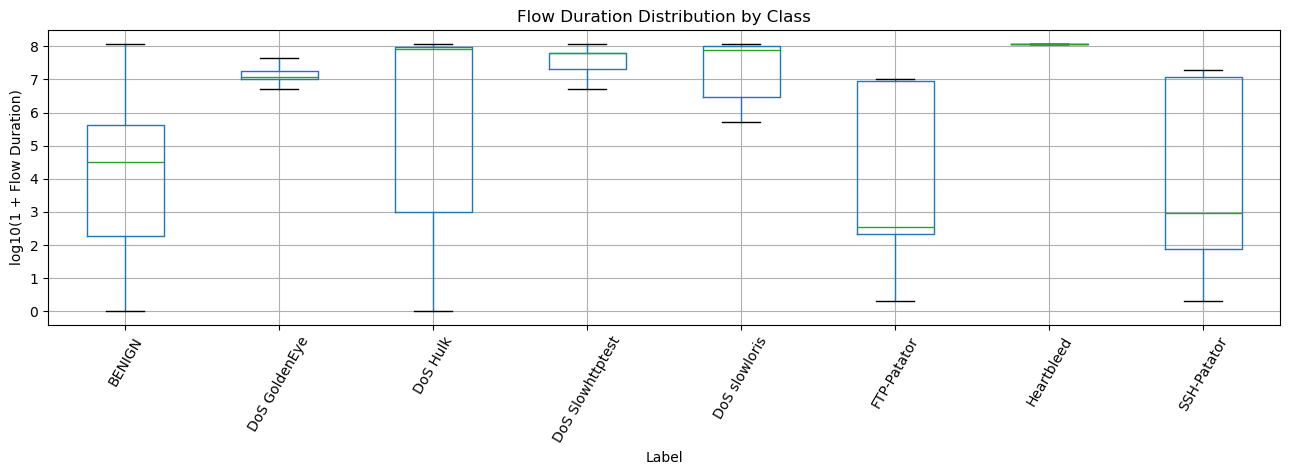

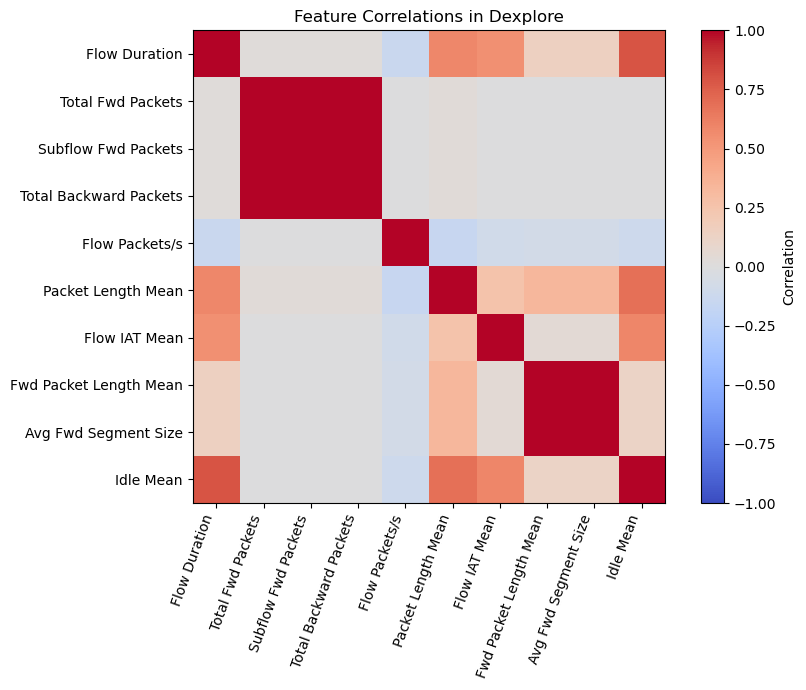

STRONG CORRELATIONS


,,correlation
Total Fwd Packets,Subflow Fwd Packets,1.000000
Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000
Total Fwd Packets,Total Backward Packets,0.998597
Subflow Fwd Packets,Total Backward Packets,0.998597


POTENTIALLY REDUNDANT FEATURE PAIRS


,first_feature,second_feature,identical_rows_percentage
0,Fwd Header Length,Fwd Header Length.1,100.000000
1,Fwd Packet Length Mean,Avg Fwd Segment Size,96.772677
2,Bwd Packet Length Mean,Avg Bwd Segment Size,97.746157
3,Total Fwd Packets,Subflow Fwd Packets,100.000000
4,Total Backward Packets,Subflow Bwd Packets,100.000000
5,Total Length of Fwd Packets,Subflow Fwd Bytes,100.000000
6,Total Length of Bwd Packets,Subflow Bwd Bytes,99.995514


In [41]:
# Purpose: Inspect feature ranges and class distributions using Dexplore only.
# Explain: Plots can influence modeling, so validation/test rows are excluded under every protocol.

range_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Packet Length Mean",
    "Flow Packets/s",
]

correlation_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Subflow Fwd Packets",
    "Total Backward Packets",
    "Flow Packets/s",
    "Packet Length Mean",
    "Flow IAT Mean",
    "Fwd Packet Length Mean",
    "Avg Fwd Segment Size",
    "Idle Mean",
]

redundant_pairs = [
    ("Fwd Header Length", "Fwd Header Length.1"),
    ("Fwd Packet Length Mean", "Avg Fwd Segment Size"),
    ("Bwd Packet Length Mean", "Avg Bwd Segment Size"),
    ("Total Fwd Packets", "Subflow Fwd Packets"),
    ("Total Backward Packets", "Subflow Bwd Packets"),
    ("Total Length of Fwd Packets", "Subflow Fwd Bytes"),
    ("Total Length of Bwd Packets", "Subflow Bwd Bytes"),
]

required_columns = list(dict.fromkeys(
    ["Label"]
    + range_features
    + correlation_features
    + [column for pair in redundant_pairs for column in pair]
))

explore_data = df.iloc[
    dexplore_df_positions
][required_columns].copy()

# Infinity cannot be used in descriptive calculations.
# It is temporarily treated as missing; the raw data is unchanged.
explore_data.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

# 1. Feature ranges by class
feature_ranges = explore_data.groupby("Label")[
    range_features
].agg(["min", "median", "max"])

print("FEATURE RANGES BY CLASS")
display(feature_ranges)

# 2. Flow-duration distribution by class
duration_plot = explore_data[
    ["Label", "Flow Duration"]
].dropna().copy()

duration_plot["Log Flow Duration"] = np.log10(
    1 + duration_plot["Flow Duration"].clip(lower=0)
)

duration_plot.boxplot(
    column="Log Flow Duration",
    by="Label",
    figsize=(13, 5),
    showfliers=False,
    rot=60
)

plt.title("Flow Duration Distribution by Class")
plt.suptitle("")
plt.ylabel("log10(1 + Flow Duration)")
plt.tight_layout()
plt.show()

# 3. Correlation matrix
correlation_matrix = explore_data[
    correlation_features
].corr()

fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation_features)))
ax.set_yticks(range(len(correlation_features)))

ax.set_xticklabels(
    correlation_features,
    rotation=70,
    ha="right"
)
ax.set_yticklabels(correlation_features)

fig.colorbar(image, ax=ax, label="Correlation")
ax.set_title("Feature Correlations in Dexplore")

plt.tight_layout()
plt.show()

# Display correlations with absolute value of at least 0.95.
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

strong_correlations = (
    upper_triangle.stack()
    .rename("correlation")
    .to_frame()
)

strong_correlations = strong_correlations[
    strong_correlations["correlation"].abs() >= 0.95
].sort_values(
    "correlation",
    key=abs,
    ascending=False
)

print("STRONG CORRELATIONS")
display(strong_correlations)

# 4. Check known redundant pairs
redundancy_results = []

for first, second in redundant_pairs:
    equal_percentage = 100 * (
        explore_data[first].eq(explore_data[second])
        |
        (
            explore_data[first].isna()
            & explore_data[second].isna()
        )
    ).mean()

    redundancy_results.append({
        "first_feature": first,
        "second_feature": second,
        "identical_rows_percentage": equal_percentage,
    })

redundancy_table = pd.DataFrame(
    redundancy_results
)

print("POTENTIALLY REDUNDANT FEATURE PAIRS")
display(redundancy_table)

### Interpretation

Flow duration differs substantially between classes. Slow DoS attacks, GoldenEye and Heartbleed generally have long flows, while FTP-Patator and SSH-Patator have much shorter flows. Heartbleed also has unusually large packet counts and packet sizes, but this observation is based on only 7 Dexplore examples and is therefore uncertain.

The distributions still overlap, so no single feature can reliably determine the class. Some differences may reflect the attack mechanism, while others may reflect the specific attack tool or capture conditions.

Several features contain duplicate or nearly duplicate information. `Fwd Header Length` and `Fwd Header Length.1`, total and subflow packet counts, and total and subflow byte counts are fully or almost fully redundant. Forward and backward packet counts are also strongly correlated.

For later modeling, one representative from each redundant group can be retained. The final decision must be confirmed using each protocol's training data. Scaling will also be necessary for logistic regression and kNN because feature ranges differ greatly.

In [42]:
# Purpose: Identify constants and near constants separately within each training partition.
# Explain: Remove constants; initially retain rare-valued flags because rare events may be informative.

# ============================================================
# PART 2 — TASK 6
# CONSTANT AND NEARLY CONSTANT FEATURES
# ============================================================

NEAR_CONSTANT_THRESHOLD = 99.0

protocol_training_positions = {
    "Random": train_random_positions,
    "Grouped": train_grouped_positions,
    "Chronological": np.flatnonzero(
        train_chronological_mask.to_numpy()
    ),
}

constant_results = []

for protocol, training_positions in protocol_training_positions.items():

    dataframe_positions = model_row_positions[
        training_positions
    ]

    for feature in behavior_feature_columns:

        values = (
            df[feature]
            .iloc[dataframe_positions]
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        value_counts = values.value_counts()
        unique_values = len(value_counts)

        if unique_values == 0:
            status = "Constant"
            dominant_percentage = 100.0

        else:
            dominant_percentage = (
                100 * value_counts.iloc[0] / len(values)
            )

            if unique_values == 1:
                status = "Constant"

            elif dominant_percentage >= NEAR_CONSTANT_THRESHOLD:
                status = "Nearly constant"

            else:
                continue

        constant_results.append({
            "protocol": protocol,
            "feature": feature,
            "status": status,
            "dominant_value_percentage": dominant_percentage,
        })

constant_feature_table = pd.DataFrame(
    constant_results
).sort_values(
    ["protocol", "status", "dominant_value_percentage"],
    ascending=[True, True, False]
)

constant_feature_summary = pd.crosstab(
    constant_feature_table["protocol"],
    constant_feature_table["status"]
).reindex(
    index=["Random", "Grouped", "Chronological"],
    columns=["Constant", "Nearly constant"],
    fill_value=0
)

print("NUMBER OF FEATURES")
display(constant_feature_summary)

print("CONSTANT AND NEARLY CONSTANT FEATURES")
display(constant_feature_table)

NUMBER OF FEATURES


status,Constant,Nearly constant
protocol,,
Random,8,4
Grouped,8,4
Chronological,10,2


CONSTANT AND NEARLY CONSTANT FEATURES


,protocol,feature,status,dominant_value_percentage
24,Chronological,Bwd PSH Flags,Constant,100.000000
25,Chronological,Fwd URG Flags,Constant,100.000000
26,Chronological,Bwd URG Flags,Constant,100.000000
28,Chronological,CWE Flag Count,Constant,100.000000
30,Chronological,Fwd Avg Bytes/Bulk,Constant,100.000000
31,Chronological,Fwd Avg Packets/Bulk,Constant,100.000000
32,Chronological,Fwd Avg Bulk Rate,Constant,100.000000
33,Chronological,Bwd Avg Bytes/Bulk,Constant,100.000000
34,Chronological,Bwd Avg Packets/Bulk,Constant,100.000000
35,Chronological,Bwd Avg Bulk Rate,Constant,100.000000


Constant features provide no discrimination and will be removed from that protocol's model. Nearly constant features are retained initially because their rare values may still represent important network events or attacks.

In [43]:
# Purpose: Summarize quality problems, their counts, and the declared treatments.
# Explain: Document what is removed, transformed, or retained instead of silently changing the data.

# ============================================================
# PART 2 — TASK 7
# DATA-QUALITY PROBLEM AND TREATMENT TABLE
# ============================================================

data_quality_table = pd.DataFrame([
    {
        "problem": "Completely empty CSV records",
        "affected": f"{int(df['is_empty_record'].sum()):,} rows",
        "treatment": "Exclude from modeling; retain the audit count",
        "justification": "They contain no network-flow information",
    },
    {
        "problem": "Missing Flow Bytes/s",
        "affected": "1,358 rows",
        "treatment": "Impute using the training-set median",
        "justification": "Most models cannot use missing numeric values",
    },
    {
        "problem": "Positive infinity",
        "affected": "4,376 values in 2 columns",
        "treatment": "Convert to missing, then apply training-set imputation",
        "justification": "Models cannot use infinite values",
    },
    {
        "problem": "Ambiguous 12-hour timestamps",
        "affected": "1,471,716 rows",
        "treatment": "Apply the documented 12-hour correction and preserve the raw text",
        "justification": "The CSV omits AM/PM for afternoon traffic",
    },
    {
        "problem": "Invalid timing for chronological splitting",
        "affected": "115 rows",
        "treatment": "Flag and exclude from chronological partitions",
        "justification": "A valid flow end time cannot be calculated",
    },
    {
        "problem": "Outer whitespace in column names",
        "affected": "69 distinct names",
        "treatment": "Strip leading and trailing whitespace",
        "justification": "Prevents equivalent columns from receiving different names",
    },
    {
        "problem": "Duplicated Fwd Header Length column",
        "affected": "1 duplicated feature in all 8 files",
        "treatment": "Retain one copy after confirming equality in training",
        "justification": "Both columns contain the same information",
    },
    {
        "problem": "Complete-record duplicates",
        "affected": f"{complete_redundant_copies:,} redundant rows",
        "treatment": "Retain one stable representative per group",
        "justification": "Prevents duplicate weighting and train-test duplication",
    },
    {
        "problem": "Repeated behavioral vectors",
        "affected": f"{behavior_rows_involved:,} rows",
        "treatment": "Retain and document",
        "justification": "Separate flows can legitimately have identical summaries",
    },
    {
        "problem": "Identical predictors with conflicting labels",
        "affected": f"{len(conflicting_rows):,} rows in {len(conflicting_groups):,} groups",
        "treatment": "Retain and report the ambiguity",
        "justification": "The available behavioral features cannot resolve the conflict",
    },
    {
        "problem": "Severe class imbalance",
        "affected": f"Rarest full-data class has {int(full_class_counts.min()):,} rows",
        "treatment": "Use macro-F1, class recall and training-only balancing methods",
        "justification": "Accuracy and weighted metrics can hide rare-class failure",
    },
    {
        "problem": "Classes absent from Dexplore",
        "affected": f"{len(dexplore_absent_classes)} classes",
        "treatment": "Limit exploratory conclusions to represented classes",
        "justification": "Dexplore contains only rows training-safe under every protocol",
    },
    {
        "problem": "Constant features",
        "affected": "Random: 8; Grouped: 8; Chronological: 10",
        "treatment": "Remove separately using each protocol's training data",
        "justification": "A constant feature cannot distinguish observations",
    },
    {
        "problem": "Nearly constant features",
        "affected": "Random: 4; Grouped: 4; Chronological: 2",
        "treatment": "Retain initially and monitor",
        "justification": "Rare values may contain security-relevant information",
    },
    {
        "problem": "Strongly redundant features",
        "affected": f"{len(redundant_pairs)} investigated pairs",
        "treatment": "Retain one representative from each confirmed redundant group",
        "justification": "Repeated information can distort distance and coefficient-based models",
    },
])

display(data_quality_table)

,problem,affected,treatment,justification
0,Completely empty CSV records,"288,602 rows",Exclude from modeling; retain the audit count,They contain no network-flow information
1,Missing Flow Bytes/s,"1,358 rows",Impute using the training-set median,Most models cannot use missing numeric values
2,Positive infinity,"4,376 values in 2 columns","Convert to missing, then apply training-set im...",Models cannot use infinite values
3,Ambiguous 12-hour timestamps,"1,471,716 rows",Apply the documented 12-hour correction and pr...,The CSV omits AM/PM for afternoon traffic
4,Invalid timing for chronological splitting,115 rows,Flag and exclude from chronological partitions,A valid flow end time cannot be calculated
5,Outer whitespace in column names,69 distinct names,Strip leading and trailing whitespace,Prevents equivalent columns from receiving dif...
6,Duplicated Fwd Header Length column,1 duplicated feature in all 8 files,Retain one copy after confirming equality in t...,Both columns contain the same information
7,Complete-record duplicates,203 redundant rows,Retain one stable representative per group,Prevents duplicate weighting and train-test du...
8,Repeated behavioral vectors,"687,933 rows",Retain and document,Separate flows can legitimately have identical...
9,Identical predictors with conflicting labels,"82,868 rows in 271 groups",Retain and report the ambiguity,The available behavioral features cannot resol...


# Part 3: Explore network behavior

## 3.1 Selected attacks

We selected **FTP-Patator** and **DoS slowloris** because they represent different attack mechanisms and both have enough examples in Dexplore.

- **FTP-Patator** is an authentication brute-force attack that repeatedly attempts FTP logins.
- **DoS slowloris** is a denial-of-service attack that attempts to occupy server resources using long, slowly communicating connections.

Dexplore contains 2,890 FTP-Patator flows and 2,119 DoS slowloris flows. Each attack will be compared with benign traffic using behavioral features only.

## 3.2 Behavioral hypotheses

### FTP-Patator hypothesis

FTP-Patator repeatedly performs authentication attempts. We expect individual flows to be relatively short, contain few packets, and potentially have high packet rates compared with benign traffic.

The repetition happens across many flows, so one flow alone does not prove brute force.

### Slowloris hypothesis

Slowloris attempts to keep connections open while communicating slowly. We expect longer durations, lower packet rates, and larger inter-arrival or idle times than benign traffic.

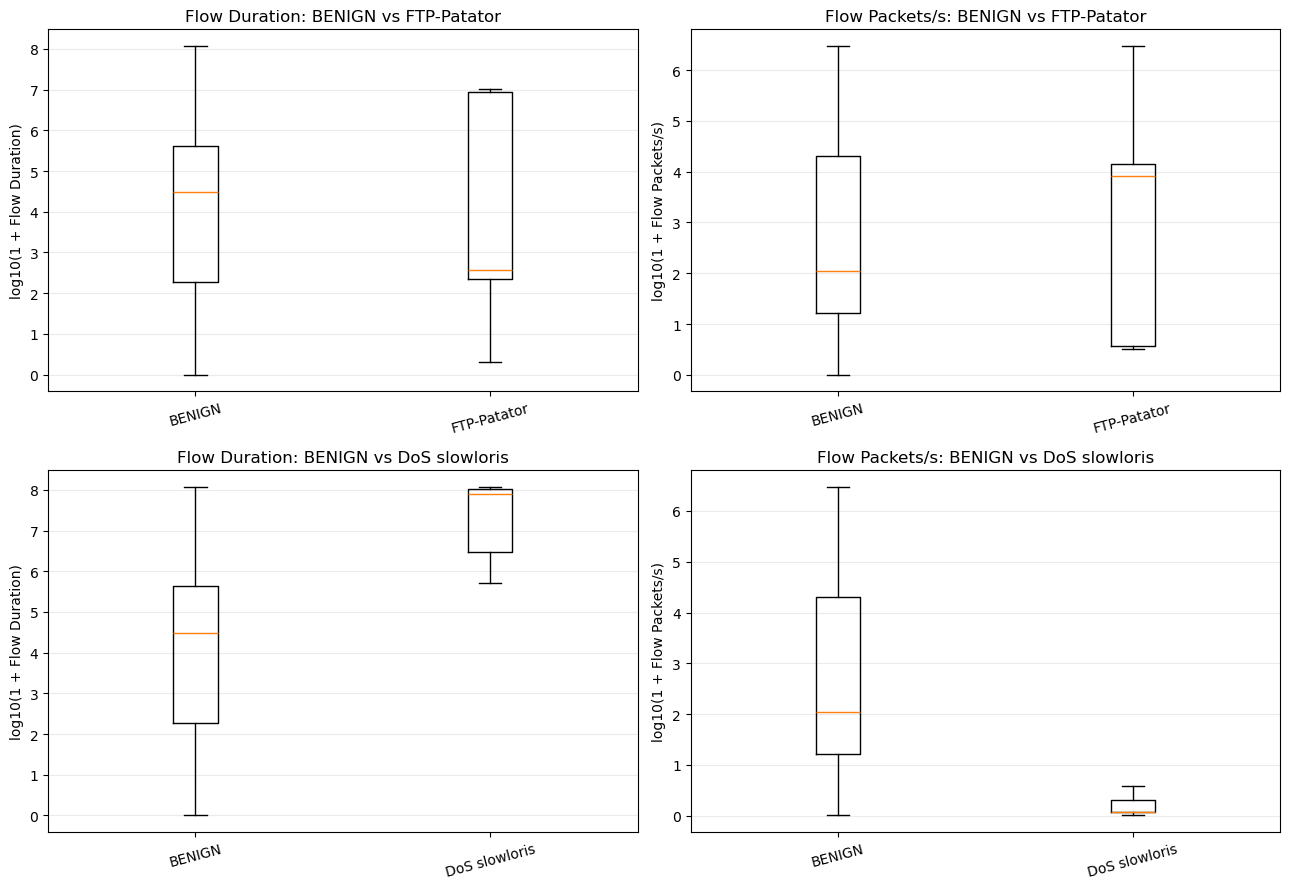

In [44]:
# Purpose: Check FTP-Patator and slowloris hypotheses against Dexplore distributions.
# Explain: Short rapid exchanges and long slow connections are consistent evidence, not proof of transfer.


# ============================================================
# PART 3 — TASK 3
# BEHAVIORAL DISTRIBUTIONS
# ============================================================

part3_data = df.iloc[dexplore_df_positions][
    ["Label", "Flow Duration", "Flow Packets/s"]
].copy()

part3_data.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

plot_comparisons = [
    ("FTP-Patator", "Flow Duration"),
    ("FTP-Patator", "Flow Packets/s"),
    ("DoS slowloris", "Flow Duration"),
    ("DoS slowloris", "Flow Packets/s"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (attack, feature) in zip(
    axes.flat,
    plot_comparisons
):
    benign_values = (
        part3_data.loc[
            part3_data["Label"] == "BENIGN",
            feature
        ]
        .dropna()
        .clip(lower=0)
    )

    attack_values = (
        part3_data.loc[
            part3_data["Label"] == attack,
            feature
        ]
        .dropna()
        .clip(lower=0)
    )

    ax.boxplot(
        [
            np.log10(1 + benign_values),
            np.log10(1 + attack_values),
        ],
        tick_labels=["BENIGN", attack],
        showfliers=False
    )

    ax.set_title(f"{feature}: BENIGN vs {attack}")
    ax.set_ylabel(f"log10(1 + {feature})")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## 3.4 Observations and competing explanations

### FTP-Patator

FTP-Patator flows generally have shorter durations and higher packet rates than benign flows. This is consistent with repeated, rapid authentication attempts. However, the distributions are broad and overlap with benign traffic, so these features cannot identify FTP brute force on their own.

An alternative explanation is that the observed pattern reflects how the Patator tool opens and closes connections in this experiment rather than a general property of every FTP brute-force implementation.

### DoS slowloris

DoS slowloris flows have substantially longer durations and much lower packet rates than benign flows. This strongly supports the hypothesis that Slowloris maintains connections while communicating slowly.

A competing explanation is that the strong separation may partly result from the specific Slowloris implementation, the controlled server configuration, or CICFlowMeter's flow-timeout rules. The result therefore supports the proposed mechanism but does not prove generalization to other networks or tools.

In [45]:
# Purpose: Prepare the random-protocol baseline predictors and aligned binary/multiclass targets.
# Explain: Remove training constants and declared redundancies; preserve the previously saved memberships.

# ============================================================
# PART 4.1 — FEATURES AND LABELS
# ============================================================

# Remove features that were constant in random training.
random_constant_features = constant_feature_table.loc[
    (constant_feature_table["protocol"] == "Random")
    & (constant_feature_table["status"] == "Constant"),
    "feature"
].tolist()

# Remove one feature from each confirmed redundant pair.
redundant_features_to_remove = [
    "Fwd Header Length.1",
    "Avg Fwd Segment Size",
    "Avg Bwd Segment Size",
    "Subflow Fwd Packets",
    "Subflow Bwd Packets",
    "Subflow Fwd Bytes",
    "Subflow Bwd Bytes",
]

baseline_features = [
    feature
    for feature in behavior_feature_columns
    if feature not in (
        random_constant_features
        + redundant_features_to_remove
    )
]

# Dataframe positions for the random protocol.
random_train_df_positions = model_row_positions[
    train_random_positions
]

random_validation_df_positions = model_row_positions[
    validation_random_positions
]

random_test_df_positions = model_row_positions[
    test_random_positions
]

# Multiclass labels.
y_train_multiclass = model_labels[
    train_random_positions
]

y_validation_multiclass = model_labels[
    validation_random_positions
]

y_test_multiclass = model_labels[
    test_random_positions
]

# Binary labels: BENIGN = 0, ATTACK = 1.
y_train_binary = np.where(
    y_train_multiclass == "BENIGN", 0, 1
)

y_validation_binary = np.where(
    y_validation_multiclass == "BENIGN", 0, 1
)

y_test_binary = np.where(
    y_test_multiclass == "BENIGN", 0, 1
)

part4_setup_summary = pd.Series({
    "original_behavioral_features":
        len(behavior_feature_columns),

    "constant_features_removed":
        len(random_constant_features),

    "redundant_features_removed":
        len(redundant_features_to_remove),

    "features_retained":
        len(baseline_features),

    "training_rows":
        len(random_train_df_positions),

    "validation_rows":
        len(random_validation_df_positions),

    "test_rows":
        len(random_test_df_positions),
}, name="value")

binary_class_counts = pd.DataFrame({
    "train": pd.Series(y_train_binary).value_counts(),
    "validation": pd.Series(y_validation_binary).value_counts(),
    "test": pd.Series(y_test_binary).value_counts(),
}).rename(
    index={0: "BENIGN", 1: "ATTACK"}
)

display(part4_setup_summary.to_frame())
display(binary_class_counts)

,value
original_behavioral_features,77
constant_features_removed,8
redundant_features_removed,7
features_retained,62
training_rows,1698324
validation_rows,566108
test_rows,566108


,train,validation,test
BENIGN,1363737,454579,454579
ATTACK,334587,111529,111529


,balanced_accuracy,macro_f1,weighted_f1
task,,,
Binary,0.500000,0.445366,0.715248
Multiclass,0.066667,0.059382,0.715248


BINARY CLASS-WISE RECALL


,recall
BENIGN,1.0
ATTACK,0.0


MULTICLASS CLASS-WISE RECALL


,recall
Label,
BENIGN,1.0
Bot,0.0
DDoS,0.0
DoS GoldenEye,0.0
DoS Hulk,0.0
DoS Slowhttptest,0.0
DoS slowloris,0.0
FTP-Patator,0.0
Heartbleed,0.0


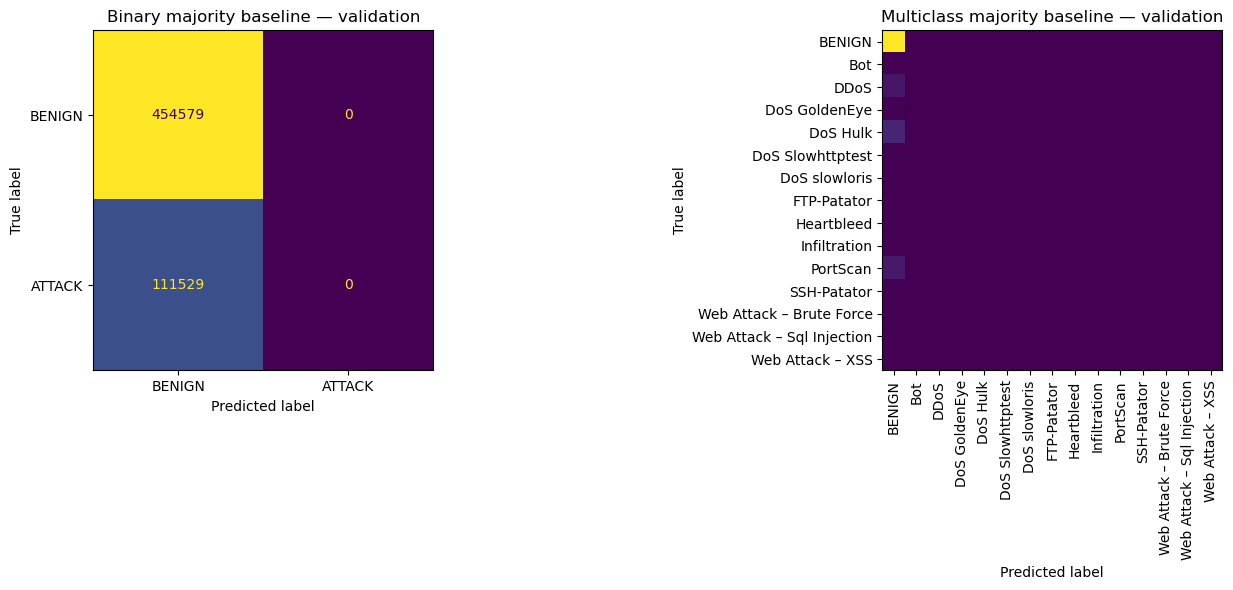

In [46]:
# Purpose: Establish majority-class predictions as an imbalance-aware reference.
# Explain: A high weighted score can coexist with zero attack recall; inspect per-class metrics.

# ============================================================
# PART 4.2 — MAJORITY-CLASS BASELINE
# ============================================================

from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    recall_score,
    ConfusionMatrixDisplay,
)

# Most common training labels.
binary_majority_label = pd.Series(
    y_train_binary
).mode()[0]

multiclass_majority_label = pd.Series(
    y_train_multiclass
).mode()[0]

# Predict the majority label for every validation row.
binary_majority_predictions = np.full(
    len(y_validation_binary),
    binary_majority_label
)

multiclass_majority_predictions = np.full(
    len(y_validation_multiclass),
    multiclass_majority_label,
    dtype=object
)

# Required validation metrics.
majority_results = pd.DataFrame({
    "task": ["Binary", "Multiclass"],

    "balanced_accuracy": [
        balanced_accuracy_score(
            y_validation_binary,
            binary_majority_predictions
        ),
        balanced_accuracy_score(
            y_validation_multiclass,
            multiclass_majority_predictions
        ),
    ],

    "macro_f1": [
        f1_score(
            y_validation_binary,
            binary_majority_predictions,
            average="macro",
            zero_division=0
        ),
        f1_score(
            y_validation_multiclass,
            multiclass_majority_predictions,
            average="macro",
            zero_division=0
        ),
    ],

    "weighted_f1": [
        f1_score(
            y_validation_binary,
            binary_majority_predictions,
            average="weighted",
            zero_division=0
        ),
        f1_score(
            y_validation_multiclass,
            multiclass_majority_predictions,
            average="weighted",
            zero_division=0
        ),
    ],
}).set_index("task")

display(majority_results)

# Class-wise recall.
binary_recall = pd.Series(
    recall_score(
        y_validation_binary,
        binary_majority_predictions,
        labels=[0, 1],
        average=None,
        zero_division=0
    ),
    index=["BENIGN", "ATTACK"],
    name="recall"
)

multiclass_recall = pd.Series(
    recall_score(
        y_validation_multiclass,
        multiclass_majority_predictions,
        labels=all_label_order,
        average=None,
        zero_division=0
    ),
    index=all_label_order,
    name="recall"
)

print("BINARY CLASS-WISE RECALL")
display(binary_recall.to_frame())

print("MULTICLASS CLASS-WISE RECALL")
display(multiclass_recall.to_frame())

# Validation confusion matrices.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(
    y_validation_binary,
    binary_majority_predictions,
    labels=[0, 1],
    display_labels=["BENIGN", "ATTACK"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Binary majority baseline — validation")

ConfusionMatrixDisplay.from_predictions(
    y_validation_multiclass,
    multiclass_majority_predictions,
    labels=all_label_order,
    display_labels=all_label_order,
    include_values=False,
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Multiclass majority baseline — validation")
axes[1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

,validation
balanced_accuracy,0.934664
attack_f1,0.848751
macro_f1,0.903407
weighted_f1,0.936528


,recall
BENIGN,0.934119
ATTACK,0.935210


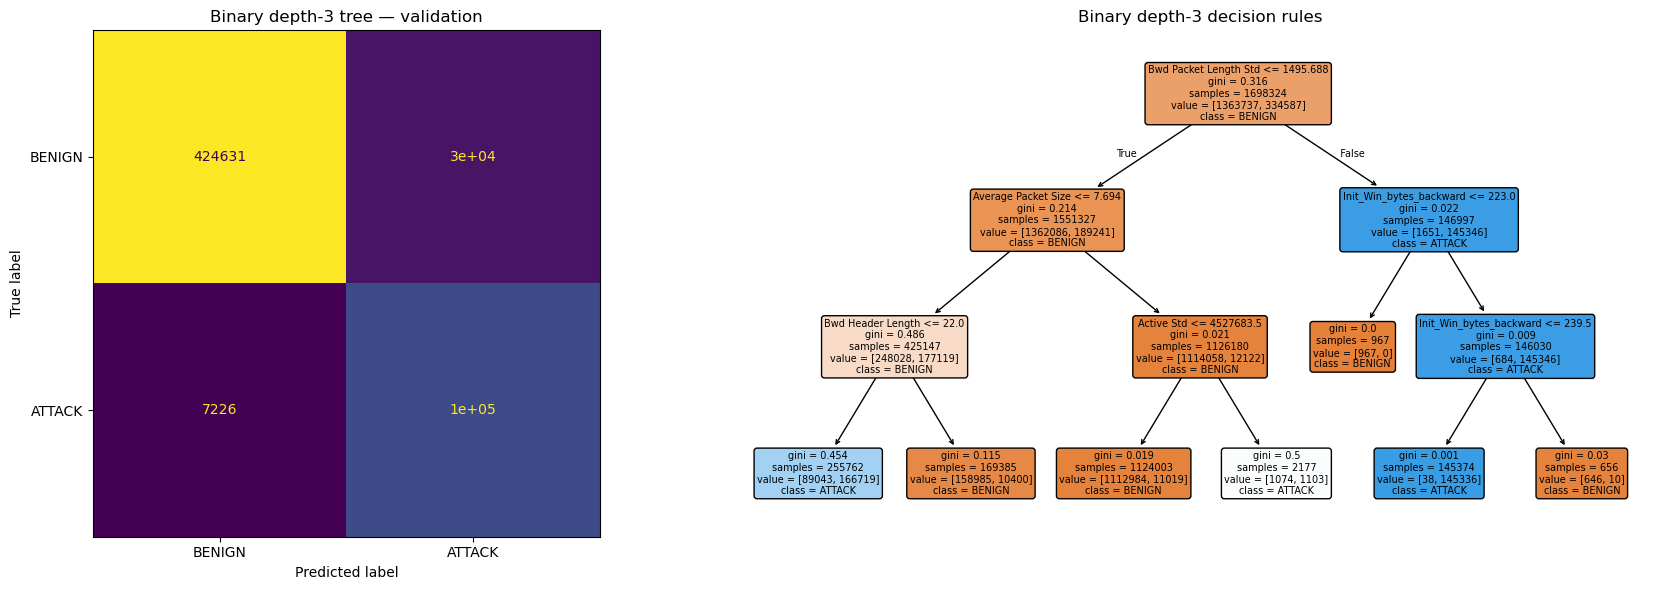

In [47]:
# Purpose: Fit training-median imputation and the fixed depth-3 binary tree.
# Explain: Validation receives the training imputer; tree decisions can reflect behavior or scenario clues.

# ============================================================
# PART 4.3 — BINARY DEPTH-3 DECISION TREE
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Extract behavioral features as float32 to reduce memory use.
feature_indices = df.columns.get_indexer(
    baseline_features
)

X_train_tree = df.iloc[
    random_train_df_positions,
    feature_indices
].to_numpy(dtype=np.float32)

X_validation_tree = df.iloc[
    random_validation_df_positions,
    feature_indices
].to_numpy(dtype=np.float32)

# Treat infinity as missing without changing the raw dataframe.
X_train_tree[
    ~np.isfinite(X_train_tree)
] = np.nan

X_validation_tree[
    ~np.isfinite(X_validation_tree)
] = np.nan

# Learn median values from training only.
tree_imputer = SimpleImputer(
    strategy="median",
    copy=False
)

X_train_tree = tree_imputer.fit_transform(
    X_train_tree
)

X_validation_tree = tree_imputer.transform(
    X_validation_tree
)

# Train the fixed depth-3 tree.
binary_tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

binary_tree.fit(
    X_train_tree,
    y_train_binary
)

binary_tree_predictions = binary_tree.predict(
    X_validation_tree
)

# Validation metrics.
binary_tree_results = pd.Series({
    "balanced_accuracy":
        balanced_accuracy_score(
            y_validation_binary,
            binary_tree_predictions
        ),

    "attack_f1":
        f1_score(
            y_validation_binary,
            binary_tree_predictions,
            pos_label=1
        ),

    "macro_f1":
        f1_score(
            y_validation_binary,
            binary_tree_predictions,
            average="macro"
        ),

    "weighted_f1":
        f1_score(
            y_validation_binary,
            binary_tree_predictions,
            average="weighted"
        ),
}, name="validation")

display(binary_tree_results.to_frame())

binary_tree_recall = pd.Series(
    recall_score(
        y_validation_binary,
        binary_tree_predictions,
        labels=[0, 1],
        average=None
    ),
    index=["BENIGN", "ATTACK"],
    name="recall"
)

display(binary_tree_recall.to_frame())

# Confusion matrix and tree rules.
fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 6)
)

ConfusionMatrixDisplay.from_predictions(
    y_validation_binary,
    binary_tree_predictions,
    labels=[0, 1],
    display_labels=["BENIGN", "ATTACK"],
    ax=axes[0],
    colorbar=False
)

axes[0].set_title(
    "Binary depth-3 tree — validation"
)

plot_tree(
    binary_tree,
    feature_names=baseline_features,
    class_names=["BENIGN", "ATTACK"],
    filled=True,
    rounded=True,
    fontsize=7,
    ax=axes[1]
)

axes[1].set_title(
    "Binary depth-3 decision rules"
)

plt.tight_layout()
plt.show()


The decision tree was trained using the random training partition and evaluated on validation data. Missing values were replaced using medians learned from training only. Scaling was not applied because decision trees are unaffected by feature magnitude.

Tree depth was fixed at three, so the model uses only a small number of understandable rules. Its attack F1 and balanced accuracy should be compared with the majority baseline. The tree rules will be examined to determine whether they describe plausible network behavior or dataset-specific patterns.

### Interpretation

The depth-3 decision tree detects 93.52% of attacks while correctly recognizing
93.41% of benign flows. It misses 7,226 attacks and incorrectly raises alarms for
29,948 benign flows. Its balanced accuracy increases from 50% for the majority
baseline to 93.47%.

The model separates the classes using a small number of understandable network-flow
measurements. However, these rules describe patterns in this dataset and should not
be interpreted as causes of attacks. The attack F1 score of 84.88% shows that false
alarms remain an important limitation.


,validation
balanced_accuracy,0.251648
macro_f1,0.266754
weighted_f1,0.917095


,recall
BENIGN,0.976605
Bot,0.000000
DDoS,0.628329
DoS GoldenEye,0.510442
DoS Hulk,0.666703
DoS Slowhttptest,0.000000
DoS slowloris,0.000000
FTP-Patator,0.000000
Heartbleed,0.000000
Infiltration,0.000000


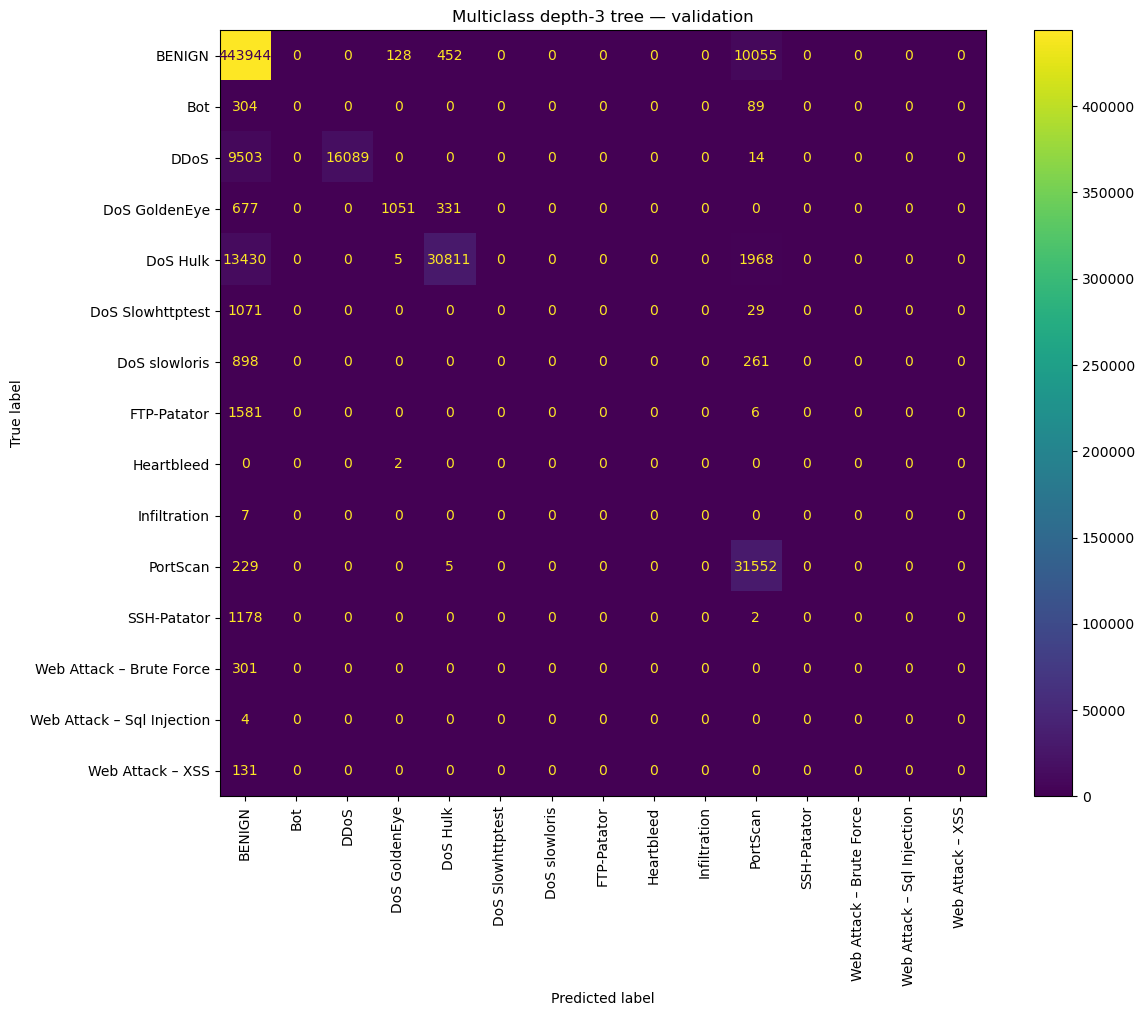

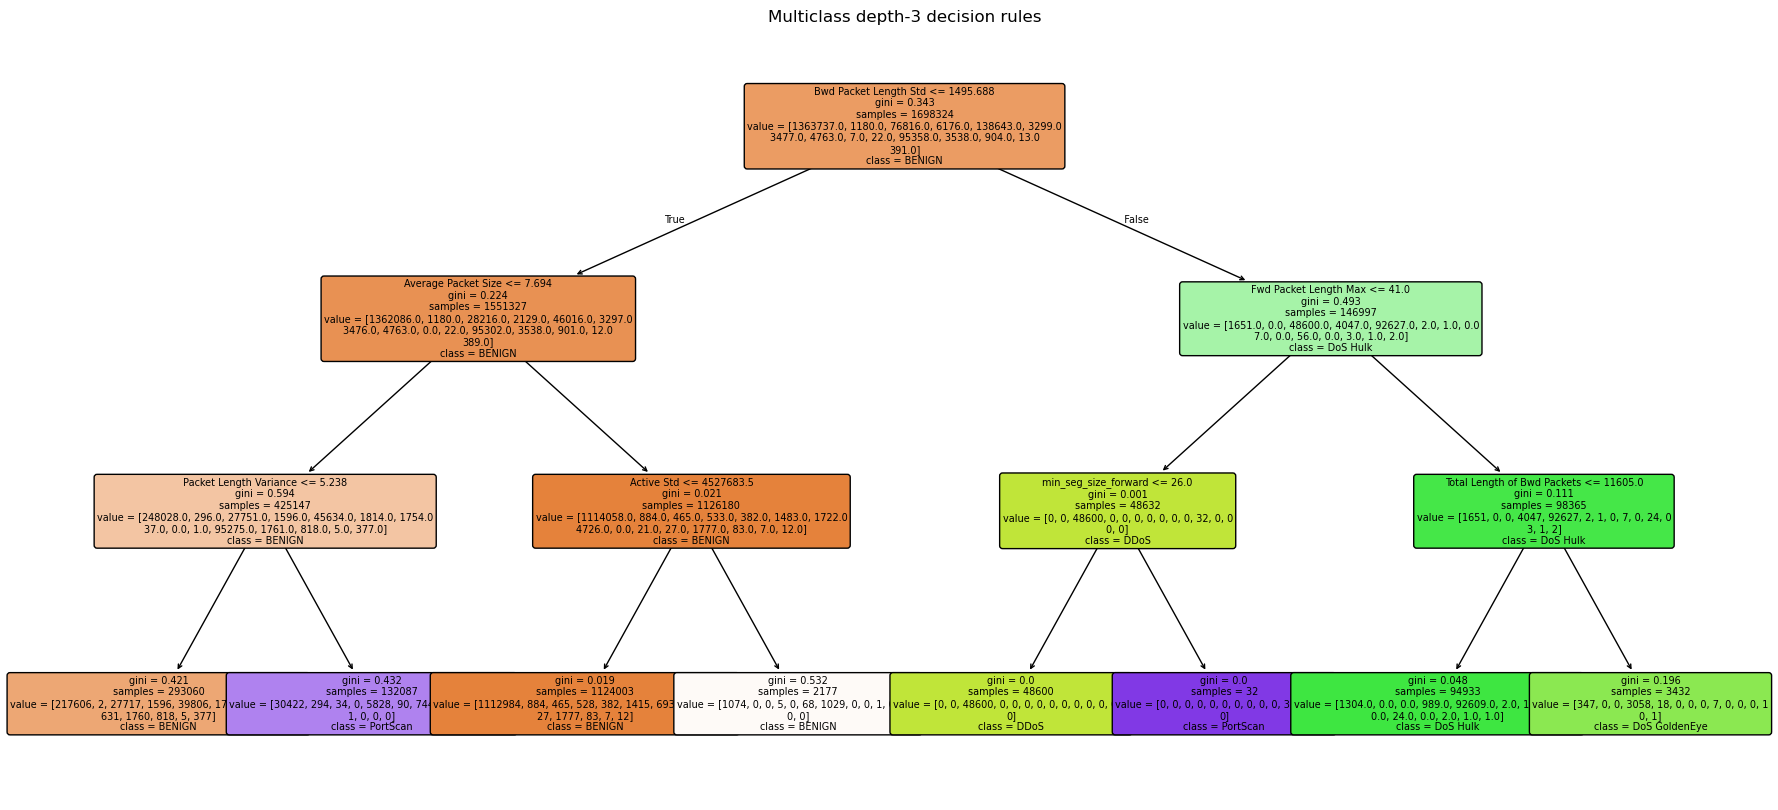

In [48]:
# Purpose: Fit the fixed depth-3 multiclass tree on the same prepared random features.
# Explain: Compare macro-F1 with weighted F1 to expose weak minority-category coverage.

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    recall_score,
    ConfusionMatrixDisplay,
)

# Train the multiclass tree
multiclass_tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=42,
)

multiclass_tree.fit(X_train_tree, y_train_multiclass)
multiclass_tree_predictions = multiclass_tree.predict(X_validation_tree)

# Overall validation metrics
multiclass_results = pd.Series({
    "balanced_accuracy": balanced_accuracy_score(
        y_validation_multiclass,
        multiclass_tree_predictions,
    ),
    "macro_f1": f1_score(
        y_validation_multiclass,
        multiclass_tree_predictions,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        y_validation_multiclass,
        multiclass_tree_predictions,
        average="weighted",
        zero_division=0,
    ),
}, name="validation")

display(multiclass_results.to_frame())

# Recall for every class
multiclass_labels = sorted(pd.unique(y_train_multiclass))

class_recall = pd.Series(
    recall_score(
        y_validation_multiclass,
        multiclass_tree_predictions,
        labels=multiclass_labels,
        average=None,
        zero_division=0,
    ),
    index=multiclass_labels,
    name="recall",
)

display(class_recall.to_frame())

# Confusion matrix
fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_validation_multiclass,
    multiclass_tree_predictions,
    labels=multiclass_labels,
    xticks_rotation=90,
    cmap="viridis",
    values_format=".0f",
    ax=ax,
)

ax.set_title("Multiclass depth-3 tree — validation")
plt.tight_layout()
plt.show()

# Decision rules
plt.figure(figsize=(22, 10))

plot_tree(
    multiclass_tree,
    feature_names=baseline_features,
    class_names=multiclass_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=7,
)

plt.title("Multiclass depth-3 decision rules")
plt.show()

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_ite

,C,attack_f1
0,0.01,0.794238
1,0.10,0.798068
2,1.00,0.799830


,validation
selected_C,1.000000
balanced_accuracy,0.868374
attack_f1,0.799830
macro_f1,0.876200
weighted_f1,0.922478


,recall
BENIGN,0.959030
ATTACK,0.777717


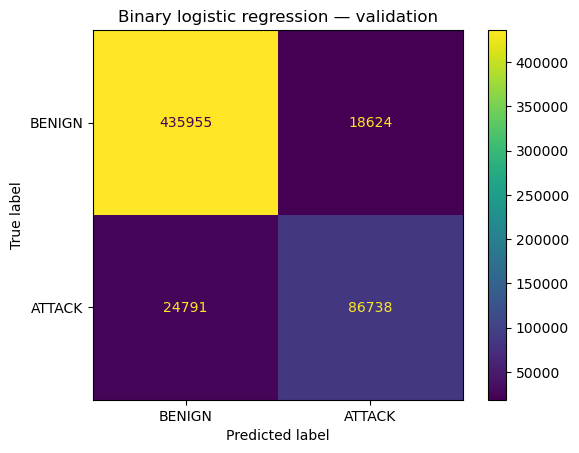

In [49]:
# Purpose: Standardize from random training and compare binary logistic regularization values.
# Explain: Select C by validation ATTACK F1; smaller C means stronger regularization.

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    recall_score,
    ConfusionMatrixDisplay,
)

# Fit scaling only on training data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_tree)
X_validation_scaled = scaler.transform(X_validation_tree)

# Choose C using validation attack F1
tested_C = [0.01, 0.1, 1.0]
tuning_results = []
binary_lr_models = {}

for C in tested_C:
    model = LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=100,
        random_state=42,
    )

    model.fit(X_train_scaled, y_train_binary)
    predictions = model.predict(X_validation_scaled)

    tuning_results.append({
        "C": C,
        "attack_f1": f1_score(y_validation_binary, predictions),
    })

    binary_lr_models[C] = model

tuning_results = pd.DataFrame(tuning_results)
display(tuning_results)

# Select the C with the highest validation attack F1
best_C = tuning_results.loc[
    tuning_results["attack_f1"].idxmax(),
    "C"
]

binary_lr = binary_lr_models[best_C]
binary_lr_predictions = binary_lr.predict(X_validation_scaled)

binary_lr_results = pd.Series({
    "selected_C": best_C,
    "balanced_accuracy": balanced_accuracy_score(
        y_validation_binary,
        binary_lr_predictions,
    ),
    "attack_f1": f1_score(
        y_validation_binary,
        binary_lr_predictions,
    ),
    "macro_f1": f1_score(
        y_validation_binary,
        binary_lr_predictions,
        average="macro",
    ),
    "weighted_f1": f1_score(
        y_validation_binary,
        binary_lr_predictions,
        average="weighted",
    ),
}, name="validation")

display(binary_lr_results.to_frame())

binary_lr_recall = pd.Series(
    recall_score(
        y_validation_binary,
        binary_lr_predictions,
        labels=[0, 1],
        average=None,
    ),
    index=["BENIGN", "ATTACK"],
    name="recall",
)

display(binary_lr_recall.to_frame())

ConfusionMatrixDisplay.from_predictions(
    y_validation_binary,
    binary_lr_predictions,
    labels=[0, 1],
    display_labels=["BENIGN", "ATTACK"],
    cmap="viridis",
    values_format=".0f",
)

plt.title("Binary logistic regression — validation")
plt.show()

### Interpretation

The best tested regularization value is C = 1.0, with a validation attack F1
of 79.98%. The similar scores across the three tested values show that changing
regularization strength has only a small effect within this range.

The model correctly recognizes 95.90% of benign flows but detects only 77.77%
of attacks. It is therefore more conservative than the depth-3 tree: it produces
fewer false alarms but misses more attacks. Its attack F1 and balanced accuracy
are lower than those of the binary decision tree.

The model and scaler were fitted using training data only, and the test partition
remains untouched.

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_ite

,C,macro_f1
0,0.01,0.424394
1,0.10,0.446687
2,1.00,0.456643


,validation
selected_C,1.000000
balanced_accuracy,0.434498
macro_f1,0.456643
weighted_f1,0.955153


,recall
BENIGN,0.972979
Bot,0.010178
DDoS,0.940248
DoS GoldenEye,0.825644
DoS Hulk,0.862228
DoS Slowhttptest,0.750909
DoS slowloris,0.519413
FTP-Patator,0.499685
Heartbleed,0.000000
Infiltration,0.142857


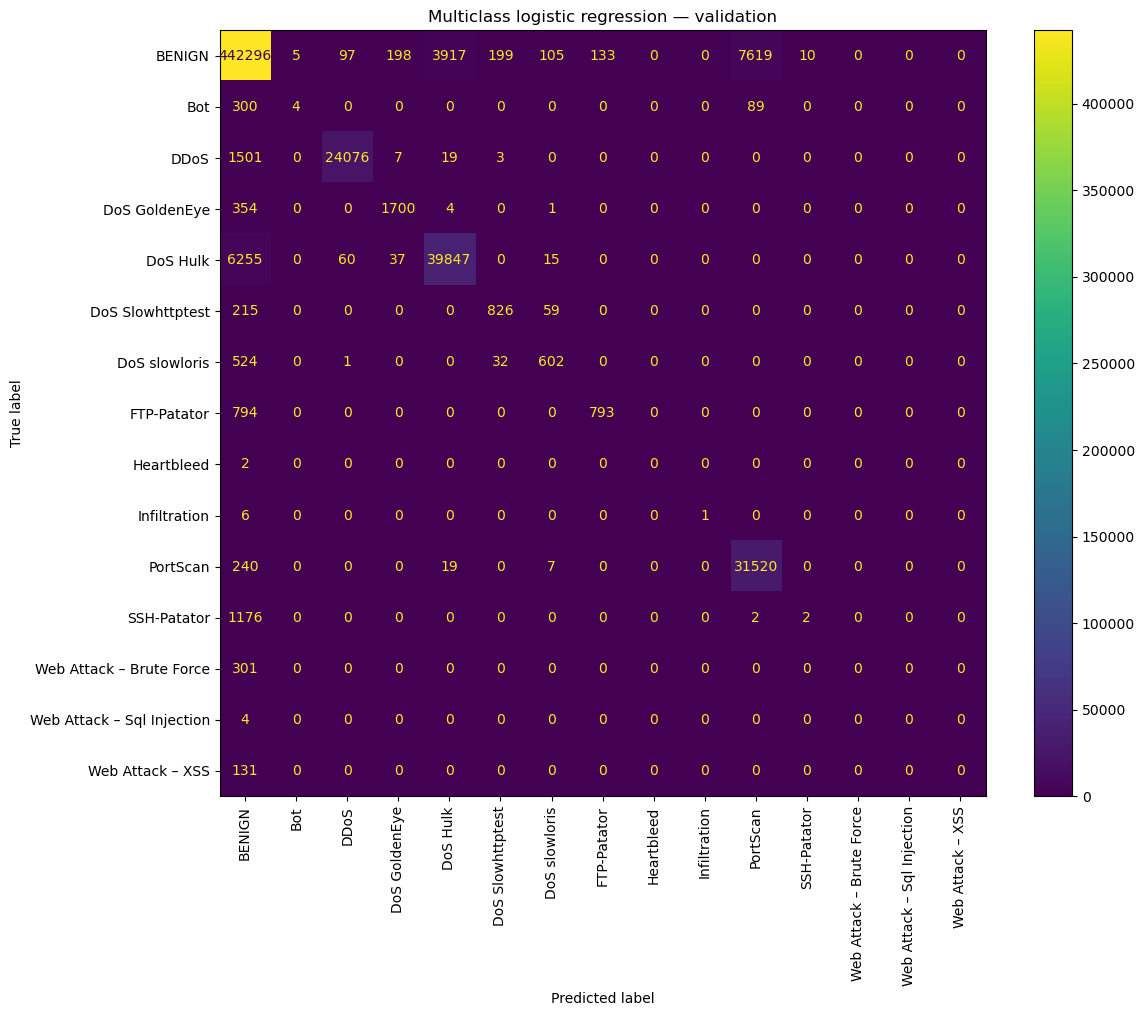

In [50]:
# Purpose: Select multiclass logistic regularization on random validation.
# Explain: Macro-F1 gives rare categories equal weight; do not select C from test performance.

# Test regularization values using validation macro F1
multiclass_tuning_results = []
multiclass_lr_models = {}

for C in tested_C:
    model = LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=100,
        random_state=42,
    )

    model.fit(X_train_scaled, y_train_multiclass)
    predictions = model.predict(X_validation_scaled)

    multiclass_tuning_results.append({
        "C": C,
        "macro_f1": f1_score(
            y_validation_multiclass,
            predictions,
            average="macro",
            zero_division=0,
        ),
    })

    multiclass_lr_models[C] = model

multiclass_tuning_results = pd.DataFrame(multiclass_tuning_results)
display(multiclass_tuning_results)

# Select the C with the highest validation macro F1
best_multiclass_C = multiclass_tuning_results.loc[
    multiclass_tuning_results["macro_f1"].idxmax(),
    "C"
]

multiclass_lr = multiclass_lr_models[best_multiclass_C]
multiclass_lr_predictions = multiclass_lr.predict(X_validation_scaled)

# Overall validation metrics
multiclass_lr_results = pd.Series({
    "selected_C": best_multiclass_C,
    "balanced_accuracy": balanced_accuracy_score(
        y_validation_multiclass,
        multiclass_lr_predictions,
    ),
    "macro_f1": f1_score(
        y_validation_multiclass,
        multiclass_lr_predictions,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        y_validation_multiclass,
        multiclass_lr_predictions,
        average="weighted",
        zero_division=0,
    ),
}, name="validation")

display(multiclass_lr_results.to_frame())

# Recall for every class
multiclass_lr_recall = pd.Series(
    recall_score(
        y_validation_multiclass,
        multiclass_lr_predictions,
        labels=multiclass_labels,
        average=None,
        zero_division=0,
    ),
    index=multiclass_labels,
    name="recall",
)

display(multiclass_lr_recall.to_frame())

# Confusion matrix
fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_validation_multiclass,
    multiclass_lr_predictions,
    labels=multiclass_labels,
    xticks_rotation=90,
    cmap="viridis",
    values_format=".0f",
    ax=ax,
)

ax.set_title("Multiclass logistic regression — validation")
plt.tight_layout()
plt.show()

### Interpretation

The selected regularization value is C = 1.0 because it produced the highest
validation macro F1 of 45.66%. Logistic regression performs better than the
depth-3 tree in balanced accuracy, macro F1, and weighted F1.

The model recognizes common classes such as BENIGN, DDoS, DoS Hulk, and PortScan
well. However, it has very low or zero recall for several rare classes, including
Heartbleed and the Web Attack classes. The weighted F1 of 95.52% therefore gives
an overly optimistic impression because it is dominated by common classes.

The lower macro F1 and class-wise recall show that the model is not equally
effective across all attack types. The test partition remains untouched.

,count
training_sample_rows,100000
validation_sample_rows,40000


,k,attack_f1
0,3,0.985682
1,5,0.983208
2,11,0.976735


,sampled_validation
selected_k,3.000000
balanced_accuracy,0.991646
attack_f1,0.985682
macro_f1,0.991081
weighted_f1,0.994353


,recall
BENIGN,0.996108
ATTACK,0.987183


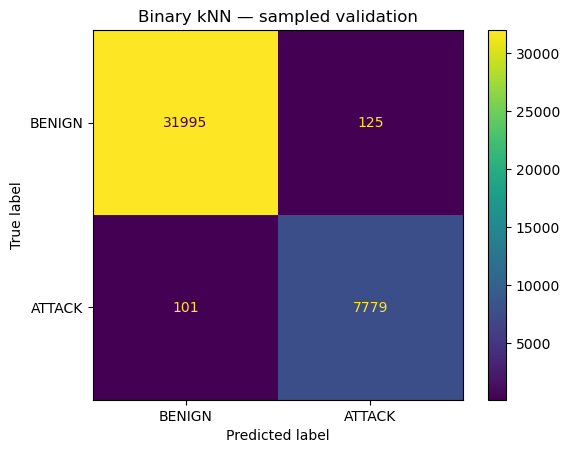

In [52]:
# Purpose: Compare binary kNN settings using fixed computational samples.
# Explain: Choose k by sampled validation attack F1; the sampled scope limits full-data comparisons.

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

# Reproducible stratified samples for computational feasibility
binary_knn_train_indices, _ = train_test_split(
    np.arange(len(y_train_binary)),
    train_size=100_000,
    stratify=y_train_binary,
    random_state=42,
)

binary_knn_validation_indices, _ = train_test_split(
    np.arange(len(y_validation_binary)),
    train_size=40_000,
    stratify=y_validation_binary,
    random_state=42,
)

X_train_knn = X_train_scaled[binary_knn_train_indices]
y_train_knn = np.asarray(y_train_binary)[binary_knn_train_indices]

X_validation_knn = X_validation_scaled[binary_knn_validation_indices]
y_validation_knn = np.asarray(y_validation_binary)[binary_knn_validation_indices]

display(pd.Series({
    "training_sample_rows": len(y_train_knn),
    "validation_sample_rows": len(y_validation_knn),
}).to_frame("count"))

# Choose k using validation attack F1
tested_k = [3, 5, 11]
knn_tuning_results = []
binary_knn_models = {}

for k in tested_k:
    model = KNeighborsClassifier(
        n_neighbors=k,
        n_jobs=-1,
    )

    model.fit(X_train_knn, y_train_knn)
    predictions = model.predict(X_validation_knn)

    knn_tuning_results.append({
        "k": k,
        "attack_f1": f1_score(y_validation_knn, predictions),
    })

    binary_knn_models[k] = model

knn_tuning_results = pd.DataFrame(knn_tuning_results)
display(knn_tuning_results)

# Select the k with the highest validation attack F1
best_k = int(
    knn_tuning_results.loc[
        knn_tuning_results["attack_f1"].idxmax(),
        "k",
    ]
)

binary_knn = binary_knn_models[best_k]
binary_knn_predictions = binary_knn.predict(X_validation_knn)

binary_knn_results = pd.Series({
    "selected_k": best_k,
    "balanced_accuracy": balanced_accuracy_score(
        y_validation_knn,
        binary_knn_predictions,
    ),
    "attack_f1": f1_score(
        y_validation_knn,
        binary_knn_predictions,
    ),
    "macro_f1": f1_score(
        y_validation_knn,
        binary_knn_predictions,
        average="macro",
    ),
    "weighted_f1": f1_score(
        y_validation_knn,
        binary_knn_predictions,
        average="weighted",
    ),
}, name="sampled_validation")

display(binary_knn_results.to_frame())

binary_knn_recall = pd.Series(
    recall_score(
        y_validation_knn,
        binary_knn_predictions,
        labels=[0, 1],
        average=None,
    ),
    index=["BENIGN", "ATTACK"],
    name="recall",
)

display(binary_knn_recall.to_frame())

ConfusionMatrixDisplay.from_predictions(
    y_validation_knn,
    binary_knn_predictions,
    labels=[0, 1],
    display_labels=["BENIGN", "ATTACK"],
    cmap="viridis",
    values_format=".0f",
)

plt.title("Binary kNN — sampled validation")
plt.show()

kNN classifies each flow according to the labels of its k nearest training flows.
The selected k is the tested value that produces the highest attack F1 on the
sampled validation data.

Feature scaling was fitted on the complete training partition before sampling.
A fixed stratified sample of 20,000 training rows and 10,000 validation rows was
used because exact kNN on the complete dataset is computationally impractical.

The selected value is k = 3, which produced a sampled-validation attack F1 of
96.75%. Increasing k reduced attack F1, suggesting that the closest flows carry
useful local information that becomes diluted when more neighbors are included.


,training_sample,validation_sample
BENIGN,80299,32120
Bot,70,393
DDoS,4523,1809
DoS GoldenEye,364,146
DoS Hulk,8164,3265
DoS Slowhttptest,194,78
DoS slowloris,205,82
FTP-Patator,280,112
Heartbleed,7,2
Infiltration,22,7


,k,macro_f1
0,3,0.785362
1,5,0.767520
2,11,0.750012


,sampled_validation
selected_k,3.000000
balanced_accuracy,0.769216
macro_f1,0.785362
weighted_f1,0.984241


,recall
BENIGN,0.995859
Bot,0.435115
DDoS,0.991708
DoS GoldenEye,0.965753
DoS Hulk,0.989280
DoS Slowhttptest,0.987179
DoS slowloris,0.926829
FTP-Patator,0.991071
Heartbleed,1.000000
Infiltration,0.285714


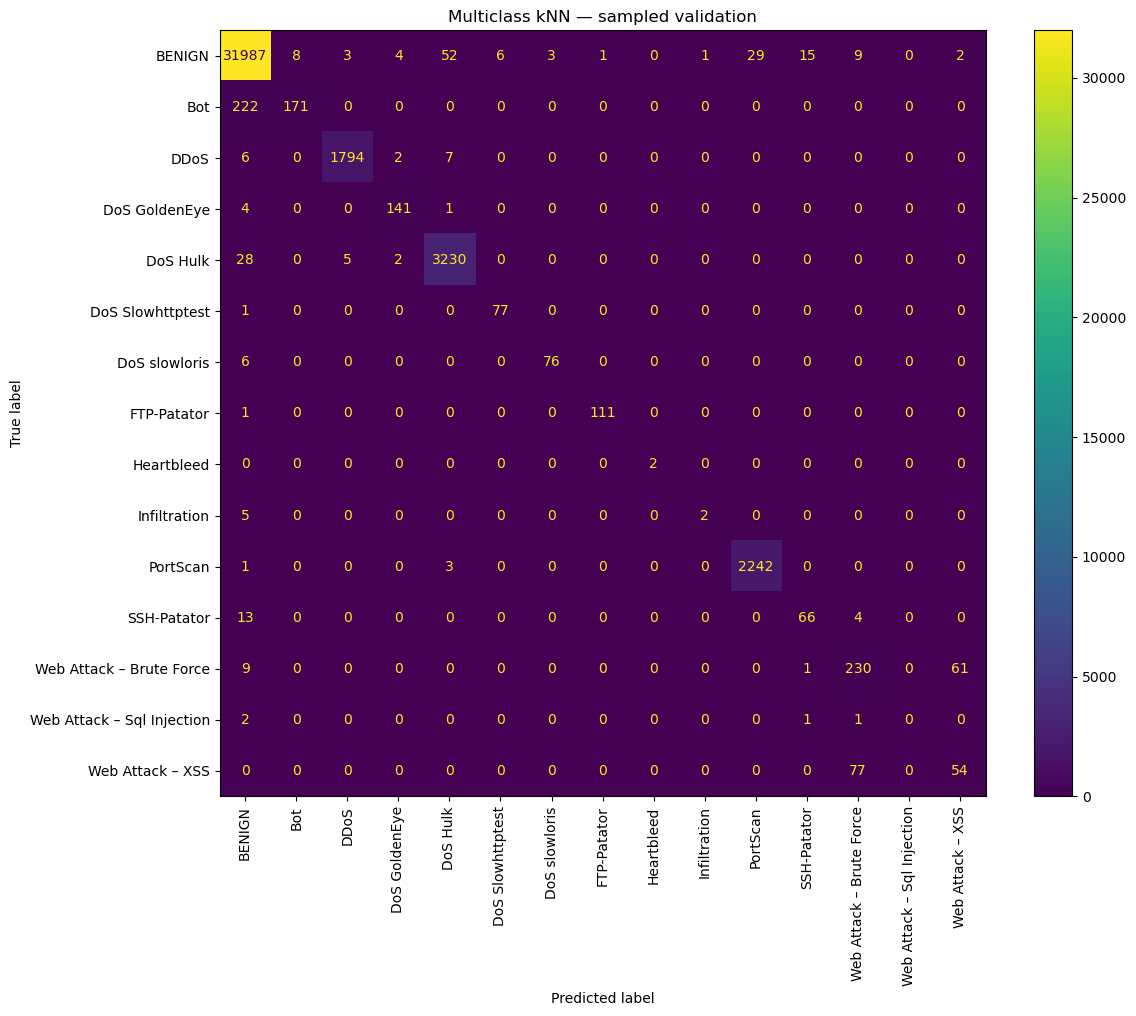

In [53]:
# Purpose: Build multiclass kNN samples with additional rare-category coverage.
# Explain: Choose k by validation macro-F1 and report the augmented sample population explicitly.

# Convert labels to arrays for positional indexing
y_train_multiclass_array = np.asarray(y_train_multiclass)
y_validation_multiclass_array = np.asarray(y_validation_multiclass)

# Start with larger stratified samples
multiclass_train_indices, _ = train_test_split(
    np.arange(len(y_train_multiclass_array)),
    train_size=100_000,
    stratify=y_train_multiclass_array,
    random_state=42,
)

multiclass_validation_indices, _ = train_test_split(
    np.arange(len(y_validation_multiclass_array)),
    train_size=40_000,
    stratify=y_validation_multiclass_array,
    random_state=42,
)

# Identify classes with fewer than 1,000 rows
train_class_counts = pd.Series(y_train_multiclass_array).value_counts()
validation_class_counts = pd.Series(
    y_validation_multiclass_array
).value_counts()

rare_train_classes = train_class_counts[
    train_class_counts < 1_000
].index

rare_validation_classes = validation_class_counts[
    validation_class_counts < 1_000
].index

# Include every available row from the rare classes
rare_train_indices = np.flatnonzero(
    np.isin(y_train_multiclass_array, rare_train_classes)
)

rare_validation_indices = np.flatnonzero(
    np.isin(
        y_validation_multiclass_array,
        rare_validation_classes,
    )
)

multiclass_train_indices = np.unique(
    np.concatenate([
        multiclass_train_indices,
        rare_train_indices,
    ])
)

multiclass_validation_indices = np.unique(
    np.concatenate([
        multiclass_validation_indices,
        rare_validation_indices,
    ])
)

# Create the computational kNN samples
X_train_knn_multiclass = X_train_scaled[
    multiclass_train_indices
]

y_train_knn_multiclass = y_train_multiclass_array[
    multiclass_train_indices
]

X_validation_knn_multiclass = X_validation_scaled[
    multiclass_validation_indices
]

y_validation_knn_multiclass = y_validation_multiclass_array[
    multiclass_validation_indices
]

# Verify representation of every class
knn_multiclass_counts = pd.DataFrame({
    "training_sample": pd.Series(
        y_train_knn_multiclass
    ).value_counts(),
    "validation_sample": pd.Series(
        y_validation_knn_multiclass
    ).value_counts(),
}).fillna(0).astype(int)

display(knn_multiclass_counts.reindex(multiclass_labels))

# Choose k using validation macro F1
multiclass_knn_results = []
multiclass_knn_models = {}
multiclass_knn_predictions_by_k = {}

for k in tested_k:
    model = KNeighborsClassifier(
        n_neighbors=k,
        n_jobs=-1,
    )

    model.fit(
        X_train_knn_multiclass,
        y_train_knn_multiclass,
    )

    predictions = model.predict(
        X_validation_knn_multiclass
    )

    multiclass_knn_results.append({
        "k": k,
        "macro_f1": f1_score(
            y_validation_knn_multiclass,
            predictions,
            labels=multiclass_labels,
            average="macro",
            zero_division=0,
        ),
    })

    multiclass_knn_models[k] = model
    multiclass_knn_predictions_by_k[k] = predictions

multiclass_knn_results = pd.DataFrame(
    multiclass_knn_results
)

display(multiclass_knn_results)

# Select the k with the highest validation macro F1
best_multiclass_k = int(
    multiclass_knn_results.loc[
        multiclass_knn_results["macro_f1"].idxmax(),
        "k",
    ]
)

multiclass_knn = multiclass_knn_models[
    best_multiclass_k
]

multiclass_knn_predictions = (
    multiclass_knn_predictions_by_k[
        best_multiclass_k
    ]
)

# Overall metrics for the selected model
selected_multiclass_knn_results = pd.Series({
    "selected_k": best_multiclass_k,
    "balanced_accuracy": balanced_accuracy_score(
        y_validation_knn_multiclass,
        multiclass_knn_predictions,
    ),
    "macro_f1": f1_score(
        y_validation_knn_multiclass,
        multiclass_knn_predictions,
        labels=multiclass_labels,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        y_validation_knn_multiclass,
        multiclass_knn_predictions,
        labels=multiclass_labels,
        average="weighted",
        zero_division=0,
    ),
}, name="sampled_validation")

display(selected_multiclass_knn_results.to_frame())

# Recall for every class
multiclass_knn_recall = pd.Series(
    recall_score(
        y_validation_knn_multiclass,
        multiclass_knn_predictions,
        labels=multiclass_labels,
        average=None,
        zero_division=0,
    ),
    index=multiclass_labels,
    name="recall",
)

display(multiclass_knn_recall.to_frame())

# Confusion matrix
fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_validation_knn_multiclass,
    multiclass_knn_predictions,
    labels=multiclass_labels,
    xticks_rotation=90,
    cmap="viridis",
    values_format=".0f",
    ax=ax,
)

ax.set_title("Multiclass kNN — sampled validation")
plt.tight_layout()
plt.show()

### Interpretation


kNN appears strongest, but its result comes from an augmented sample, while the other models used the complete validation partition. It is therefore not a perfectly direct comparison. The random split may also give kNN an advantage by placing very similar flows in training and validation.

In [54]:
# Purpose: Check that grouped memberships have no shared five-tuples and report class counts.
# Explain: Unseen categories and absent categories need separate interpretation from prediction failure.

# ============================================================
# TASK 1 - VERIFY AND SUMMARIZE THE GROUPED PROTOCOL
# ============================================================

grouped_overlap_summary = pd.Series({
    "train_validation_five_tuple_overlap": len(
        train_group_codes & validation_group_codes
    ),
    "train_test_five_tuple_overlap": len(
        train_group_codes & test_group_codes
    ),
    "validation_test_five_tuple_overlap": len(
        validation_group_codes & test_group_codes
    ),
}, name="count")

grouped_counts_complete = grouped_class_counts.reindex(
    index=all_label_order,
    columns=["train", "validation", "test"],
    fill_value=0,
)

print("GROUPED FIVE-TUPLE PROTOCOL")
display(grouped_split_summary.to_frame())

print("FIVE-TUPLE OVERLAP CHECK")
display(grouped_overlap_summary.to_frame())

print("CLASS COUNTS, INCLUDING ZEROS")
display(grouped_counts_complete)

print("Validation classes absent from training:")
print(grouped_unseen_validation or "None")

print("Test classes absent from training:")
print(grouped_unseen_test or "None")

# %% [markdown]
# ### Interpretation
#
# A valid grouped protocol must have zero five-tuple overlap between every pair of
# partitions. The class table reports zero-count classes instead of hiding them.
# Any test class absent from training represents an unseen-class problem that the
# multiclass model cannot learn from this training partition.


GROUPED FIVE-TUPLE PROTOCOL


,value
seed,42
eligible_rows,2830540
unique_five_tuple_groups,1085071
mixed_label_five_tuple_groups,29346
training_rows,1700178
validation_rows,564700
test_rows,565662
training_percentage,60.07%
validation_percentage,19.95%
test_percentage,19.98%


FIVE-TUPLE OVERLAP CHECK


,count
train_validation_five_tuple_overlap,0
train_test_five_tuple_overlap,0
validation_test_five_tuple_overlap,0


CLASS COUNTS, INCLUDING ZEROS


partition,train,validation,test
Label,,,
BENIGN,1364886,454082,453927
Bot,1186,398,382
DDoS,76985,25499,25543
DoS GoldenEye,6242,2007,2044
DoS Hulk,139036,45448,46588
DoS Slowhttptest,3302,1102,1095
DoS slowloris,3525,1155,1116
FTP-Patator,4766,1592,1580
Heartbleed,11,0,0


Validation classes absent from training:
None
Test classes absent from training:
None


In [55]:
# Purpose: Construct grouped baseline arrays with grouped-training constant removal.
# Explain: Apply the same feature policy as the random experiment without learning from held-out rows.

# ============================================================
# TASK 2 - GROUPED FEATURES, ROWS, AND LABELS
# ============================================================

# Apply the same feature-treatment policy using grouped training only.
grouped_constant_features = constant_feature_table.loc[
    (constant_feature_table["protocol"] == "Grouped")
    & (constant_feature_table["status"] == "Constant"),
    "feature",
].tolist()

grouped_features = [
    feature
    for feature in behavior_feature_columns
    if feature not in (
        grouped_constant_features
        + redundant_features_to_remove
    )
]

# Convert positions inside the modeling rows to positions inside df.
grouped_train_df_positions = model_row_positions[
    train_grouped_positions
]

grouped_validation_df_positions = model_row_positions[
    validation_grouped_positions
]

grouped_test_df_positions = model_row_positions[
    test_grouped_positions
]

# Multiclass labels.
y_grouped_train_multiclass = model_labels[
    train_grouped_positions
]

y_grouped_validation_multiclass = model_labels[
    validation_grouped_positions
]

y_grouped_test_multiclass = model_labels[
    test_grouped_positions
]

# Binary labels: BENIGN = 0 and ATTACK = 1.
y_grouped_train_binary = np.where(
    y_grouped_train_multiclass == "BENIGN", 0, 1
)

y_grouped_validation_binary = np.where(
    y_grouped_validation_multiclass == "BENIGN", 0, 1
)

y_grouped_test_binary = np.where(
    y_grouped_test_multiclass == "BENIGN", 0, 1
)

grouped_modeling_summary = pd.Series({
    "behavioral_features_before_treatment": len(
        behavior_feature_columns
    ),
    "grouped_training_constants_removed": len(
        grouped_constant_features
    ),
    "redundant_features_removed": len(
        redundant_features_to_remove
    ),
    "features_retained": len(grouped_features),
    "training_rows": len(grouped_train_df_positions),
    "validation_rows": len(grouped_validation_df_positions),
    "test_rows": len(grouped_test_df_positions),
}, name="value")

display(grouped_modeling_summary.to_frame())

,value
behavioral_features_before_treatment,77
grouped_training_constants_removed,8
redundant_features_removed,7
features_retained,62
training_rows,1700178
validation_rows,564700
test_rows,565662


In [56]:
# Purpose: Fit the grouped-training median imputer and apply it to validation.
# Explain: Invalid numerical values become missing; validation must not estimate replacement medians.

# ============================================================
# TASK 3 - TRAIN-ONLY IMPUTATION
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    recall_score,
    ConfusionMatrixDisplay,
)
from sklearn.tree import DecisionTreeClassifier, plot_tree

grouped_feature_indices = df.columns.get_indexer(
    grouped_features
)

X_grouped_train = df.iloc[
    grouped_train_df_positions,
    grouped_feature_indices,
].to_numpy(dtype=np.float32)

X_grouped_validation = df.iloc[
    grouped_validation_df_positions,
    grouped_feature_indices,
].to_numpy(dtype=np.float32)

# Treat infinity as missing without changing df.
X_grouped_train[~np.isfinite(X_grouped_train)] = np.nan
X_grouped_validation[~np.isfinite(X_grouped_validation)] = np.nan

# Learn replacement medians from grouped training only.
grouped_imputer = SimpleImputer(
    strategy="median",
    copy=False,
)

X_grouped_train = grouped_imputer.fit_transform(
    X_grouped_train
)

X_grouped_validation = grouped_imputer.transform(
    X_grouped_validation
)

print("Grouped matrices after train-only imputation:")
display(pd.Series({
    "train_rows": X_grouped_train.shape[0],
    "validation_rows": X_grouped_validation.shape[0],
    "test_rows_reserved": len(grouped_test_df_positions),
    "features": X_grouped_train.shape[1],
}).to_frame("count"))

Grouped matrices after train-only imputation:


,count
train_rows,1700178
validation_rows,564700
test_rows_reserved,565662
features,62


 ### Interpretation
Missing and infinite values are replaced using medians learned only from grouped
 training. Applying those fixed medians to validation prevents information from
 the evaluation partition from influencing preprocessing. Test remains untouched
 until every model and hyperparameter has been frozen.

In [57]:
# Purpose: Evaluate grouped majority baselines for both prediction tasks.
# Explain: Use them as null references rather than assuming chance performance means 50% accuracy.

grouped_binary_majority_label = pd.Series(
    y_grouped_train_binary
).mode()[0]

grouped_multiclass_majority_label = pd.Series(
    y_grouped_train_multiclass
).mode()[0]

grouped_binary_majority_validation_predictions = np.full(
    len(y_grouped_validation_binary),
    grouped_binary_majority_label,
)

grouped_multiclass_majority_validation_predictions = np.full(
    len(y_grouped_validation_multiclass),
    grouped_multiclass_majority_label,
    dtype=object,
)

grouped_majority_results = pd.DataFrame({
    "task": ["Binary", "Multiclass"],
    "validation_balanced_accuracy": [
        balanced_accuracy_score(
            y_grouped_validation_binary,
            grouped_binary_majority_validation_predictions,
        ),
        balanced_accuracy_score(
            y_grouped_validation_multiclass,
            grouped_multiclass_majority_validation_predictions,
        ),
    ],
    "validation_selection_metric": [
        f1_score(
            y_grouped_validation_binary,
            grouped_binary_majority_validation_predictions,
            pos_label=1,
            zero_division=0,
        ),
        f1_score(
            y_grouped_validation_multiclass,
            grouped_multiclass_majority_validation_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
    ],
}).set_index("task")

display(grouped_majority_results)


,validation_balanced_accuracy,validation_selection_metric
task,,
Binary,0.500000,0.000000
Multiclass,0.071429,0.059428


,validation_balanced_accuracy,validation_selection_metric
task,,
Binary,0.934571,0.847928
Multiclass,0.289433,0.289939


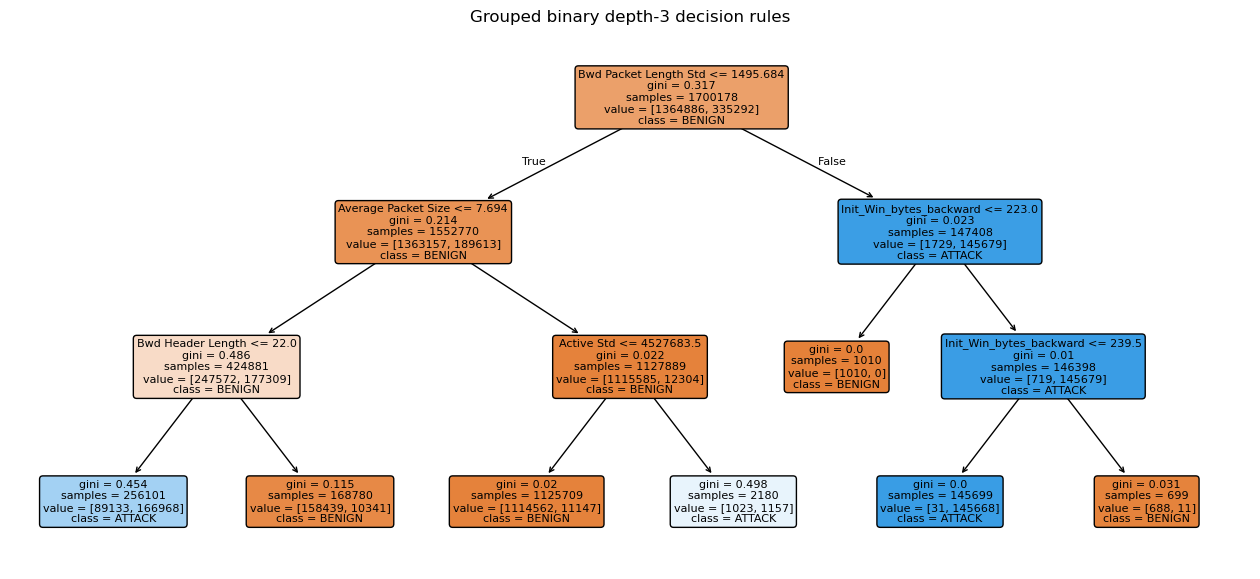

In [58]:
# Purpose: Fit grouped binary and multiclass trees at the predeclared depth of three.
# Explain: Validation measures the same model family under unseen conversation groups.

# ============================================================
# TASK 5 - GROUPED DEPTH-3 DECISION TREES
# ============================================================

grouped_binary_tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=42,
)

grouped_binary_tree.fit(
    X_grouped_train,
    y_grouped_train_binary,
)

grouped_binary_tree_validation_predictions = (
    grouped_binary_tree.predict(X_grouped_validation)
)

grouped_multiclass_tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=42,
)

grouped_multiclass_tree.fit(
    X_grouped_train,
    y_grouped_train_multiclass,
)

grouped_multiclass_tree_validation_predictions = (
    grouped_multiclass_tree.predict(X_grouped_validation)
)

grouped_tree_results = pd.DataFrame({
    "task": ["Binary", "Multiclass"],
    "validation_balanced_accuracy": [
        balanced_accuracy_score(
            y_grouped_validation_binary,
            grouped_binary_tree_validation_predictions,
        ),
        balanced_accuracy_score(
            y_grouped_validation_multiclass,
            grouped_multiclass_tree_validation_predictions,
        ),
    ],
    "validation_selection_metric": [
        f1_score(
            y_grouped_validation_binary,
            grouped_binary_tree_validation_predictions,
            pos_label=1,
            zero_division=0,
        ),
        f1_score(
            y_grouped_validation_multiclass,
            grouped_multiclass_tree_validation_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
    ],
}).set_index("task")

display(grouped_tree_results)

plt.figure(figsize=(16, 7))
plot_tree(
    grouped_binary_tree,
    feature_names=grouped_features,
    class_names=["BENIGN", "ATTACK"],
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.title("Grouped binary depth-3 decision rules")
plt.show()

In [59]:
# Purpose: Learn grouped-training feature scales for logistic regression and kNN.
# Explain: Apply those same means/scales to validation; trees do not require scaling.

# ============================================================
# TASK 6 - GROUPED TRAIN-ONLY SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler

# Trees are already fitted and evaluated. Scale these matrices in place to avoid
# making another large copy in memory.
grouped_scaler = StandardScaler(copy=False)

X_grouped_train_scaled = grouped_scaler.fit_transform(
    X_grouped_train
)

X_grouped_validation_scaled = grouped_scaler.transform(
    X_grouped_validation
)

print("Scaling fitted on grouped training only.")

Scaling fitted on grouped training only.


### Interpretation
 Logistic regression and kNN use the same scaler. Its means and standard
 deviations are learned only from grouped training, then applied unchanged to
 validation. Scaling is performed after the tree because trees do not require it.
 Test remains untouched until final evaluation.


In [67]:
# Purpose: Select grouped binary logistic C by validation attack F1.
# Explain: The optimizer learns coefficients on training; validation selects among fitted candidates.

# ============================================================
# TASK 7 - GROUPED BINARY LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression

grouped_tested_C = [0.01, 0.1, 1.0]
grouped_binary_lr_tuning = []
grouped_binary_lr_models = {}
grouped_binary_lr_validation_predictions_by_C = {}

for C in grouped_tested_C:
    model = LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=500,
        random_state=42,
    )

    model.fit(
        X_grouped_train_scaled,
        y_grouped_train_binary,
    )

    predictions = model.predict(
        X_grouped_validation_scaled
    )

    grouped_binary_lr_tuning.append({
        "C": C,
        "attack_f1": f1_score(
            y_grouped_validation_binary,
            predictions,
            pos_label=1,
            zero_division=0,
        ),
    })

    grouped_binary_lr_models[C] = model
    grouped_binary_lr_validation_predictions_by_C[C] = predictions

grouped_binary_lr_tuning = pd.DataFrame(
    grouped_binary_lr_tuning
)

display(grouped_binary_lr_tuning)

grouped_best_binary_C = grouped_binary_lr_tuning.loc[
    grouped_binary_lr_tuning["attack_f1"].idxmax(),
    "C",
]

grouped_binary_lr = grouped_binary_lr_models[
    grouped_best_binary_C
]

grouped_binary_lr_validation_predictions = (
    grouped_binary_lr_validation_predictions_by_C[
        grouped_best_binary_C
    ]
)

grouped_binary_lr_results = pd.Series({
    "balanced_accuracy": balanced_accuracy_score(
        y_grouped_validation_binary,
        grouped_binary_lr_validation_predictions,
    ),
    "attack_f1": f1_score(
        y_grouped_validation_binary,
        grouped_binary_lr_validation_predictions,
        pos_label=1,
        zero_division=0,
    ),
    "macro_f1": f1_score(
        y_grouped_validation_binary,
        grouped_binary_lr_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        y_grouped_validation_binary,
        grouped_binary_lr_validation_predictions,
        average="weighted",
        zero_division=0,
    ),
}, name="validation")

print("Selected C:", grouped_best_binary_C)
display(grouped_binary_lr_results)


,C,attack_f1
0,0.01,0.795983
1,0.10,0.808080
2,1.00,0.823064


Selected C: 1.0


balanced_accuracy    0.885113
attack_f1            0.823064
macro_f1             0.890465
weighted_f1          0.931460
Name: validation, dtype: float64

In [69]:
# Purpose: Select grouped multiclass logistic C by validation macro-F1.
# Explain: Compare minority-category performance as well as aggregate scores and optimizer convergence.

# ============================================================
# TASK 8 - GROUPED MULTICLASS LOGISTIC REGRESSION
# ============================================================

grouped_multiclass_lr_tuning = []
grouped_multiclass_lr_models = {}
grouped_multiclass_lr_validation_predictions_by_C = {}

for C in grouped_tested_C:
    model = LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=800,
        random_state=42,
    )

    model.fit(
        X_grouped_train_scaled,
        y_grouped_train_multiclass,
    )

    predictions = model.predict(
        X_grouped_validation_scaled
    )

    grouped_multiclass_lr_tuning.append({
        "C": C,
        "macro_f1": f1_score(
            y_grouped_validation_multiclass,
            predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
    })

    grouped_multiclass_lr_models[C] = model
    grouped_multiclass_lr_validation_predictions_by_C[C] = predictions

grouped_multiclass_lr_tuning = pd.DataFrame(
    grouped_multiclass_lr_tuning
)

display(grouped_multiclass_lr_tuning)

grouped_best_multiclass_C = grouped_multiclass_lr_tuning.loc[
    grouped_multiclass_lr_tuning["macro_f1"].idxmax(),
    "C",
]

grouped_multiclass_lr = grouped_multiclass_lr_models[
    grouped_best_multiclass_C
]

grouped_multiclass_lr_validation_predictions = (
    grouped_multiclass_lr_validation_predictions_by_C[
        grouped_best_multiclass_C
    ]
)

grouped_multiclass_lr_results = pd.Series({
    "balanced_accuracy": balanced_accuracy_score(
        y_grouped_validation_multiclass,
        grouped_multiclass_lr_validation_predictions,
    ),
    "macro_f1": f1_score(
        y_grouped_validation_multiclass,
        grouped_multiclass_lr_validation_predictions,
        labels=all_label_order,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        y_grouped_validation_multiclass,
        grouped_multiclass_lr_validation_predictions,
        labels=all_label_order,
        average="weighted",
        zero_division=0,
    ),
}, name="validation")

print("Selected C:", grouped_best_multiclass_C)
display(grouped_multiclass_lr_results)


,C,macro_f1
0,0.01,0.394745
1,0.10,0.492407
2,1.00,0.523754


/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Selected C: 1.0


balanced_accuracy    0.534380
macro_f1             0.523754
weighted_f1          0.961305
Name: validation, dtype: float64

In [62]:
# Purpose: Tune grouped binary kNN on fixed training/validation samples.
# Explain: Sampling controls cost; k changes the local voting neighborhood, not the data partition rule.

# ============================================================
# TASK 9 - GROUPED BINARY kNN
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# Computational samples remain inside the grouped partitions.
grouped_binary_knn_train_indices, _ = train_test_split(
    np.arange(len(y_grouped_train_binary)),
    train_size=100_000,
    stratify=y_grouped_train_binary,
    random_state=42,
)

grouped_binary_knn_validation_indices, _ = train_test_split(
    np.arange(len(y_grouped_validation_binary)),
    train_size=40_000,
    stratify=y_grouped_validation_binary,
    random_state=42,
)

X_grouped_binary_knn_train = X_grouped_train_scaled[
    grouped_binary_knn_train_indices
]
y_grouped_binary_knn_train = y_grouped_train_binary[
    grouped_binary_knn_train_indices
]

X_grouped_binary_knn_validation = X_grouped_validation_scaled[
    grouped_binary_knn_validation_indices
]
y_grouped_binary_knn_validation = y_grouped_validation_binary[
    grouped_binary_knn_validation_indices
]

grouped_tested_k = [3, 5, 11]
grouped_binary_knn_tuning = []
grouped_binary_knn_models = {}
grouped_binary_knn_validation_predictions_by_k = {}

for k in grouped_tested_k:
    model = KNeighborsClassifier(
        n_neighbors=k,
        n_jobs=-1,
    )

    model.fit(
        X_grouped_binary_knn_train,
        y_grouped_binary_knn_train,
    )

    predictions = model.predict(
        X_grouped_binary_knn_validation
    )

    grouped_binary_knn_tuning.append({
        "k": k,
        "attack_f1": f1_score(
            y_grouped_binary_knn_validation,
            predictions,
            pos_label=1,
            zero_division=0,
        ),
    })

    grouped_binary_knn_models[k] = model
    grouped_binary_knn_validation_predictions_by_k[k] = predictions

grouped_binary_knn_tuning = pd.DataFrame(
    grouped_binary_knn_tuning
)

display(grouped_binary_knn_tuning)

grouped_best_binary_k = int(
    grouped_binary_knn_tuning.loc[
        grouped_binary_knn_tuning["attack_f1"].idxmax(),
        "k",
    ]
)

grouped_binary_knn = grouped_binary_knn_models[
    grouped_best_binary_k
]

grouped_binary_knn_validation_predictions = (
    grouped_binary_knn_validation_predictions_by_k[
        grouped_best_binary_k
    ]
)

grouped_binary_knn_results = pd.Series({
    "balanced_accuracy": balanced_accuracy_score(
        y_grouped_binary_knn_validation,
        grouped_binary_knn_validation_predictions,
    ),
    "attack_f1": f1_score(
        y_grouped_binary_knn_validation,
        grouped_binary_knn_validation_predictions,
        pos_label=1,
        zero_division=0,
    ),
    "macro_f1": f1_score(
        y_grouped_binary_knn_validation,
        grouped_binary_knn_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        y_grouped_binary_knn_validation,
        grouped_binary_knn_validation_predictions,
        average="weighted",
        zero_division=0,
    ),
}, name="sampled_validation")

print("Selected k:", grouped_best_binary_k)
display(grouped_binary_knn_results)

,k,attack_f1
0,3,0.984545
1,5,0.981867
2,11,0.976815


Selected k: 3


balanced_accuracy    0.991589
attack_f1            0.984545
macro_f1             0.990382
weighted_f1          0.993932
Name: sampled_validation, dtype: float64

In [63]:
# Purpose: Tune grouped multiclass kNN while preserving available rare-class examples.
# Explain: The reported scores belong to the declared samples and augmentation procedure.

# ============================================================
# TASK 10 - GROUPED MULTICLASS kNN
# ============================================================

y_grouped_train_multiclass_array = np.asarray(
    y_grouped_train_multiclass
)
y_grouped_validation_multiclass_array = np.asarray(
    y_grouped_validation_multiclass
)
# Start with large stratified computational samples.
grouped_multiclass_knn_train_indices, _ = train_test_split(
    np.arange(len(y_grouped_train_multiclass_array)),
    train_size=100_000,
    stratify=y_grouped_train_multiclass_array,
    random_state=42,
)

grouped_multiclass_knn_validation_indices, _ = train_test_split(
    np.arange(len(y_grouped_validation_multiclass_array)),
    train_size=40_000,
    stratify=y_grouped_validation_multiclass_array,
    random_state=42,
)

# Add every available row from classes with fewer than 1,000 rows.
grouped_train_class_counts = pd.Series(
    y_grouped_train_multiclass_array
).value_counts()

grouped_validation_class_counts = pd.Series(
    y_grouped_validation_multiclass_array
).value_counts()

grouped_rare_train_classes = grouped_train_class_counts[
    grouped_train_class_counts < 1_000
].index

grouped_rare_validation_classes = grouped_validation_class_counts[
    grouped_validation_class_counts < 1_000
].index

grouped_rare_train_indices = np.flatnonzero(
    np.isin(
        y_grouped_train_multiclass_array,
        grouped_rare_train_classes,
    )
)

grouped_rare_validation_indices = np.flatnonzero(
    np.isin(
        y_grouped_validation_multiclass_array,
        grouped_rare_validation_classes,
    )
)

grouped_multiclass_knn_train_indices = np.unique(
    np.concatenate([
        grouped_multiclass_knn_train_indices,
        grouped_rare_train_indices,
    ])
)

grouped_multiclass_knn_validation_indices = np.unique(
    np.concatenate([
        grouped_multiclass_knn_validation_indices,
        grouped_rare_validation_indices,
    ])
)

X_grouped_multiclass_knn_train = X_grouped_train_scaled[
    grouped_multiclass_knn_train_indices
]
y_grouped_multiclass_knn_train = (
    y_grouped_train_multiclass_array[
        grouped_multiclass_knn_train_indices
    ]
)

X_grouped_multiclass_knn_validation = X_grouped_validation_scaled[
    grouped_multiclass_knn_validation_indices
]
y_grouped_multiclass_knn_validation = (
    y_grouped_validation_multiclass_array[
        grouped_multiclass_knn_validation_indices
    ]
)

grouped_multiclass_knn_sample_counts = pd.DataFrame({
    "training_sample": pd.Series(
        y_grouped_multiclass_knn_train
    ).value_counts(),
    "validation_sample": pd.Series(
        y_grouped_multiclass_knn_validation
    ).value_counts(),
}).reindex(all_label_order).fillna(0).astype(int)

display(grouped_multiclass_knn_sample_counts)

grouped_multiclass_knn_tuning = []
grouped_multiclass_knn_models = {}
grouped_multiclass_knn_validation_predictions_by_k = {}

for k in grouped_tested_k:
    model = KNeighborsClassifier(
        n_neighbors=k,
        n_jobs=-1,
    )

    model.fit(
        X_grouped_multiclass_knn_train,
        y_grouped_multiclass_knn_train,
    )

    predictions = model.predict(
        X_grouped_multiclass_knn_validation
    )

    grouped_multiclass_knn_tuning.append({
        "k": k,
        "macro_f1": f1_score(
            y_grouped_multiclass_knn_validation,
            predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
    })

    grouped_multiclass_knn_models[k] = model
    grouped_multiclass_knn_validation_predictions_by_k[k] = predictions

grouped_multiclass_knn_tuning = pd.DataFrame(
    grouped_multiclass_knn_tuning
)

display(grouped_multiclass_knn_tuning)

grouped_best_multiclass_k = int(
    grouped_multiclass_knn_tuning.loc[
        grouped_multiclass_knn_tuning["macro_f1"].idxmax(),
        "k",
    ]
)

grouped_multiclass_knn = grouped_multiclass_knn_models[
    grouped_best_multiclass_k
]

grouped_multiclass_knn_validation_predictions = (
    grouped_multiclass_knn_validation_predictions_by_k[
        grouped_best_multiclass_k
    ]
)

grouped_multiclass_knn_results = pd.Series({
    "balanced_accuracy": balanced_accuracy_score(
        y_grouped_multiclass_knn_validation,
        grouped_multiclass_knn_validation_predictions,
    ),
    "macro_f1": f1_score(
        y_grouped_multiclass_knn_validation,
        grouped_multiclass_knn_validation_predictions,
        labels=all_label_order,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        y_grouped_multiclass_knn_validation,
        grouped_multiclass_knn_validation_predictions,
        labels=all_label_order,
        average="weighted",
        zero_division=0,
    ),
}, name="sampled_validation")

print("Selected k:", grouped_best_multiclass_k)
display(grouped_multiclass_knn_results)

,training_sample,validation_sample
Label,,
BENIGN,80279,32165
Bot,70,398
DDoS,4528,1806
DoS GoldenEye,367,142
DoS Hulk,8178,3219
DoS Slowhttptest,194,78
DoS slowloris,207,82
FTP-Patator,280,113
Heartbleed,11,0


,k,macro_f1
0,3,0.737845
1,5,0.722187
2,11,0.664952


Selected k: 3


balanced_accuracy    0.761718
macro_f1             0.737845
weighted_f1          0.982788
Name: sampled_validation, dtype: float64

GROUPED TEST SUMMARY


,binary_attack_f1,binary_balanced_accuracy,binary_macro_f1,binary_weighted_f1,multiclass_macro_f1,multiclass_balanced_accuracy,multiclass_weighted_f1,test_scope
model,,,,,,,,
Majority,0.000000,0.500000,0.445206,0.714529,0.059361,0.071429,0.714529,full
Depth-3 tree,0.848501,0.934868,0.903135,0.936185,0.290689,0.290567,0.917830,full
Logistic regression,0.823279,0.884729,0.890411,0.931022,0.512249,0.526383,0.961826,full
kNN,0.986434,0.992644,0.991542,0.994631,0.699011,0.729060,0.983909,sampled


BINARY CLASS-WISE TEST RECALL


,Majority,Depth-3 tree,Logistic regression,kNN sampled
BENIGN,1.0,0.933351,0.962102,0.995919
ATTACK,0.0,0.936385,0.807357,0.989368


MULTICLASS CLASS-WISE TEST RECALL


,Majority,Depth-3 tree,Logistic regression,kNN sampled
Label,,,,
BENIGN,1.0,0.975675,0.975247,0.996542
Bot,0.0,0.000000,0.023560,0.445026
DDoS,0.0,0.630858,0.966096,0.991141
DoS GoldenEye,0.0,0.496575,0.837084,0.965517
DoS Hulk,0.0,0.666910,0.865867,0.987553
DoS Slowhttptest,0.0,0.000000,0.836530,0.935897
DoS slowloris,0.0,0.304659,0.529570,0.924051
FTP-Patator,0.0,0.000000,0.845570,0.973214
Heartbleed,0.0,0.000000,0.000000,0.000000


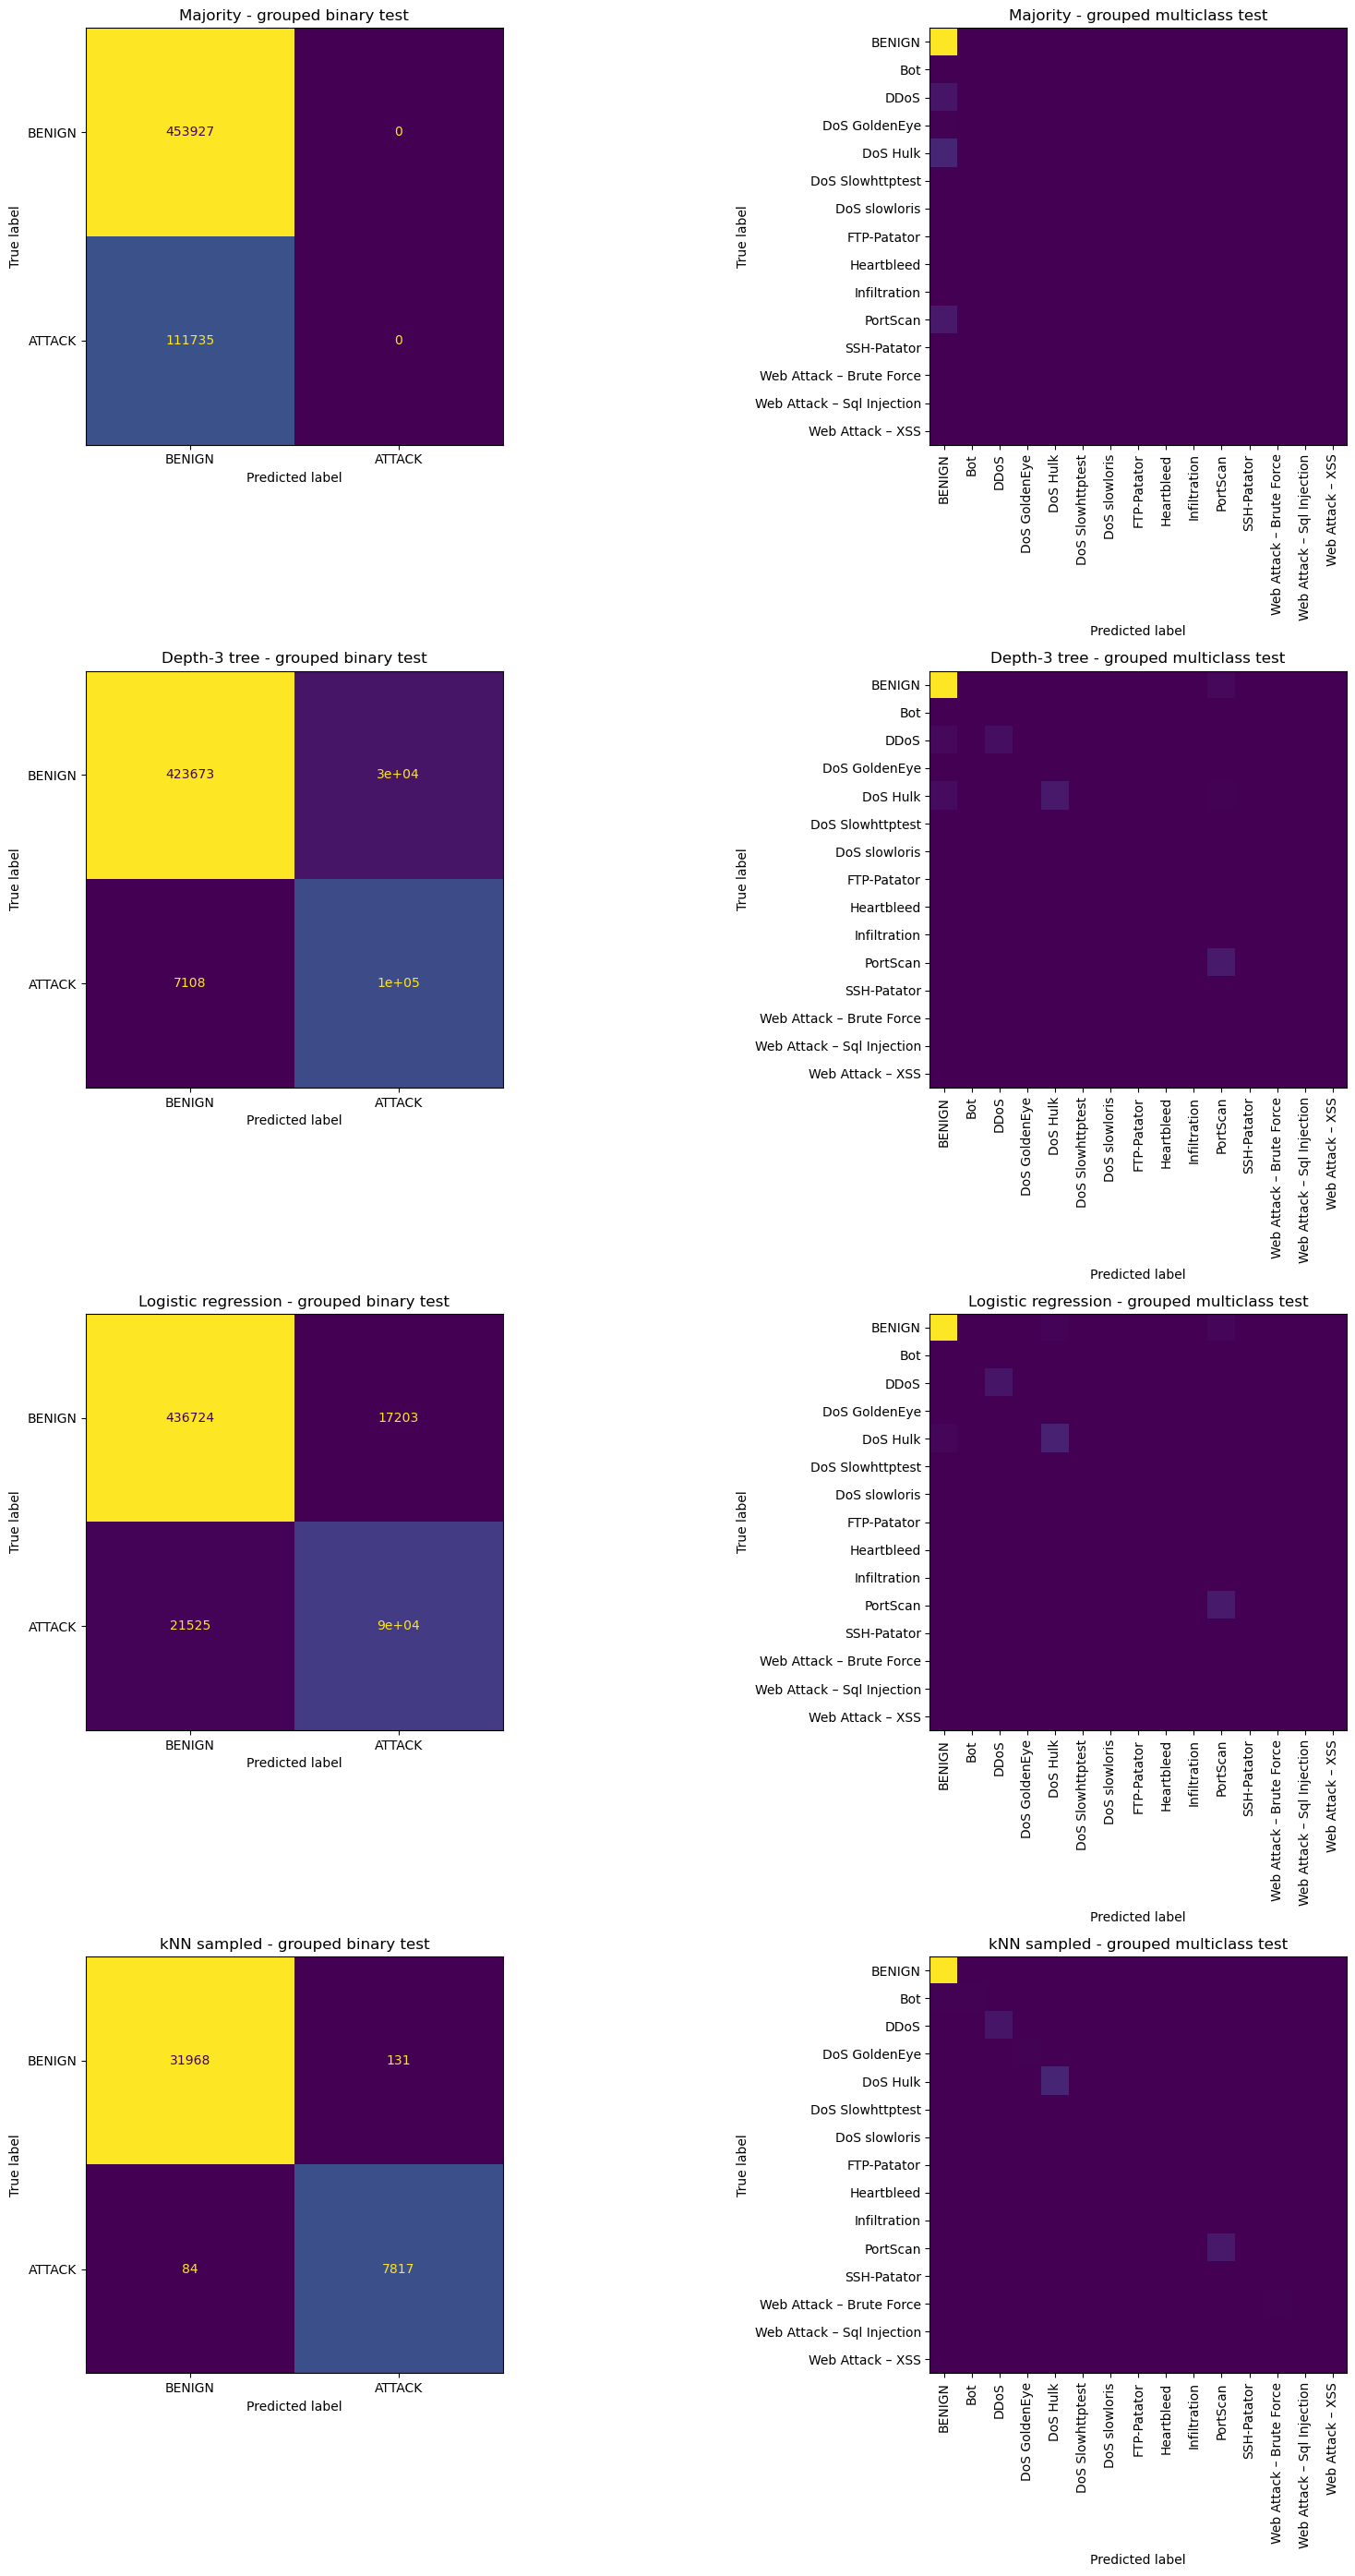

RANDOM VERSUS GROUPED VALIDATION


,random_binary_attack_f1,grouped_binary_attack_f1,random_multiclass_macro_f1,grouped_multiclass_macro_f1,binary_change_grouped_minus_random,multiclass_change_grouped_minus_random
model,,,,,,
Majority,0.000000,0.000000,0.059382,0.059428,0.000000,0.000046
Depth-3 tree,0.848751,0.847928,0.266754,0.289939,-0.000823,0.023185
Logistic regression,0.799830,0.823064,0.456643,0.523754,0.023234,0.067111
kNN,0.985682,0.984545,0.785362,0.737845,-0.001137,-0.047517


In [70]:
# Purpose: Evaluate the selected grouped baselines using the previously held-out test rows.
# Explain: Reuse training preprocessing and frozen C/k; class counts and sampled kNN scope qualify results.

# ============================================================
# TASK 11 - GROUPED TEST SUMMARY AND RANDOM COMPARISON
# ============================================================

# All models and hyperparameters are now frozen. Prepare test features once.
X_grouped_test = df.iloc[
    grouped_test_df_positions,
    grouped_feature_indices,
].to_numpy(dtype=np.float32)

X_grouped_test[~np.isfinite(X_grouped_test)] = np.nan

X_grouped_test = grouped_imputer.transform(
    X_grouped_test
)

# Majority and tree predictions use unscaled features.
grouped_binary_majority_test_predictions = np.full(
    len(y_grouped_test_binary),
    grouped_binary_majority_label,
)

grouped_multiclass_majority_test_predictions = np.full(
    len(y_grouped_test_multiclass),
    grouped_multiclass_majority_label,
    dtype=object,
)

grouped_binary_tree_test_predictions = grouped_binary_tree.predict(
    X_grouped_test
)

grouped_multiclass_tree_test_predictions = (
    grouped_multiclass_tree.predict(X_grouped_test)
)

# Logistic regression and kNN use the training-fitted scaler.
X_grouped_test_scaled = grouped_scaler.transform(
    X_grouped_test
)

grouped_binary_lr_test_predictions = grouped_binary_lr.predict(
    X_grouped_test_scaled
)

grouped_multiclass_lr_test_predictions = (
    grouped_multiclass_lr.predict(X_grouped_test_scaled)
)

# Binary kNN uses a fixed stratified test sample.
grouped_binary_knn_test_indices, _ = train_test_split(
    np.arange(len(y_grouped_test_binary)),
    train_size=40_000,
    stratify=y_grouped_test_binary,
    random_state=42,
)

X_grouped_binary_knn_test = X_grouped_test_scaled[
    grouped_binary_knn_test_indices
]
y_grouped_binary_knn_test = y_grouped_test_binary[
    grouped_binary_knn_test_indices
]

grouped_binary_knn_test_predictions = grouped_binary_knn.predict(
    X_grouped_binary_knn_test
)

# Multiclass kNN adds all test rows from classes with fewer than 1,000 rows.
y_grouped_test_multiclass_array = np.asarray(
    y_grouped_test_multiclass
)

grouped_multiclass_knn_test_indices, _ = train_test_split(
    np.arange(len(y_grouped_test_multiclass_array)),
    train_size=40_000,
    stratify=y_grouped_test_multiclass_array,
    random_state=42,
)

grouped_test_class_counts = pd.Series(
    y_grouped_test_multiclass_array
).value_counts()

grouped_rare_test_classes = grouped_test_class_counts[
    grouped_test_class_counts < 1_000
].index

grouped_rare_test_indices = np.flatnonzero(
    np.isin(
        y_grouped_test_multiclass_array,
        grouped_rare_test_classes,
    )
)

grouped_multiclass_knn_test_indices = np.unique(
    np.concatenate([
        grouped_multiclass_knn_test_indices,
        grouped_rare_test_indices,
    ])
)

X_grouped_multiclass_knn_test = X_grouped_test_scaled[
    grouped_multiclass_knn_test_indices
]
y_grouped_multiclass_knn_test = y_grouped_test_multiclass_array[
    grouped_multiclass_knn_test_indices
]

grouped_multiclass_knn_test_predictions = (
    grouped_multiclass_knn.predict(
        X_grouped_multiclass_knn_test
    )
)

grouped_test_summary = pd.DataFrame({
    "model": [
        "Majority",
        "Depth-3 tree",
        "Logistic regression",
        "kNN",
    ],
    "binary_attack_f1": [
        f1_score(
            y_grouped_test_binary,
            grouped_binary_majority_test_predictions,
            pos_label=1,
            zero_division=0,
        ),
        f1_score(
            y_grouped_test_binary,
            grouped_binary_tree_test_predictions,
            pos_label=1,
            zero_division=0,
        ),
        f1_score(
            y_grouped_test_binary,
            grouped_binary_lr_test_predictions,
            pos_label=1,
            zero_division=0,
        ),
        f1_score(
            y_grouped_binary_knn_test,
            grouped_binary_knn_test_predictions,
            pos_label=1,
            zero_division=0,
        ),
    ],
    "binary_balanced_accuracy": [
        balanced_accuracy_score(
            y_grouped_test_binary,
            grouped_binary_majority_test_predictions,
        ),
        balanced_accuracy_score(
            y_grouped_test_binary,
            grouped_binary_tree_test_predictions,
        ),
        balanced_accuracy_score(
            y_grouped_test_binary,
            grouped_binary_lr_test_predictions,
        ),
        balanced_accuracy_score(
            y_grouped_binary_knn_test,
            grouped_binary_knn_test_predictions,
        ),
    ],
    "binary_macro_f1": [
        f1_score(
            y_grouped_test_binary,
            grouped_binary_majority_test_predictions,
            average="macro",
            zero_division=0,
        ),
        f1_score(
            y_grouped_test_binary,
            grouped_binary_tree_test_predictions,
            average="macro",
            zero_division=0,
        ),
        f1_score(
            y_grouped_test_binary,
            grouped_binary_lr_test_predictions,
            average="macro",
            zero_division=0,
        ),
        f1_score(
            y_grouped_binary_knn_test,
            grouped_binary_knn_test_predictions,
            average="macro",
            zero_division=0,
        ),
    ],
    "binary_weighted_f1": [
        f1_score(
            y_grouped_test_binary,
            grouped_binary_majority_test_predictions,
            average="weighted",
            zero_division=0,
        ),
        f1_score(
            y_grouped_test_binary,
            grouped_binary_tree_test_predictions,
            average="weighted",
            zero_division=0,
        ),
        f1_score(
            y_grouped_test_binary,
            grouped_binary_lr_test_predictions,
            average="weighted",
            zero_division=0,
        ),
        f1_score(
            y_grouped_binary_knn_test,
            grouped_binary_knn_test_predictions,
            average="weighted",
            zero_division=0,
        ),
    ],
    "multiclass_macro_f1": [
        f1_score(
            y_grouped_test_multiclass,
            grouped_multiclass_majority_test_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
        f1_score(
            y_grouped_test_multiclass,
            grouped_multiclass_tree_test_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
        f1_score(
            y_grouped_test_multiclass,
            grouped_multiclass_lr_test_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
        f1_score(
            y_grouped_multiclass_knn_test,
            grouped_multiclass_knn_test_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
    ],
    "multiclass_balanced_accuracy": [
        balanced_accuracy_score(
            y_grouped_test_multiclass,
            grouped_multiclass_majority_test_predictions,
        ),
        balanced_accuracy_score(
            y_grouped_test_multiclass,
            grouped_multiclass_tree_test_predictions,
        ),
        balanced_accuracy_score(
            y_grouped_test_multiclass,
            grouped_multiclass_lr_test_predictions,
        ),
        balanced_accuracy_score(
            y_grouped_multiclass_knn_test,
            grouped_multiclass_knn_test_predictions,
        ),
    ],
    "multiclass_weighted_f1": [
        f1_score(
            y_grouped_test_multiclass,
            grouped_multiclass_majority_test_predictions,
            labels=all_label_order,
            average="weighted",
            zero_division=0,
        ),
        f1_score(
            y_grouped_test_multiclass,
            grouped_multiclass_tree_test_predictions,
            labels=all_label_order,
            average="weighted",
            zero_division=0,
        ),
        f1_score(
            y_grouped_test_multiclass,
            grouped_multiclass_lr_test_predictions,
            labels=all_label_order,
            average="weighted",
            zero_division=0,
        ),
        f1_score(
            y_grouped_multiclass_knn_test,
            grouped_multiclass_knn_test_predictions,
            labels=all_label_order,
            average="weighted",
            zero_division=0,
        ),
    ],
    "test_scope": [
        "full", "full", "full", "sampled"
    ],
}).set_index("model")

print("GROUPED TEST SUMMARY")
display(grouped_test_summary)

# Class-wise test recall, including zero values.
grouped_binary_test_recall = pd.DataFrame({
    "Majority": recall_score(
        y_grouped_test_binary,
        grouped_binary_majority_test_predictions,
        labels=[0, 1],
        average=None,
        zero_division=0,
    ),
    "Depth-3 tree": recall_score(
        y_grouped_test_binary,
        grouped_binary_tree_test_predictions,
        labels=[0, 1],
        average=None,
        zero_division=0,
    ),
    "Logistic regression": recall_score(
        y_grouped_test_binary,
        grouped_binary_lr_test_predictions,
        labels=[0, 1],
        average=None,
        zero_division=0,
    ),
    "kNN sampled": recall_score(
        y_grouped_binary_knn_test,
        grouped_binary_knn_test_predictions,
        labels=[0, 1],
        average=None,
        zero_division=0,
    ),
}, index=["BENIGN", "ATTACK"])

grouped_multiclass_test_recall = pd.DataFrame({
    "Majority": recall_score(
        y_grouped_test_multiclass,
        grouped_multiclass_majority_test_predictions,
        labels=all_label_order,
        average=None,
        zero_division=0,
    ),
    "Depth-3 tree": recall_score(
        y_grouped_test_multiclass,
        grouped_multiclass_tree_test_predictions,
        labels=all_label_order,
        average=None,
        zero_division=0,
    ),
    "Logistic regression": recall_score(
        y_grouped_test_multiclass,
        grouped_multiclass_lr_test_predictions,
        labels=all_label_order,
        average=None,
        zero_division=0,
    ),
    "kNN sampled": recall_score(
        y_grouped_multiclass_knn_test,
        grouped_multiclass_knn_test_predictions,
        labels=all_label_order,
        average=None,
        zero_division=0,
    ),
}, index=all_label_order)

print("BINARY CLASS-WISE TEST RECALL")
display(grouped_binary_test_recall)

print("MULTICLASS CLASS-WISE TEST RECALL")
display(grouped_multiclass_test_recall)

# Test confusion matrices for every model.
grouped_test_predictions = [
    (
        "Majority",
        y_grouped_test_binary,
        grouped_binary_majority_test_predictions,
        y_grouped_test_multiclass,
        grouped_multiclass_majority_test_predictions,
    ),
    (
        "Depth-3 tree",
        y_grouped_test_binary,
        grouped_binary_tree_test_predictions,
        y_grouped_test_multiclass,
        grouped_multiclass_tree_test_predictions,
    ),
    (
        "Logistic regression",
        y_grouped_test_binary,
        grouped_binary_lr_test_predictions,
        y_grouped_test_multiclass,
        grouped_multiclass_lr_test_predictions,
    ),
    (
        "kNN sampled",
        y_grouped_binary_knn_test,
        grouped_binary_knn_test_predictions,
        y_grouped_multiclass_knn_test,
        grouped_multiclass_knn_test_predictions,
    ),
]

fig, axes = plt.subplots(4, 2, figsize=(18, 28))

for row, (
    model_name,
    binary_truth,
    binary_predictions,
    multiclass_truth,
    multiclass_predictions,
) in enumerate(grouped_test_predictions):
    ConfusionMatrixDisplay.from_predictions(
        binary_truth,
        binary_predictions,
        labels=[0, 1],
        display_labels=["BENIGN", "ATTACK"],
        ax=axes[row, 0],
        colorbar=False,
    )
    axes[row, 0].set_title(
        f"{model_name} - grouped binary test"
    )

    ConfusionMatrixDisplay.from_predictions(
        multiclass_truth,
        multiclass_predictions,
        labels=all_label_order,
        display_labels=all_label_order,
        include_values=False,
        ax=axes[row, 1],
        colorbar=False,
    )
    axes[row, 1].set_title(
        f"{model_name} - grouped multiclass test"
    )
    axes[row, 1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

# Compare validation selection metrics with the Part 4 random reference.
random_grouped_validation_comparison = pd.DataFrame({
    "model": [
        "Majority",
        "Depth-3 tree",
        "Logistic regression",
        "kNN",
    ],
    "random_binary_attack_f1": [
        f1_score(
            y_validation_binary,
            binary_majority_predictions,
            pos_label=1,
            zero_division=0,
        ),
        binary_tree_results["attack_f1"],
        binary_lr_results["attack_f1"],
        binary_knn_results["attack_f1"],
    ],
    "grouped_binary_attack_f1": [
        f1_score(
            y_grouped_validation_binary,
            grouped_binary_majority_validation_predictions,
            pos_label=1,
            zero_division=0,
        ),
        f1_score(
            y_grouped_validation_binary,
            grouped_binary_tree_validation_predictions,
            pos_label=1,
            zero_division=0,
        ),
        grouped_binary_lr_results["attack_f1"],
        grouped_binary_knn_results["attack_f1"],
    ],
    "random_multiclass_macro_f1": [
        majority_results.loc["Multiclass", "macro_f1"],
        multiclass_results["macro_f1"],
        multiclass_lr_results["macro_f1"],
        selected_multiclass_knn_results["macro_f1"],
    ],
    "grouped_multiclass_macro_f1": [
        f1_score(
            y_grouped_validation_multiclass,
            grouped_multiclass_majority_validation_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
        f1_score(
            y_grouped_validation_multiclass,
            grouped_multiclass_tree_validation_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
        grouped_multiclass_lr_results["macro_f1"],
        grouped_multiclass_knn_results["macro_f1"],
    ],
}).set_index("model")

random_grouped_validation_comparison[
    "binary_change_grouped_minus_random"
] = (
    random_grouped_validation_comparison[
        "grouped_binary_attack_f1"
    ]
    - random_grouped_validation_comparison[
        "random_binary_attack_f1"
    ]
)

random_grouped_validation_comparison[
    "multiclass_change_grouped_minus_random"
] = (
    random_grouped_validation_comparison[
        "grouped_multiclass_macro_f1"
    ]
    - random_grouped_validation_comparison[
        "random_multiclass_macro_f1"
    ]
)

print("RANDOM VERSUS GROUPED VALIDATION")
display(random_grouped_validation_comparison)

### Final grouped-protocol interpretation

After increasing the logistic-regression iteration limit, the selected value was
C = 1.0 for both prediction tasks. Binary attack F1 was 82.31% on validation and
82.33% on test. Multiclass macro F1 was 52.38% on validation and 51.22% on test.
The small validation-to-test changes indicate stable performance within the
grouped protocol.

For binary detection, the depth-3 tree was the strongest model evaluated on the
complete partition, with an attack F1 of 84.85%. Logistic regression recognized
more benign flows but missed more attacks. Sampled kNN achieved the strongest
result, but it used a computational sample and must be reported separately.

For multiclass detection, logistic regression substantially outperformed the
depth-3 tree. Sampled kNN achieved the highest macro F1, although it remained weak
on Bot and Infiltration. Heartbleed had no grouped test examples, so its zero recall
does not represent an observed classification failure.

The grouped protocol produced results broadly similar to the random protocol,
although multiclass kNN decreased more noticeably. This suggests that keeping
five-tuples together removes some useful near-neighbour similarity, while many
attack patterns still repeat across different network conversations.

# Part 5 - Chronological protocol

**Objective:** Test whether models trained on Monday-Wednesday can classify later traffic from Thursday and Friday.

This protocol preserves time order. Thursday is used only for validation and hyperparameter selection. Friday remains untouched until the final test cell.

In [71]:
# Purpose: Inspect chronological ordering and categories absent from the earlier training period.
# Explain: A closed-set classifier cannot learn named categories that have no training examples.

# ============================================================
# TASK 1 - VERIFY AND SUMMARIZE THE CHRONOLOGICAL PROTOCOL
# ============================================================

chronological_counts_complete = chronological_class_counts.reindex(
    index=all_label_order,
    columns=["train", "validation", "test"],
    fill_value=0,
)

chronological_order_summary = pd.Series({
    "latest_training_end":
        chronological_end[train_chronological_mask].max(),
    "earliest_validation_start":
        chronological_start[validation_chronological_mask].min(),
    "latest_validation_end":
        chronological_end[validation_chronological_mask].max(),
    "earliest_test_start":
        chronological_start[test_chronological_mask].min(),
}, name="time")

print("CHRONOLOGICAL PROTOCOL")
display(chronological_split_summary.to_frame())

print("TIME-ORDER CHECK")
display(chronological_order_summary.to_frame())

print("CLASS COUNTS, INCLUDING ZEROS")
display(chronological_counts_complete)

print("Validation classes absent from training:")
print(chronological_unseen_validation or "None")

print("Test classes absent from training:")
print(chronological_unseen_test or "None")

CHRONOLOGICAL PROTOCOL


,value
training_cutoff,2017-07-06T00:00:00
validation_cutoff,2017-07-07T00:00:00
eligible_rows,2830540
training_rows,1668422
validation_rows,458810
test_rows,703193
flows_crossing_training_boundary,0
flows_crossing_validation_boundary,0
invalid_timing_rows,115


TIME-ORDER CHECK


,time
latest_training_end,2017-07-05 17:10:00.003557
earliest_validation_start,2017-07-06 08:59:00.000000
latest_validation_end,2017-07-06 17:04:24.760927
earliest_test_start,2017-07-07 08:59:00.000000


CLASS COUNTS, INCLUDING ZEROS


partition,train,validation,test
Label,,,
BENIGN,1401916,456594,414270
Bot,0,0,1966
DDoS,0,0,128027
DoS GoldenEye,10293,0,0
DoS Hulk,231072,0,0
DoS Slowhttptest,5499,0,0
DoS slowloris,5796,0,0
FTP-Patator,7938,0,0
Heartbleed,11,0,0


Validation classes absent from training:
['Infiltration', 'Web Attack – Brute Force', 'Web Attack – Sql Injection', 'Web Attack – XSS']
Test classes absent from training:
['Bot', 'DDoS', 'PortScan']


### Interpretation

Training ends before validation begins, and validation ends before test begins. The zero-count classes show that several later attacks are absent from training. These are open-set classes: the multiclass model cannot learn their labels from this training period, so they must remain visible in the evaluation.

In [72]:
# Purpose: Prepare chronological predictors and targets from the saved time-based membership.
# Explain: Constant removal uses earlier training only; later data must not redefine the features.

# ============================================================
# TASK 2 - CHRONOLOGICAL FEATURES, ROWS, AND LABELS
# ============================================================

chronological_constant_features = constant_feature_table.loc[
    (constant_feature_table["protocol"] == "Chronological")
    & (constant_feature_table["status"] == "Constant"),
    "feature",
].tolist()

chronological_features = [
    feature
    for feature in behavior_feature_columns
    if feature not in (
        chronological_constant_features
        + redundant_features_to_remove
    )
]

train_chronological_positions = np.flatnonzero(
    train_chronological_mask.to_numpy()
)
validation_chronological_positions = np.flatnonzero(
    validation_chronological_mask.to_numpy()
)
test_chronological_positions = np.flatnonzero(
    test_chronological_mask.to_numpy()
)

chronological_train_df_positions = model_row_positions[
    train_chronological_positions
]
chronological_validation_df_positions = model_row_positions[
    validation_chronological_positions
]
chronological_test_df_positions = model_row_positions[
    test_chronological_positions
]

y_chronological_train_multiclass = model_labels[
    train_chronological_positions
]
y_chronological_validation_multiclass = model_labels[
    validation_chronological_positions
]
y_chronological_test_multiclass = model_labels[
    test_chronological_positions
]

y_chronological_train_binary = np.where(
    y_chronological_train_multiclass == "BENIGN", 0, 1
)
y_chronological_validation_binary = np.where(
    y_chronological_validation_multiclass == "BENIGN", 0, 1
)
y_chronological_test_binary = np.where(
    y_chronological_test_multiclass == "BENIGN", 0, 1
)

chronological_modeling_summary = pd.Series({
    "behavioral_features_before_treatment":
        len(behavior_feature_columns),
    "chronological_training_constants_removed":
        len(chronological_constant_features),
    "redundant_features_removed":
        len(redundant_features_to_remove),
    "features_retained":
        len(chronological_features),
    "training_rows":
        len(chronological_train_df_positions),
    "validation_rows":
        len(chronological_validation_df_positions),
    "test_rows":
        len(chronological_test_df_positions),
}, name="value")

display(chronological_modeling_summary.to_frame())

,value
behavioral_features_before_treatment,77
chronological_training_constants_removed,10
redundant_features_removed,7
features_retained,60
training_rows,1668422
validation_rows,458810
test_rows,703193


### Interpretation

The same behavioral-feature policy is applied to the chronological protocol. Constant features are identified using chronological training only, and the previously declared redundant features are removed. Binary labels combine every attack category into ATTACK; multiclass labels keep the original categories.

In [73]:
# Purpose: Learn numerical replacement medians from chronological training.
# Explain: Apply the earlier-period imputer unchanged to Thursday validation.

# ============================================================
# TASK 3 - CHRONOLOGICAL TRAIN-ONLY IMPUTATION
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    recall_score,
    ConfusionMatrixDisplay,
)
from sklearn.tree import DecisionTreeClassifier, plot_tree

chronological_feature_indices = df.columns.get_indexer(
    chronological_features
)

X_chronological_train = df.iloc[
    chronological_train_df_positions,
    chronological_feature_indices,
].to_numpy(dtype=np.float32)

X_chronological_validation = df.iloc[
    chronological_validation_df_positions,
    chronological_feature_indices,
].to_numpy(dtype=np.float32)

X_chronological_train[
    ~np.isfinite(X_chronological_train)
] = np.nan
X_chronological_validation[
    ~np.isfinite(X_chronological_validation)
] = np.nan

chronological_imputer = SimpleImputer(
    strategy="median",
    copy=False,
)

X_chronological_train = chronological_imputer.fit_transform(
    X_chronological_train
)
X_chronological_validation = chronological_imputer.transform(
    X_chronological_validation
)

display(pd.Series({
    "training_rows": X_chronological_train.shape[0],
    "validation_rows": X_chronological_validation.shape[0],
    "test_rows_reserved":
        len(chronological_test_df_positions),
    "features": X_chronological_train.shape[1],
}, name="count").to_frame())

,count
training_rows,1668422
validation_rows,458810
test_rows_reserved,703193
features,60


### Interpretation

Missing and infinite values are replaced with medians learned only from Monday-Wednesday training data. The same fixed medians are applied to Thursday. Friday remains untouched until all model settings have been selected.

In [74]:
# Purpose: Measure chronological majority baselines before fitting feature-based classifiers.
# Explain: They show how imbalance and changed category coverage affect trivial predictions.

# ============================================================
# TASK 4 - CHRONOLOGICAL MAJORITY BASELINES
# ============================================================

chronological_binary_majority_label = pd.Series(
    y_chronological_train_binary
).mode()[0]

chronological_multiclass_majority_label = pd.Series(
    y_chronological_train_multiclass
).mode()[0]

chronological_binary_majority_validation_predictions = np.full(
    len(y_chronological_validation_binary),
    chronological_binary_majority_label,
)

chronological_multiclass_majority_validation_predictions = np.full(
    len(y_chronological_validation_multiclass),
    chronological_multiclass_majority_label,
    dtype=object,
)

chronological_majority_results = pd.DataFrame({
    "task": ["Binary", "Multiclass"],
    "validation_balanced_accuracy": [
        balanced_accuracy_score(
            y_chronological_validation_binary,
            chronological_binary_majority_validation_predictions,
        ),
        recall_score(
            y_chronological_validation_multiclass,
            chronological_multiclass_majority_validation_predictions,
            labels=np.unique(
                y_chronological_validation_multiclass
            ),
            average="macro",
            zero_division=0,
        ),
    ],
    "validation_selection_metric": [
        f1_score(
            y_chronological_validation_binary,
            chronological_binary_majority_validation_predictions,
            pos_label=1,
            zero_division=0,
        ),
        f1_score(
            y_chronological_validation_multiclass,
            chronological_multiclass_majority_validation_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
    ],
}).set_index("task")

display(chronological_majority_results)

,validation_balanced_accuracy,validation_selection_metric
task,,
Binary,0.5,0.000000
Multiclass,0.2,0.066505


### Interpretation

The majority models ignore the features and always predict the most frequent training class. They provide the minimum reference result. Because BENIGN dominates the data, weighted scores can look acceptable even when attack recall is zero.

,validation_balanced_accuracy,validation_selection_metric
task,,
Binary,0.454565,0.000874
Multiclass,0.179793,0.062960


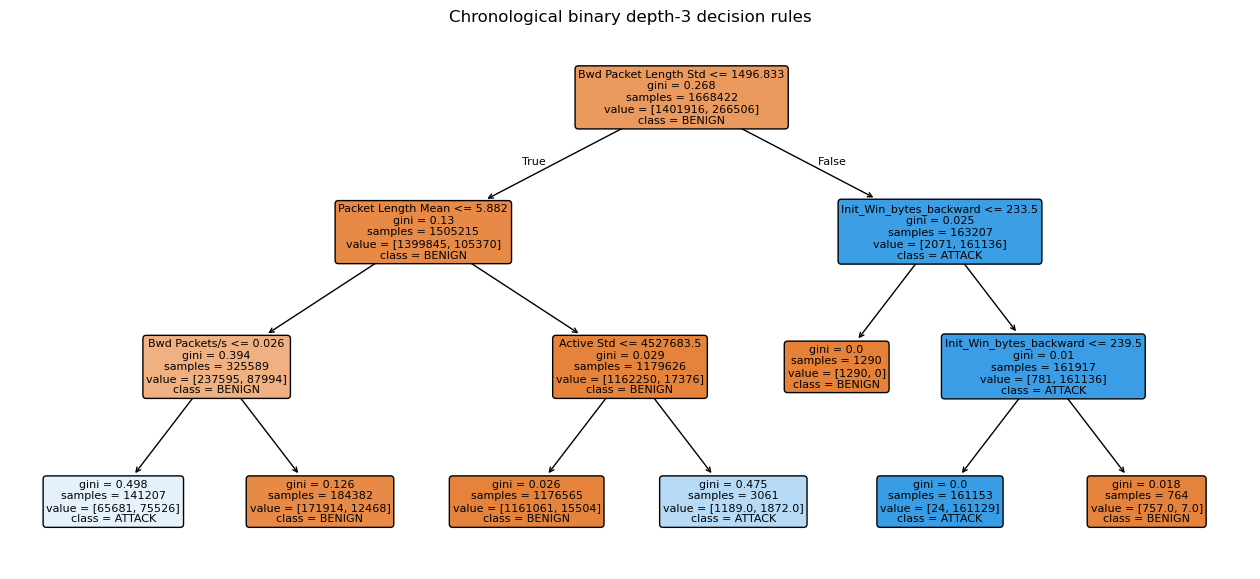

In [75]:
# Purpose: Fit depth-3 trees on earlier chronological training traffic.
# Explain: Poor later performance can reflect unseen mechanisms and changed traffic, not only leakage removal.

# ============================================================
# TASK 5 - CHRONOLOGICAL DEPTH-3 DECISION TREES
# ============================================================

chronological_binary_tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=42,
)
chronological_binary_tree.fit(
    X_chronological_train,
    y_chronological_train_binary,
)
chronological_binary_tree_validation_predictions = (
    chronological_binary_tree.predict(
        X_chronological_validation
    )
)

chronological_multiclass_tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=42,
)
chronological_multiclass_tree.fit(
    X_chronological_train,
    y_chronological_train_multiclass,
)
chronological_multiclass_tree_validation_predictions = (
    chronological_multiclass_tree.predict(
        X_chronological_validation
    )
)

chronological_tree_results = pd.DataFrame({
    "task": ["Binary", "Multiclass"],
    "validation_balanced_accuracy": [
        balanced_accuracy_score(
            y_chronological_validation_binary,
            chronological_binary_tree_validation_predictions,
        ),
        recall_score(
            y_chronological_validation_multiclass,
            chronological_multiclass_tree_validation_predictions,
            labels=np.unique(
                y_chronological_validation_multiclass
            ),
            average="macro",
            zero_division=0,
        ),
    ],
    "validation_selection_metric": [
        f1_score(
            y_chronological_validation_binary,
            chronological_binary_tree_validation_predictions,
            pos_label=1,
            zero_division=0,
        ),
        f1_score(
            y_chronological_validation_multiclass,
            chronological_multiclass_tree_validation_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
    ],
}).set_index("task")

display(chronological_tree_results)

plt.figure(figsize=(16, 7))
plot_tree(
    chronological_binary_tree,
    feature_names=chronological_features,
    class_names=["BENIGN", "ATTACK"],
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.title("Chronological binary depth-3 decision rules")
plt.show()

### Interpretation

The tree depth remains fixed at three, matching the earlier protocols. Its rules show which training-period measurements separate benign and attack flows. A rule may describe network behavior, but it may also depend on conditions specific to the earlier collection days.

In [76]:
# Purpose: Fit the scaler on chronological training and transform later validation.
# Explain: Do not recompute means or scales on the future traffic being evaluated.

# ============================================================
# TASK 6 - CHRONOLOGICAL TRAIN-ONLY SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler

chronological_scaler = StandardScaler(copy=False)

X_chronological_train_scaled = (
    chronological_scaler.fit_transform(
        X_chronological_train
    )
)

X_chronological_validation_scaled = (
    chronological_scaler.transform(
        X_chronological_validation
    )
)

print("Scaling fitted on chronological training only.")

Scaling fitted on chronological training only.


### Interpretation

Scaling is required for logistic regression and kNN because their calculations depend on feature magnitudes. The means and standard deviations come only from Monday-Wednesday training data and are applied unchanged to Thursday.

In [77]:
# Purpose: Choose binary chronological logistic C using Thursday attack F1.
# Explain: Friday is reserved for final evaluation; binary labels still leave unseen attack mechanisms.

# ============================================================
# TASK 7 - CHRONOLOGICAL BINARY LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression

chronological_tested_C = [0.01, 0.1, 1.0]
chronological_binary_lr_tuning = []
chronological_binary_lr_models = {}
chronological_binary_lr_predictions_by_C = {}

for C in chronological_tested_C:
    model = LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=500,
        random_state=42,
    )
    model.fit(
        X_chronological_train_scaled,
        y_chronological_train_binary,
    )
    predictions = model.predict(
        X_chronological_validation_scaled
    )

    chronological_binary_lr_tuning.append({
        "C": C,
        "attack_f1": f1_score(
            y_chronological_validation_binary,
            predictions,
            pos_label=1,
            zero_division=0,
        ),
    })
    chronological_binary_lr_models[C] = model
    chronological_binary_lr_predictions_by_C[C] = predictions

chronological_binary_lr_tuning = pd.DataFrame(
    chronological_binary_lr_tuning
)
display(chronological_binary_lr_tuning)

chronological_best_binary_C = (
    chronological_binary_lr_tuning.loc[
        chronological_binary_lr_tuning[
            "attack_f1"
        ].idxmax(),
        "C",
    ]
)

chronological_binary_lr = chronological_binary_lr_models[
    chronological_best_binary_C
]
chronological_binary_lr_validation_predictions = (
    chronological_binary_lr_predictions_by_C[
        chronological_best_binary_C
    ]
)

chronological_binary_lr_results = pd.Series({
    "selected_C": chronological_best_binary_C,
    "balanced_accuracy": balanced_accuracy_score(
        y_chronological_validation_binary,
        chronological_binary_lr_validation_predictions,
    ),
    "attack_f1": f1_score(
        y_chronological_validation_binary,
        chronological_binary_lr_validation_predictions,
        pos_label=1,
        zero_division=0,
    ),
    "macro_f1": f1_score(
        y_chronological_validation_binary,
        chronological_binary_lr_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        y_chronological_validation_binary,
        chronological_binary_lr_validation_predictions,
        average="weighted",
        zero_division=0,
    ),
}, name="validation")

display(chronological_binary_lr_results)

,C,attack_f1
0,0.01,0.000331
1,0.10,0.000338
2,1.00,0.000337


selected_C           0.100000
balanced_accuracy    0.464902
attack_f1            0.000338
macro_f1             0.480048
weighted_f1          0.955125
Name: validation, dtype: float64

### Interpretation

The regularization value C is selected using Thursday attack F1. This tests whether a binary detector trained on earlier attack mechanisms can still recognize later traffic as malicious. The selected C is frozen before Friday is evaluated.

In [78]:
# Purpose: Choose multiclass chronological logistic C using Thursday macro-F1.
# Explain: Interpret scores alongside zero-count and unseen categories rather than hiding them.

# ============================================================
# TASK 8 - CHRONOLOGICAL MULTICLASS LOGISTIC REGRESSION
# ============================================================

chronological_multiclass_lr_tuning = []
chronological_multiclass_lr_models = {}
chronological_multiclass_lr_predictions_by_C = {}

for C in chronological_tested_C:
    model = LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=800,
        random_state=42,
    )
    model.fit(
        X_chronological_train_scaled,
        y_chronological_train_multiclass,
    )
    predictions = model.predict(
        X_chronological_validation_scaled
    )

    chronological_multiclass_lr_tuning.append({
        "C": C,
        "macro_f1": f1_score(
            y_chronological_validation_multiclass,
            predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
    })
    chronological_multiclass_lr_models[C] = model
    chronological_multiclass_lr_predictions_by_C[C] = (
        predictions
    )

chronological_multiclass_lr_tuning = pd.DataFrame(
    chronological_multiclass_lr_tuning
)
display(chronological_multiclass_lr_tuning)

chronological_best_multiclass_C = (
    chronological_multiclass_lr_tuning.loc[
        chronological_multiclass_lr_tuning[
            "macro_f1"
        ].idxmax(),
        "C",
    ]
)

chronological_multiclass_lr = (
    chronological_multiclass_lr_models[
        chronological_best_multiclass_C
    ]
)
chronological_multiclass_lr_validation_predictions = (
    chronological_multiclass_lr_predictions_by_C[
        chronological_best_multiclass_C
    ]
)

chronological_multiclass_lr_results = pd.Series({
    "selected_C": chronological_best_multiclass_C,
    "balanced_accuracy": recall_score(
        y_chronological_validation_multiclass,
        chronological_multiclass_lr_validation_predictions,
        labels=np.unique(
            y_chronological_validation_multiclass
        ),
        average="macro",
        zero_division=0,
    ),
    "macro_f1": f1_score(
        y_chronological_validation_multiclass,
        chronological_multiclass_lr_validation_predictions,
        labels=all_label_order,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        y_chronological_validation_multiclass,
        chronological_multiclass_lr_validation_predictions,
        labels=all_label_order,
        average="weighted",
        zero_division=0,
    ),
}, name="validation")

display(chronological_multiclass_lr_results)

,C,macro_f1
0,0.01,0.066304
1,0.10,0.065262
2,1.00,0.063945


selected_C           0.010000
balanced_accuracy    0.198794
macro_f1             0.066304
weighted_f1          0.989757
Name: validation, dtype: float64

### Interpretation

C is selected using Thursday macro F1, which gives equal importance to every declared category. However, Thursday contains attack categories absent from chronological training. Their expected recall is zero because the classifier has never learned those output classes; this is an open-set limitation, not a preprocessing error.

In [79]:
# Purpose: Select binary chronological kNN using fixed earlier/later samples.
# Explain: Scaling and training membership are fixed; validation attack F1 selects k.

# ============================================================
# TASK 9 - CHRONOLOGICAL BINARY kNN
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

chronological_binary_knn_train_indices, _ = train_test_split(
    np.arange(len(y_chronological_train_binary)),
    train_size=100_000,
    stratify=y_chronological_train_binary,
    random_state=42,
)

chronological_binary_knn_validation_indices, _ = (
    train_test_split(
        np.arange(
            len(y_chronological_validation_binary)
        ),
        train_size=40_000,
        stratify=y_chronological_validation_binary,
        random_state=42,
    )
)

X_chronological_binary_knn_train = (
    X_chronological_train_scaled[
        chronological_binary_knn_train_indices
    ]
)
y_chronological_binary_knn_train = (
    y_chronological_train_binary[
        chronological_binary_knn_train_indices
    ]
)

X_chronological_binary_knn_validation = (
    X_chronological_validation_scaled[
        chronological_binary_knn_validation_indices
    ]
)
y_chronological_binary_knn_validation = (
    y_chronological_validation_binary[
        chronological_binary_knn_validation_indices
    ]
)

chronological_tested_k = [3, 5, 11]
chronological_binary_knn_tuning = []
chronological_binary_knn_models = {}
chronological_binary_knn_predictions_by_k = {}

for k in chronological_tested_k:
    model = KNeighborsClassifier(
        n_neighbors=k,
        n_jobs=-1,
    )
    model.fit(
        X_chronological_binary_knn_train,
        y_chronological_binary_knn_train,
    )
    predictions = model.predict(
        X_chronological_binary_knn_validation
    )

    chronological_binary_knn_tuning.append({
        "k": k,
        "attack_f1": f1_score(
            y_chronological_binary_knn_validation,
            predictions,
            pos_label=1,
            zero_division=0,
        ),
    })
    chronological_binary_knn_models[k] = model
    chronological_binary_knn_predictions_by_k[k] = (
        predictions
    )

chronological_binary_knn_tuning = pd.DataFrame(
    chronological_binary_knn_tuning
)
display(chronological_binary_knn_tuning)

chronological_best_binary_k = int(
    chronological_binary_knn_tuning.loc[
        chronological_binary_knn_tuning[
            "attack_f1"
        ].idxmax(),
        "k",
    ]
)

chronological_binary_knn = chronological_binary_knn_models[
    chronological_best_binary_k
]
chronological_binary_knn_validation_predictions = (
    chronological_binary_knn_predictions_by_k[
        chronological_best_binary_k
    ]
)

chronological_binary_knn_results = pd.Series({
    "selected_k": chronological_best_binary_k,
    "balanced_accuracy": balanced_accuracy_score(
        y_chronological_binary_knn_validation,
        chronological_binary_knn_validation_predictions,
    ),
    "attack_f1": f1_score(
        y_chronological_binary_knn_validation,
        chronological_binary_knn_validation_predictions,
        pos_label=1,
        zero_division=0,
    ),
    "macro_f1": f1_score(
        y_chronological_binary_knn_validation,
        chronological_binary_knn_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        y_chronological_binary_knn_validation,
        chronological_binary_knn_validation_predictions,
        average="weighted",
        zero_division=0,
    ),
}, name="sampled_validation")

display(chronological_binary_knn_results)

,k,attack_f1
0,3,0.040404
1,5,0.039216
2,11,0.024465


selected_k           3.000000
balanced_accuracy    0.514313
attack_f1            0.040404
macro_f1             0.518414
weighted_f1          0.991811
Name: sampled_validation, dtype: float64

### Interpretation

Binary kNN selects k using attack F1 on fixed samples taken only from the chronological training and validation partitions. Sampling is a declared computational limitation. The chronological ordering itself is unchanged.

In [80]:
# Purpose: Select multiclass chronological kNN on declared samples with rare-class handling.
# Explain: It cannot identify a never-trained attack name merely because its neighbors are close.

# ============================================================
# TASK 10 - CHRONOLOGICAL MULTICLASS kNN
# ============================================================

y_chronological_train_multiclass_array = np.asarray(
    y_chronological_train_multiclass
)
y_chronological_validation_multiclass_array = np.asarray(
    y_chronological_validation_multiclass
)

chronological_multiclass_knn_train_indices, _ = (
    train_test_split(
        np.arange(
            len(y_chronological_train_multiclass_array)
        ),
        train_size=100_000,
        stratify=y_chronological_train_multiclass_array,
        random_state=42,
    )
)

chronological_multiclass_knn_validation_indices, _ = (
    train_test_split(
        np.arange(
            len(
                y_chronological_validation_multiclass_array
            )
        ),
        train_size=40_000,
        stratify=(
            y_chronological_validation_multiclass_array
        ),
        random_state=42,
    )
)

chronological_train_class_counts = pd.Series(
    y_chronological_train_multiclass_array
).value_counts()
chronological_validation_class_counts = pd.Series(
    y_chronological_validation_multiclass_array
).value_counts()

chronological_rare_train_classes = (
    chronological_train_class_counts[
        chronological_train_class_counts < 1_000
    ].index
)
chronological_rare_validation_classes = (
    chronological_validation_class_counts[
        chronological_validation_class_counts < 1_000
    ].index
)

chronological_rare_train_indices = np.flatnonzero(
    np.isin(
        y_chronological_train_multiclass_array,
        chronological_rare_train_classes,
    )
)
chronological_rare_validation_indices = np.flatnonzero(
    np.isin(
        y_chronological_validation_multiclass_array,
        chronological_rare_validation_classes,
    )
)

chronological_multiclass_knn_train_indices = np.unique(
    np.concatenate([
        chronological_multiclass_knn_train_indices,
        chronological_rare_train_indices,
    ])
)
chronological_multiclass_knn_validation_indices = (
    np.unique(
        np.concatenate([
            chronological_multiclass_knn_validation_indices,
            chronological_rare_validation_indices,
        ])
    )
)

X_chronological_multiclass_knn_train = (
    X_chronological_train_scaled[
        chronological_multiclass_knn_train_indices
    ]
)
y_chronological_multiclass_knn_train = (
    y_chronological_train_multiclass_array[
        chronological_multiclass_knn_train_indices
    ]
)

X_chronological_multiclass_knn_validation = (
    X_chronological_validation_scaled[
        chronological_multiclass_knn_validation_indices
    ]
)
y_chronological_multiclass_knn_validation = (
    y_chronological_validation_multiclass_array[
        chronological_multiclass_knn_validation_indices
    ]
)

chronological_multiclass_knn_sample_counts = pd.DataFrame({
    "training_sample": pd.Series(
        y_chronological_multiclass_knn_train
    ).value_counts(),
    "validation_sample": pd.Series(
        y_chronological_multiclass_knn_validation
    ).value_counts(),
}).reindex(all_label_order).fillna(0).astype(int)

display(chronological_multiclass_knn_sample_counts)

chronological_multiclass_knn_tuning = []
chronological_multiclass_knn_models = {}
chronological_multiclass_knn_predictions_by_k = {}

for k in chronological_tested_k:
    model = KNeighborsClassifier(
        n_neighbors=k,
        n_jobs=-1,
    )
    model.fit(
        X_chronological_multiclass_knn_train,
        y_chronological_multiclass_knn_train,
    )
    predictions = model.predict(
        X_chronological_multiclass_knn_validation
    )

    chronological_multiclass_knn_tuning.append({
        "k": k,
        "macro_f1": f1_score(
            y_chronological_multiclass_knn_validation,
            predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
    })
    chronological_multiclass_knn_models[k] = model
    chronological_multiclass_knn_predictions_by_k[k] = (
        predictions
    )

chronological_multiclass_knn_tuning = pd.DataFrame(
    chronological_multiclass_knn_tuning
)
display(chronological_multiclass_knn_tuning)

chronological_best_multiclass_k = int(
    chronological_multiclass_knn_tuning.loc[
        chronological_multiclass_knn_tuning[
            "macro_f1"
        ].idxmax(),
        "k",
    ]
)

chronological_multiclass_knn = (
    chronological_multiclass_knn_models[
        chronological_best_multiclass_k
    ]
)
chronological_multiclass_knn_validation_predictions = (
    chronological_multiclass_knn_predictions_by_k[
        chronological_best_multiclass_k
    ]
)

chronological_multiclass_knn_results = pd.Series({
    "selected_k": chronological_best_multiclass_k,
    "balanced_accuracy": recall_score(
        y_chronological_multiclass_knn_validation,
        chronological_multiclass_knn_validation_predictions,
        labels=np.unique(
            y_chronological_multiclass_knn_validation
        ),
        average="macro",
        zero_division=0,
    ),
    "macro_f1": f1_score(
        y_chronological_multiclass_knn_validation,
        chronological_multiclass_knn_validation_predictions,
        labels=all_label_order,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        y_chronological_multiclass_knn_validation,
        chronological_multiclass_knn_validation_predictions,
        labels=all_label_order,
        average="weighted",
        zero_division=0,
    ),
}, name="sampled_validation")

display(chronological_multiclass_knn_results)

,training_sample,validation_sample
Label,,
BENIGN,84026,39807
Bot,0,0
DDoS,0,0
DoS GoldenEye,617,0
DoS Hulk,13850,0
DoS Slowhttptest,330,0
DoS slowloris,347,0
FTP-Patator,476,0
Heartbleed,11,0


,k,macro_f1
0,3,0.065904
1,5,0.065892
2,11,0.065874


selected_k           3.000000
balanced_accuracy    0.199508
macro_f1             0.065904
weighted_f1          0.968131
Name: sampled_validation, dtype: float64

### Interpretation

Multiclass kNN selects k using sampled Thursday macro F1. Every available row from a class containing fewer than 1,000 examples is added to the relevant sample. This prevents rare classes from disappearing, but it cannot teach the model a class that is absent from chronological training.

CHRONOLOGICAL TEST SUMMARY


,binary_attack_f1,binary_balanced_accuracy,binary_macro_f1,binary_weighted_f1,multiclass_macro_f1,multiclass_balanced_accuracy,multiclass_weighted_f1,test_scope
model,,,,,,,,
Majority,0.000000,0.500000,0.370724,0.436807,0.049430,0.250000,0.436807,full
Depth-3 tree,0.001763,0.486679,0.365197,0.429980,0.052353,0.242903,0.462636,full
Logistic regression,0.434560,0.634534,0.613878,0.645842,0.052855,0.246455,0.467078,full
kNN sampled,0.425296,0.634403,0.610792,0.643857,0.053054,0.249417,0.468835,sampled


BINARY CLASS-WISE TEST RECALL


,Majority,Depth-3 tree,Logistic regression,kNN sampled
BENIGN,1.0,0.972441,0.985833,0.997921
ATTACK,0.0,0.000917,0.283235,0.270885


MULTICLASS CLASS-WISE TEST RECALL


,Majority,Depth-3 tree,Logistic regression,kNN sampled
Label,,,,
BENIGN,1.0,0.97161,0.985818,0.997666
Bot,0.0,0.00000,0.000000,0.000000
DDoS,0.0,0.00000,0.000000,0.000000
DoS GoldenEye,0.0,0.00000,0.000000,0.000000
DoS Hulk,0.0,0.00000,0.000000,0.000000
DoS Slowhttptest,0.0,0.00000,0.000000,0.000000
DoS slowloris,0.0,0.00000,0.000000,0.000000
FTP-Patator,0.0,0.00000,0.000000,0.000000
Heartbleed,0.0,0.00000,0.000000,0.000000


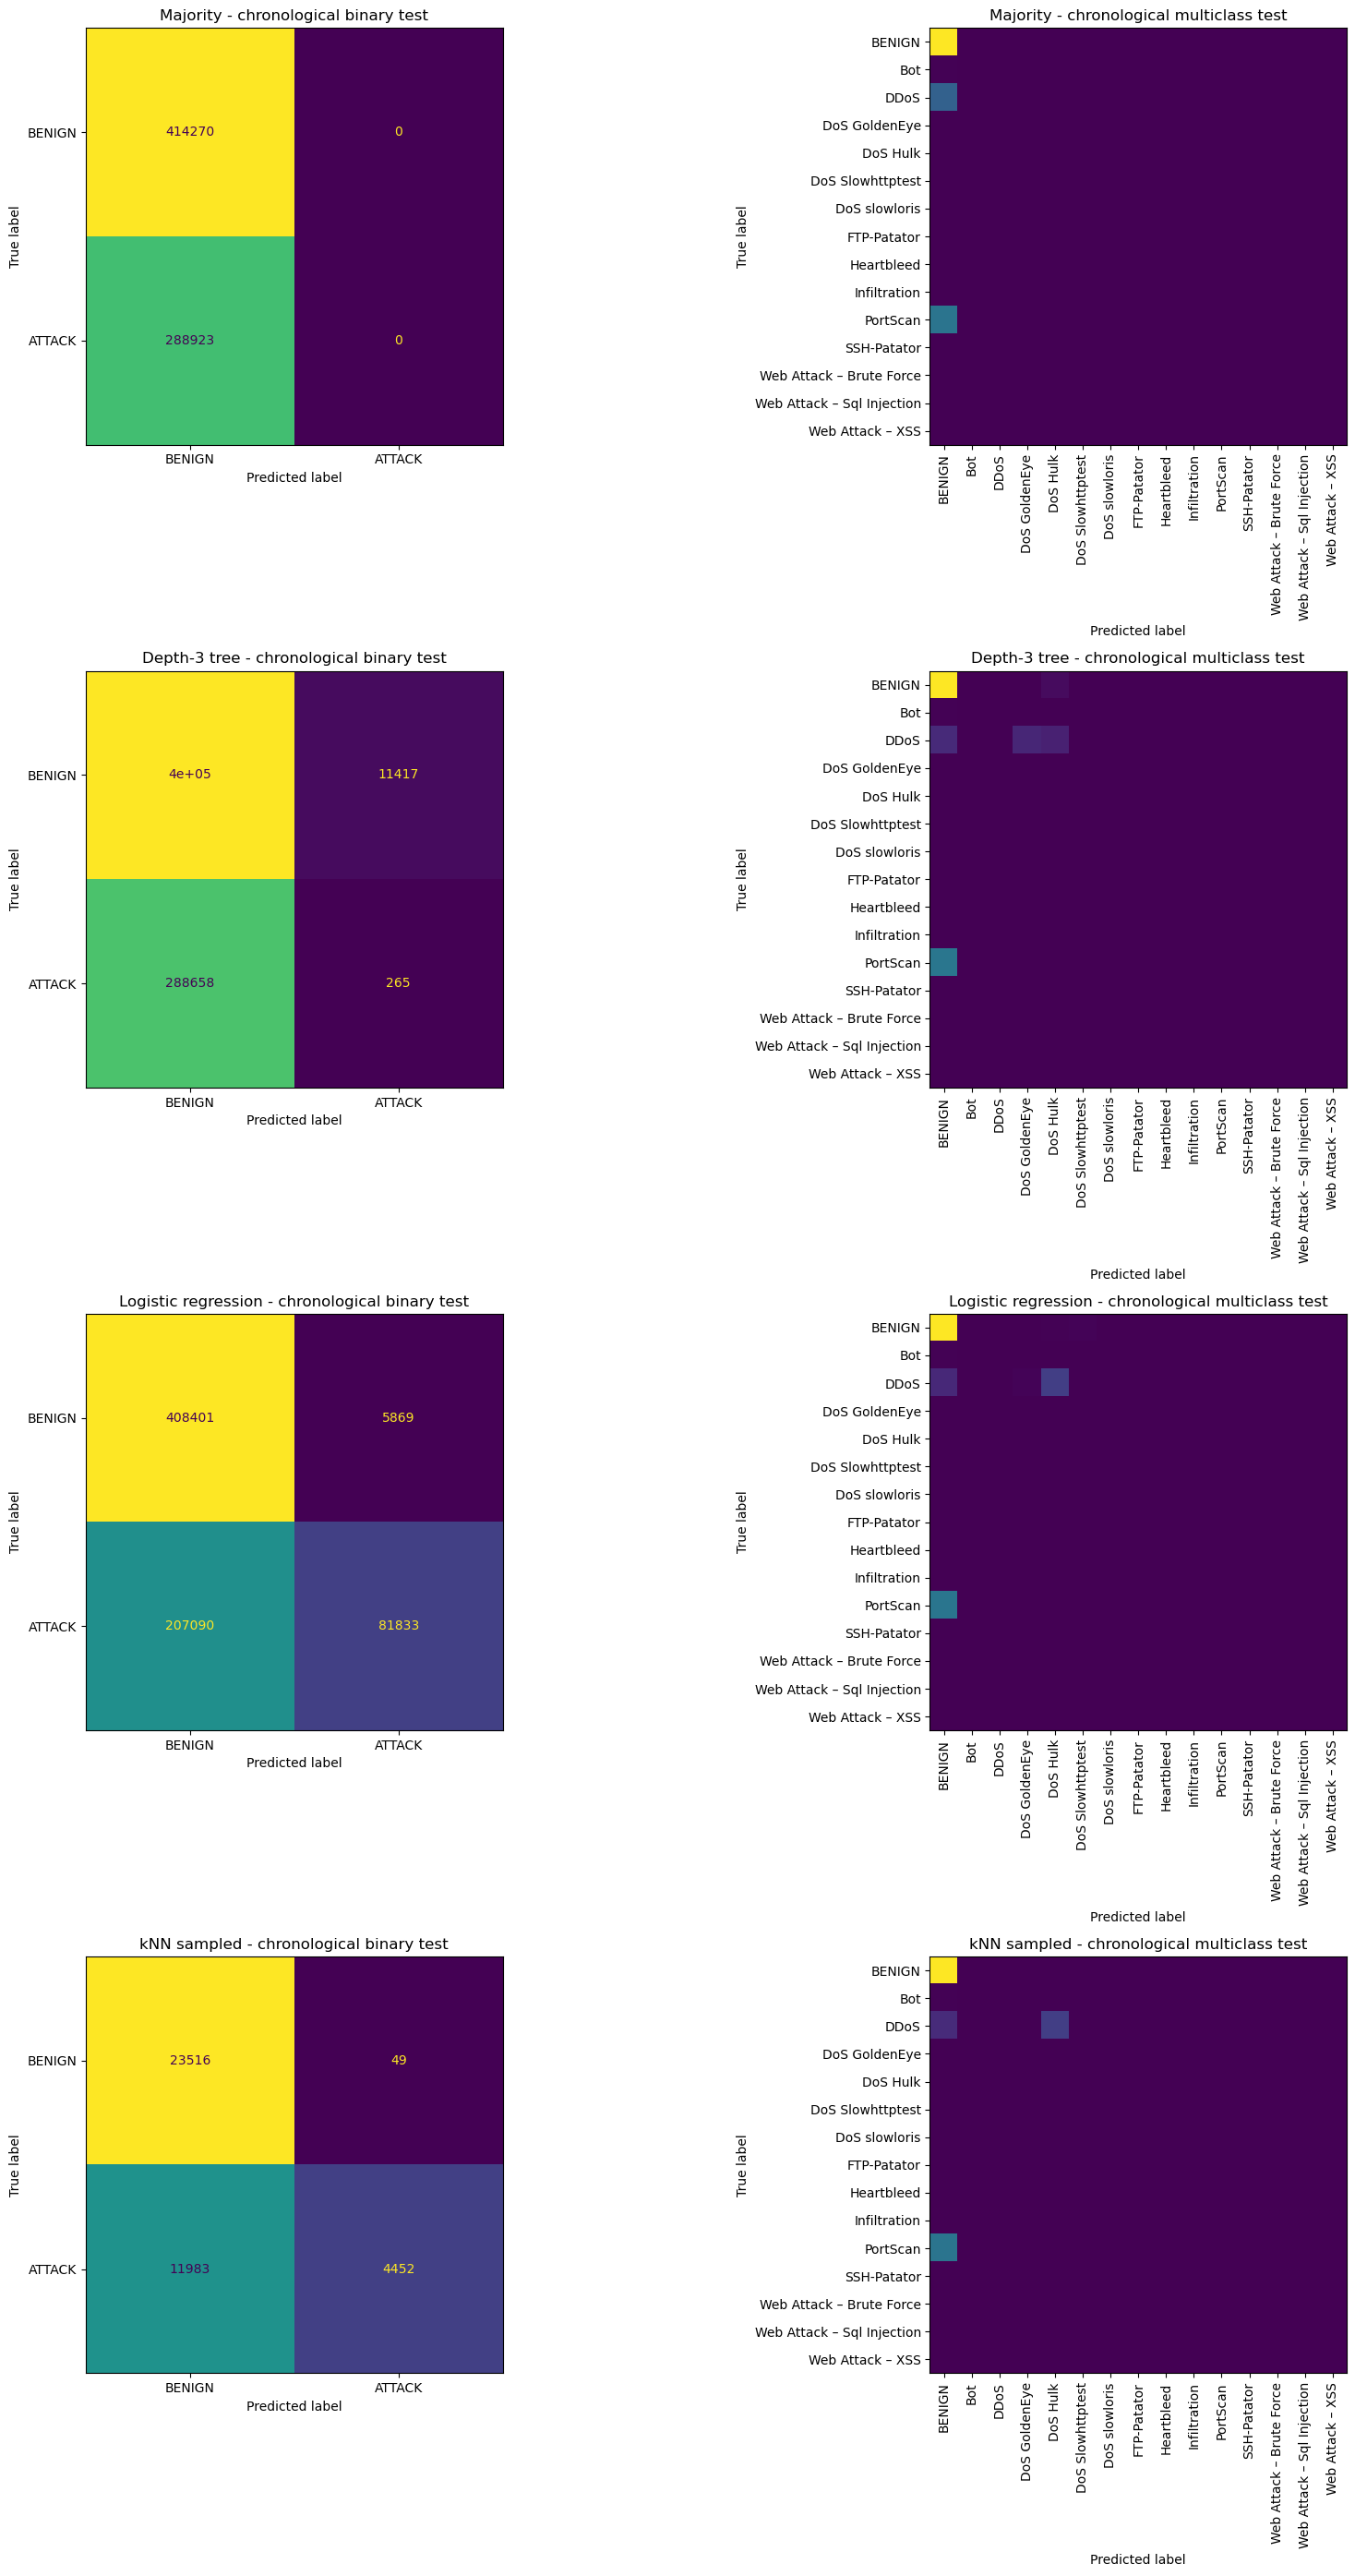

VALIDATION COMPARISON ACROSS PROTOCOLS


binary_attack_f1  multiclass_macro_f1
protocol      model                                                     
Random        Depth-3 tree                 0.848751             0.266754
              Logistic regression          0.799830             0.456643
              kNN sampled                  0.985682             0.785362
Grouped       Depth-3 tree                 0.847928             0.289939
              Logistic regression          0.823064             0.523754
              kNN sampled                  0.984545             0.737845
Chronological Depth-3 tree                 0.000874             0.062960
              Logistic regression          0.000338             0.066304
              kNN sampled                  0.040404             0.065904

In [81]:
# Purpose: Evaluate frozen chronological pipelines on Friday test traffic.
# Explain: Compare outcomes with their class coverage and sample scopes; do not retune on Friday.

# ============================================================
# TASK 11 - CHRONOLOGICAL TEST AND PROTOCOL COMPARISON
# ============================================================

# All model choices are frozen. Friday is prepared only now.
X_chronological_test = df.iloc[
    chronological_test_df_positions,
    chronological_feature_indices,
].to_numpy(dtype=np.float32)

X_chronological_test[
    ~np.isfinite(X_chronological_test)
] = np.nan

X_chronological_test = chronological_imputer.transform(
    X_chronological_test
)

chronological_binary_majority_test_predictions = np.full(
    len(y_chronological_test_binary),
    chronological_binary_majority_label,
)
chronological_multiclass_majority_test_predictions = np.full(
    len(y_chronological_test_multiclass),
    chronological_multiclass_majority_label,
    dtype=object,
)

chronological_binary_tree_test_predictions = (
    chronological_binary_tree.predict(
        X_chronological_test
    )
)
chronological_multiclass_tree_test_predictions = (
    chronological_multiclass_tree.predict(
        X_chronological_test
    )
)

X_chronological_test_scaled = (
    chronological_scaler.transform(
        X_chronological_test
    )
)

chronological_binary_lr_test_predictions = (
    chronological_binary_lr.predict(
        X_chronological_test_scaled
    )
)
chronological_multiclass_lr_test_predictions = (
    chronological_multiclass_lr.predict(
        X_chronological_test_scaled
    )
)

chronological_binary_knn_test_indices, _ = (
    train_test_split(
        np.arange(len(y_chronological_test_binary)),
        train_size=40_000,
        stratify=y_chronological_test_binary,
        random_state=42,
    )
)

X_chronological_binary_knn_test = (
    X_chronological_test_scaled[
        chronological_binary_knn_test_indices
    ]
)
y_chronological_binary_knn_test = (
    y_chronological_test_binary[
        chronological_binary_knn_test_indices
    ]
)
chronological_binary_knn_test_predictions = (
    chronological_binary_knn.predict(
        X_chronological_binary_knn_test
    )
)

y_chronological_test_multiclass_array = np.asarray(
    y_chronological_test_multiclass
)

chronological_multiclass_knn_test_indices, _ = (
    train_test_split(
        np.arange(
            len(y_chronological_test_multiclass_array)
        ),
        train_size=40_000,
        stratify=y_chronological_test_multiclass_array,
        random_state=42,
    )
)

chronological_test_class_counts = pd.Series(
    y_chronological_test_multiclass_array
).value_counts()
chronological_rare_test_classes = (
    chronological_test_class_counts[
        chronological_test_class_counts < 1_000
    ].index
)
chronological_rare_test_indices = np.flatnonzero(
    np.isin(
        y_chronological_test_multiclass_array,
        chronological_rare_test_classes,
    )
)

chronological_multiclass_knn_test_indices = np.unique(
    np.concatenate([
        chronological_multiclass_knn_test_indices,
        chronological_rare_test_indices,
    ])
)

X_chronological_multiclass_knn_test = (
    X_chronological_test_scaled[
        chronological_multiclass_knn_test_indices
    ]
)
y_chronological_multiclass_knn_test = (
    y_chronological_test_multiclass_array[
        chronological_multiclass_knn_test_indices
    ]
)
chronological_multiclass_knn_test_predictions = (
    chronological_multiclass_knn.predict(
        X_chronological_multiclass_knn_test
    )
)

chronological_test_predictions = {
    "Majority": (
        y_chronological_test_binary,
        chronological_binary_majority_test_predictions,
        y_chronological_test_multiclass,
        chronological_multiclass_majority_test_predictions,
    ),
    "Depth-3 tree": (
        y_chronological_test_binary,
        chronological_binary_tree_test_predictions,
        y_chronological_test_multiclass,
        chronological_multiclass_tree_test_predictions,
    ),
    "Logistic regression": (
        y_chronological_test_binary,
        chronological_binary_lr_test_predictions,
        y_chronological_test_multiclass,
        chronological_multiclass_lr_test_predictions,
    ),
    "kNN sampled": (
        y_chronological_binary_knn_test,
        chronological_binary_knn_test_predictions,
        y_chronological_multiclass_knn_test,
        chronological_multiclass_knn_test_predictions,
    ),
}

chronological_test_rows = []

for model_name, (
    binary_truth,
    binary_predictions,
    multiclass_truth,
    multiclass_predictions,
) in chronological_test_predictions.items():
    chronological_test_rows.append({
        "model": model_name,
        "binary_attack_f1": f1_score(
            binary_truth,
            binary_predictions,
            pos_label=1,
            zero_division=0,
        ),
        "binary_balanced_accuracy":
            balanced_accuracy_score(
                binary_truth,
                binary_predictions,
            ),
        "binary_macro_f1": f1_score(
            binary_truth,
            binary_predictions,
            average="macro",
            zero_division=0,
        ),
        "binary_weighted_f1": f1_score(
            binary_truth,
            binary_predictions,
            average="weighted",
            zero_division=0,
        ),
        "multiclass_macro_f1": f1_score(
            multiclass_truth,
            multiclass_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
        "multiclass_balanced_accuracy": recall_score(
            multiclass_truth,
            multiclass_predictions,
            labels=np.unique(multiclass_truth),
            average="macro",
            zero_division=0,
        ),
        "multiclass_weighted_f1": f1_score(
            multiclass_truth,
            multiclass_predictions,
            labels=all_label_order,
            average="weighted",
            zero_division=0,
        ),
        "test_scope":
            "sampled"
            if model_name == "kNN sampled"
            else "full",
    })

chronological_test_summary = pd.DataFrame(
    chronological_test_rows
).set_index("model")

print("CHRONOLOGICAL TEST SUMMARY")
display(chronological_test_summary)

chronological_binary_test_recall = pd.DataFrame({
    model_name: recall_score(
        binary_truth,
        binary_predictions,
        labels=[0, 1],
        average=None,
        zero_division=0,
    )
    for model_name, (
        binary_truth,
        binary_predictions,
        _,
        _,
    ) in chronological_test_predictions.items()
}, index=["BENIGN", "ATTACK"])

chronological_multiclass_test_recall = pd.DataFrame({
    model_name: recall_score(
        multiclass_truth,
        multiclass_predictions,
        labels=all_label_order,
        average=None,
        zero_division=0,
    )
    for model_name, (
        _,
        _,
        multiclass_truth,
        multiclass_predictions,
    ) in chronological_test_predictions.items()
}, index=all_label_order)

print("BINARY CLASS-WISE TEST RECALL")
display(chronological_binary_test_recall)

print("MULTICLASS CLASS-WISE TEST RECALL")
display(chronological_multiclass_test_recall)

fig, axes = plt.subplots(4, 2, figsize=(18, 28))

for row, (
    model_name,
    (
        binary_truth,
        binary_predictions,
        multiclass_truth,
        multiclass_predictions,
    ),
) in enumerate(chronological_test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        binary_truth,
        binary_predictions,
        labels=[0, 1],
        display_labels=["BENIGN", "ATTACK"],
        ax=axes[row, 0],
        colorbar=False,
    )
    axes[row, 0].set_title(
        f"{model_name} - chronological binary test"
    )

    ConfusionMatrixDisplay.from_predictions(
        multiclass_truth,
        multiclass_predictions,
        labels=all_label_order,
        display_labels=all_label_order,
        include_values=False,
        ax=axes[row, 1],
        colorbar=False,
    )
    axes[row, 1].set_title(
        f"{model_name} - chronological multiclass test"
    )
    axes[row, 1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

protocol_validation_comparison = pd.DataFrame([
    {
        "protocol": "Random",
        "model": "Depth-3 tree",
        "binary_attack_f1":
            binary_tree_results["attack_f1"],
        "multiclass_macro_f1":
            multiclass_results["macro_f1"],
    },
    {
        "protocol": "Random",
        "model": "Logistic regression",
        "binary_attack_f1":
            binary_lr_results["attack_f1"],
        "multiclass_macro_f1":
            multiclass_lr_results["macro_f1"],
    },
    {
        "protocol": "Random",
        "model": "kNN sampled",
        "binary_attack_f1":
            binary_knn_results["attack_f1"],
        "multiclass_macro_f1":
            selected_multiclass_knn_results["macro_f1"],
    },
    {
        "protocol": "Grouped",
        "model": "Depth-3 tree",
        "binary_attack_f1":
            grouped_tree_results.loc[
                "Binary",
                "validation_selection_metric",
            ],
        "multiclass_macro_f1":
            grouped_tree_results.loc[
                "Multiclass",
                "validation_selection_metric",
            ],
    },
    {
        "protocol": "Grouped",
        "model": "Logistic regression",
        "binary_attack_f1":
            grouped_binary_lr_results["attack_f1"],
        "multiclass_macro_f1":
            grouped_multiclass_lr_results["macro_f1"],
    },
    {
        "protocol": "Grouped",
        "model": "kNN sampled",
        "binary_attack_f1":
            grouped_binary_knn_results["attack_f1"],
        "multiclass_macro_f1":
            grouped_multiclass_knn_results["macro_f1"],
    },
    {
        "protocol": "Chronological",
        "model": "Depth-3 tree",
        "binary_attack_f1":
            chronological_tree_results.loc[
                "Binary",
                "validation_selection_metric",
            ],
        "multiclass_macro_f1":
            chronological_tree_results.loc[
                "Multiclass",
                "validation_selection_metric",
            ],
    },
    {
        "protocol": "Chronological",
        "model": "Logistic regression",
        "binary_attack_f1":
            chronological_binary_lr_results["attack_f1"],
        "multiclass_macro_f1":
            chronological_multiclass_lr_results["macro_f1"],
    },
    {
        "protocol": "Chronological",
        "model": "kNN sampled",
        "binary_attack_f1":
            chronological_binary_knn_results["attack_f1"],
        "multiclass_macro_f1":
            chronological_multiclass_knn_results["macro_f1"],
    },
]).set_index(["protocol", "model"])

print("VALIDATION COMPARISON ACROSS PROTOCOLS")
display(protocol_validation_comparison)

### Final chronological-protocol interpretation

The chronological protocol was much harder than the random and grouped protocols. On Friday, logistic regression achieved an attack F1 of 0.435 and attack recall of 0.283; sampled kNN achieved an attack F1 of 0.425 and recall of 0.271. The depth-3 tree detected almost no attacks.

Multiclass recall was zero for Bot, DDoS, and PortScan because these Friday categories were absent from training. This is an open-set limitation and shows that strong results on similar traffic do not guarantee transfer to later days with unseen attack categories. High weighted F1 values mainly reflect the dominant BENIGN class; kNN results are based on a declared sample.

# Part 6 - Probe shortcuts and leakage

**Objective:** Determine whether grouped multiclass performance comes from network behavior, scenario metadata, redundant measurements, or leakage.

The fixed experiment uses grouped five-tuple partitions, multiclass logistic regression with `C = 1.0`, and macro F1. Each later pipeline will be fitted separately using grouped training only.

The grouped split is better suited because it:

- keeps related five-tuples together;
- evaluates unseen network conversations;
- still provides training examples for the attack categories appearing in evaluation;
- allows meaningful class-wise multiclass comparisons.

This choice means our deployment question becomes:

> Can the model classify known attack categories in previously unseen network conversations?

It does **not** claim to recognize completely unseen attack categories or future collection days. The chronological results remain in Part 5 as evidence of that limitation.

In [82]:
# Purpose: Fix the grouped shortcut-probe settings before comparing feature conditions.
# Explain: One classifier configuration and identical rows make metadata/behavior comparisons interpretable.

# ============================================================
# PART 6 - TASK 1
# FIX THE EXPERIMENT BEFORE EXAMINING RESULTS
# ============================================================

PART6_TASK = "Multiclass classification"
PART6_CLASSIFIER = "Logistic regression"
PART6_PROTOCOL = "Grouped five-tuple"
PART6_C = 1.0
PART6_SELECTION_METRIC = "Macro F1"

PART6_CORRELATION_THRESHOLD = 0.95
PART6_CORRELATION_SAMPLE_SIZE = 200_000
PART6_RANDOM_SEED = 42
PART6_SHUFFLE_SEEDS = [11, 22, 33, 44, 55]

part6_configuration = pd.Series({
    "task": PART6_TASK,
    "classifier": PART6_CLASSIFIER,
    "protocol": PART6_PROTOCOL,
    "fixed_C": PART6_C,
    "selection_metric": PART6_SELECTION_METRIC,
    "correlation_threshold":
        PART6_CORRELATION_THRESHOLD,
    "correlation_training_sample":
        PART6_CORRELATION_SAMPLE_SIZE,
    "label_shuffle_seeds":
        str(PART6_SHUFFLE_SEEDS),
}, name="value")

display(part6_configuration.to_frame())

,value
task,Multiclass classification
classifier,Logistic regression
protocol,Grouped five-tuple
fixed_C,1.0
selection_metric,Macro F1
correlation_threshold,0.95
correlation_training_sample,200000
label_shuffle_seeds,"[11, 22, 33, 44, 55]"


### Interpretation

The experiment is fixed before comparing feature sets. Every Part 6 pipeline will use the same grouped rows, multiclass logistic regression, `C = 1.0`, and macro F1. The five label-shuffle seeds and the correlation rule are also declared in advance.

In [83]:
# Purpose: Define non-overlapping metadata and behavioral feature families.
# Explain: Metadata describes collection context; behavior can still encode tool or host signatures.

# ============================================================
# PART 6 - TASK 2
# DEFINE NON-OVERLAPPING FEATURE FAMILIES
# ============================================================

# Scenario and identifier information.
part6_metadata_columns = [
    "Source IP",
    "Source Port",
    "Destination IP",
    "Destination Port",
    "Protocol",
    "Timestamp",
    "source_file",
]

# Timing, volume, packet-size, directionality, and TCP behavior.
part6_all_behavior_features = (
    behavior_feature_columns.copy()
)

part6_feature_overlap = sorted(
    set(part6_metadata_columns)
    & set(part6_all_behavior_features)
)

part6_feature_family_summary = pd.Series({
    "metadata_source_columns":
        len(part6_metadata_columns),
    "original_behavioral_features":
        len(part6_all_behavior_features),
    "overlapping_columns":
        len(part6_feature_overlap),
}, name="count")

display(part6_feature_family_summary.to_frame())

print("Metadata source columns:")
print(part6_metadata_columns)

print("\nBehavioral features:")
print(part6_all_behavior_features)

print("\nOverlap:")
print(part6_feature_overlap or "None")

,count
metadata_source_columns,7
original_behavioral_features,77
overlapping_columns,0


Metadata source columns:
['Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Protocol', 'Timestamp', 'source_file']

Behavioral features:
['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Fl

### Interpretation

The two feature families do not overlap. Metadata contains endpoints, ports, protocol, corrected time, and capture identity; these can encode collection-scenario clues. The 77 behavioral features describe the observed flow itself. Flow ID is omitted because it is a composite repetition of endpoint and protocol information already represented here.

In [84]:
# Purpose: Remove grouped-training constants and select correlated-feature representatives.
# Explain: Estimate absolute correlations on a fixed training sample; high correlation is not exact equality.

# ============================================================
# PART 6 - TASK 3
# FIND REDUNDANT BEHAVIORAL GROUPS USING GROUPED TRAINING
# ============================================================

part6_grouped_constant_features = (
    constant_feature_table.loc[
        (
            constant_feature_table["protocol"]
            == "Grouped"
        )
        & (
            constant_feature_table["status"]
            == "Constant"
        ),
        "feature",
    ].tolist()
)

part6_behavior_features = [
    feature
    for feature in part6_all_behavior_features
    if feature not in part6_grouped_constant_features
]

part6_rng = np.random.default_rng(
    PART6_RANDOM_SEED
)

part6_correlation_df_positions = part6_rng.choice(
    grouped_train_df_positions,
    size=min(
        PART6_CORRELATION_SAMPLE_SIZE,
        len(grouped_train_df_positions),
    ),
    replace=False,
)

part6_correlation_values = df.iloc[
    part6_correlation_df_positions,
    df.columns.get_indexer(part6_behavior_features),
].to_numpy(dtype=np.float32)

part6_correlation_values[
    ~np.isfinite(part6_correlation_values)
] = np.nan

part6_behavior_correlation = pd.DataFrame(
    part6_correlation_values,
    columns=part6_behavior_features,
).corr().abs()

part6_reduced_behavior_features = []
part6_redundant_behavior_features = []
part6_redundancy_rows = []

for feature in part6_behavior_features:
    if not part6_reduced_behavior_features:
        part6_reduced_behavior_features.append(feature)
        continue

    correlations = part6_behavior_correlation.loc[
        feature,
        part6_reduced_behavior_features,
    ]

    representative = correlations.idxmax()
    strongest_correlation = correlations.max()

    if (
        strongest_correlation
        >= PART6_CORRELATION_THRESHOLD
    ):
        part6_redundant_behavior_features.append(
            feature
        )
        part6_redundancy_rows.append({
            "removed_feature": feature,
            "retained_representative":
                representative,
            "absolute_correlation":
                strongest_correlation,
        })
    else:
        part6_reduced_behavior_features.append(
            feature
        )

part6_redundancy_table = pd.DataFrame(
    part6_redundancy_rows
).sort_values(
    "absolute_correlation",
    ascending=False,
)

part6_reduction_summary = pd.Series({
    "original_behavioral_features":
        len(part6_all_behavior_features),
    "grouped_training_constants_removed":
        len(part6_grouped_constant_features),
    "behavior_only_features":
        len(part6_behavior_features),
    "correlated_features_removed":
        len(part6_redundant_behavior_features),
    "reduced_behavior_features":
        len(part6_reduced_behavior_features),
}, name="count")

display(part6_reduction_summary.to_frame())

print("STRONGLY CORRELATED FEATURES REMOVED")
display(part6_redundancy_table)

del part6_correlation_values

,count
original_behavioral_features,77
grouped_training_constants_removed,8
behavior_only_features,69
correlated_features_removed,25
reduced_behavior_features,44


STRONGLY CORRELATED FEATURES REMOVED


,removed_feature,retained_representative,absolute_correlation
12,CWE Flag Count,Fwd URG Flags,1.000000
18,Subflow Fwd Packets,Total Fwd Packets,1.000000
15,Avg Fwd Segment Size,Fwd Packet Length Mean,1.000000
11,SYN Flag Count,Fwd PSH Flags,1.000000
19,Subflow Fwd Bytes,Total Length of Fwd Packets,1.000000
17,Fwd Header Length.1,Total Fwd Packets,0.999831
7,Fwd Header Length,Total Fwd Packets,0.999831
5,Fwd IAT Total,Flow Duration,0.998624
0,Total Backward Packets,Total Fwd Packets,0.998277
20,Subflow Bwd Packets,Total Fwd Packets,0.998277


### Interpretation
The grouped training data contains 8 constant behavioral
features, which provide no class-discrimination information. Removing these
leaves 69 behavioral features. A training-only correlation analysis then
removes 25 strongly correlated features while retaining one representative
from each correlated group, producing a reduced set of 44 features. This
condition will test whether removing redundant measurements preserves or
improves multiclass macro F1. Strong correlation indicates similar information
in this dataset, but it does not necessarily mean that the features have the
same network meaning.

In [85]:
# Purpose: Describe the three probe representations before fitting them.
# Explain: Encoded metadata dimension differs from its number of original source variables.

# ============================================================
# PART 6 - TASK 4
# PREPARE THE THREE FEATURE CONDITIONS ON THE SAME SPLITS
# ============================================================

part6_feature_sets = {
    "Metadata only": part6_metadata_columns,
    "Behavior only": part6_behavior_features,
    "Reduced behavior": part6_reduced_behavior_features,
}

part6_split_positions = {
    "train": grouped_train_df_positions,
    "validation": grouped_validation_df_positions,
    "test": grouped_test_df_positions,
}

# Every condition uses the same multiclass labels.
part6_y_train = y_grouped_train_multiclass
part6_y_validation = y_grouped_validation_multiclass
part6_y_test = y_grouped_test_multiclass

part6_condition_summary = pd.DataFrame({
    "source_features": {
        name: len(columns)
        for name, columns in part6_feature_sets.items()
    },
    "training_rows": len(part6_y_train),
    "validation_rows": len(part6_y_validation),
    "test_rows": len(part6_y_test),
})

display(part6_condition_summary)

,source_features,training_rows,validation_rows,test_rows
Metadata only,7,1700178,564700,565662
Behavior only,69,1700178,564700,565662
Reduced behavior,44,1700178,564700,565662


### Interpretation

The three conditions contain 7 metadata source columns, 69 behavioral
features, and 44 reduced behavioral features. They use exactly the same
grouped training, validation, and reserved test rows, so later macro-F1
differences will be caused by the available feature information rather than
by different data partitions. The test labels remain reserved until the
feature comparison and model choices are complete.

In [86]:
# Purpose: Fit metadata-only preprocessing and logistic regression on grouped training.
# Explain: Competitive validation scores suggest predictive collection context, not proof of a coding leak.

# ============================================================
# PART 6 - TASK 5
# METADATA-ONLY MULTICLASS LOGISTIC REGRESSION
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

part6_metadata_train = df.iloc[
    grouped_train_df_positions
][part6_metadata_columns].copy()

part6_metadata_validation = df.iloc[
    grouped_validation_df_positions
][part6_metadata_columns].copy()

# Convert corrected time to a numeric measurement.
part6_time_origin = pd.Timestamp("2017-01-01")
for metadata_frame in [
    part6_metadata_train,
    part6_metadata_validation,
]:
    metadata_frame["Timestamp_seconds"] = (
        metadata_frame.pop("Timestamp")
        - part6_time_origin
    ).dt.total_seconds()

part6_metadata_numeric = [
    "Source Port",
    "Destination Port",
    "Timestamp_seconds",
]

part6_metadata_categorical = [
    "Source IP",
    "Destination IP",
    "Protocol",
    "source_file",
]

part6_metadata_preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]),
        part6_metadata_numeric,
    ),
    (
        "categorical",
        OneHotEncoder(
            handle_unknown="ignore",
            dtype=np.float32,
        ),
        part6_metadata_categorical,
    ),
])

part6_X_metadata_train = (
    part6_metadata_preprocessor.fit_transform(
        part6_metadata_train
    )
)
part6_X_metadata_validation = (
    part6_metadata_preprocessor.transform(
        part6_metadata_validation
    )
)

part6_metadata_model = LogisticRegression(
    C=PART6_C,
    solver="lbfgs",
    max_iter=800,
    random_state=PART6_RANDOM_SEED,
)
part6_metadata_model.fit(
    part6_X_metadata_train,
    part6_y_train,
)

part6_metadata_validation_predictions = (
    part6_metadata_model.predict(
        part6_X_metadata_validation
    )
)

part6_metadata_validation_macro_f1 = f1_score(
    part6_y_validation,
    part6_metadata_validation_predictions,
    labels=all_label_order,
    average="macro",
    zero_division=0,
)

part6_metadata_results = pd.Series({
    "encoded_features":
        part6_X_metadata_train.shape[1],
    "validation_macro_f1":
        part6_metadata_validation_macro_f1,
}, name="metadata_only")

part6_metadata_recall = pd.DataFrame({
    "validation_rows": pd.Series(
        part6_y_validation
    ).value_counts().reindex(
        all_label_order,
        fill_value=0,
    ),
    "recall": recall_score(
        part6_y_validation,
        part6_metadata_validation_predictions,
        labels=all_label_order,
        average=None,
        zero_division=0,
    ),
})

display(part6_metadata_results.to_frame())
display(part6_metadata_recall)

,metadata_only
encoded_features,32792.000000
validation_macro_f1,0.516585


,validation_rows,recall
Label,,
BENIGN,454082,0.999969
Bot,398,0.994975
DDoS,25499,1.000000
DoS GoldenEye,2007,0.000000
DoS Hulk,45448,1.000000
DoS Slowhttptest,1102,0.000000
DoS slowloris,1155,0.000000
FTP-Patator,1592,0.999372
Heartbleed,0,0.000000


### Interpretation

This model uses only endpoints, ports, protocol, corrected time, and source
file information. Its validation macro F1 measures how well collection and
scenario metadata can identify the attack classes without flow-behavior
measurements. Strong performance would be evidence of a possible metadata
shortcut, not proof that the model learned attack behavior. Class-wise recall
is shown so absent or poorly recognized classes remain visible.

The metadata-only result is surprisingly strong and suggests that the model is using collection-scenario shortcuts.

- The original 7 metadata columns became **32,792 encoded features** because every distinct IP address, protocol, and source file value receives a one-hot indicator.
- Validation macro F1 is **0\.517**.
- This is very close to the earlier grouped behavioral logistic-regression result of approximately **0\.524**.

This means the model can identify many attacks using information such as hosts, ports, capture file, and time—without seeing packet behavior.

The almost perfect recall for `DDoS`, `DoS Hulk`, `PortScan`, `FTP-Patator`, and others suggests that these categories are strongly associated with particular metadata patterns. For example, an attack may consistently involve a particular server, port, time period, or source file.

In [87]:
# Purpose: Fit the behavior-only grouped probe after removing direct metadata inputs.
# Explain: Training-only imputation/scaling preserves the evaluation boundary; inspect rare-class recall.

# ============================================================
# PART 6 - TASK 6
# BEHAVIOR-ONLY MULTICLASS LOGISTIC REGRESSION
# ============================================================

# The fitted metadata pipeline is retained; only its large
# temporary training and validation matrices are released.
del part6_metadata_train
del part6_metadata_validation
del part6_X_metadata_train
del part6_X_metadata_validation

part6_behavior_indices = df.columns.get_indexer(
    part6_behavior_features
)

part6_X_behavior_train = df.iloc[
    grouped_train_df_positions,
    part6_behavior_indices,
].to_numpy(dtype=np.float32)

part6_X_behavior_validation = df.iloc[
    grouped_validation_df_positions,
    part6_behavior_indices,
].to_numpy(dtype=np.float32)

part6_X_behavior_train[
    ~np.isfinite(part6_X_behavior_train)
] = np.nan
part6_X_behavior_validation[
    ~np.isfinite(part6_X_behavior_validation)
] = np.nan

part6_behavior_imputer = SimpleImputer(
    strategy="median",
    copy=False,
)
part6_X_behavior_train = (
    part6_behavior_imputer.fit_transform(
        part6_X_behavior_train
    )
)
part6_X_behavior_validation = (
    part6_behavior_imputer.transform(
        part6_X_behavior_validation
    )
)

part6_behavior_scaler = StandardScaler(copy=False)
part6_X_behavior_train = (
    part6_behavior_scaler.fit_transform(
        part6_X_behavior_train
    )
)
part6_X_behavior_validation = (
    part6_behavior_scaler.transform(
        part6_X_behavior_validation
    )
)

part6_behavior_model = LogisticRegression(
    C=PART6_C,
    solver="lbfgs",
    max_iter=800,
    random_state=PART6_RANDOM_SEED,
)
part6_behavior_model.fit(
    part6_X_behavior_train,
    part6_y_train,
)

part6_behavior_validation_predictions = (
    part6_behavior_model.predict(
        part6_X_behavior_validation
    )
)

part6_behavior_validation_macro_f1 = f1_score(
    part6_y_validation,
    part6_behavior_validation_predictions,
    labels=all_label_order,
    average="macro",
    zero_division=0,
)

part6_behavior_results = pd.Series({
    "behavior_features":
        len(part6_behavior_features),
    "validation_macro_f1":
        part6_behavior_validation_macro_f1,
}, name="behavior_only")

part6_behavior_recall = pd.DataFrame({
    "validation_rows": pd.Series(
        part6_y_validation
    ).value_counts().reindex(
        all_label_order,
        fill_value=0,
    ),
    "recall": recall_score(
        part6_y_validation,
        part6_behavior_validation_predictions,
        labels=all_label_order,
        average=None,
        zero_division=0,
    ),
})

display(part6_behavior_results.to_frame())
display(part6_behavior_recall)

del part6_X_behavior_train
del part6_X_behavior_validation

,behavior_only
behavior_features,69.00000
validation_macro_f1,0.52497


,validation_rows,recall
Label,,
BENIGN,454082,0.974817
Bot,398,0.017588
DDoS,25499,0.966626
DoS GoldenEye,2007,0.852018
DoS Hulk,45448,0.864240
DoS Slowhttptest,1102,0.784029
DoS slowloris,1155,0.541126
FTP-Patator,1592,0.854271
Heartbleed,0,0.000000


### Interpretation

This condition removes endpoints, ports, protocol, timestamps, and source-file
identity. Its validation macro F1 therefore measures how much multiclass
information remains in the 69 nonconstant flow-behavior measurements. Comparing
it with the metadata-only score indicates whether predictions depend more on
network behavior or on collection-scenario clues. Class-wise recall keeps
poorly recognized and zero-count validation classes visible.

The difference is small—about **0\.008**—so metadata alone almost matches the behavioral model. This confirms that the grouped dataset contains strong scenario shortcuts. However, behavioral features provide more balanced coverage:

- Strong recall: `DDoS` 0\.967, `GoldenEye` 0\.852, `Hulk` 0\.864, `Slowhttptest` 0\.784, `FTP-Patator` 0\.854 and `PortScan` 0\.994.
- Moderate recall: `slowloris` 0\.541 and `SSH-Patator` 0\.494.
- Poor recall: `Bot` 0\.018 and `Infiltration` 0\.143.
- Zero recall: all three Web Attack subclasses.
- `Heartbleed` cannot be evaluated because validation contains no examples.

In [88]:
# Purpose: Refit the fixed probe using training-selected reduced behavioral features.
# Explain: Compare with the full behavior probe to assess the cost of redundancy reduction.

# ============================================================
# PART 6 - TASK 7
# REDUCED-BEHAVIOR MULTICLASS LOGISTIC REGRESSION
# ============================================================

part6_reduced_indices = df.columns.get_indexer(
    part6_reduced_behavior_features
)

part6_X_reduced_train = df.iloc[
    grouped_train_df_positions,
    part6_reduced_indices,
].to_numpy(dtype=np.float32)

part6_X_reduced_validation = df.iloc[
    grouped_validation_df_positions,
    part6_reduced_indices,
].to_numpy(dtype=np.float32)

part6_X_reduced_train[
    ~np.isfinite(part6_X_reduced_train)
] = np.nan
part6_X_reduced_validation[
    ~np.isfinite(part6_X_reduced_validation)
] = np.nan

part6_reduced_imputer = SimpleImputer(
    strategy="median",
    copy=False,
)
part6_X_reduced_train = (
    part6_reduced_imputer.fit_transform(
        part6_X_reduced_train
    )
)
part6_X_reduced_validation = (
    part6_reduced_imputer.transform(
        part6_X_reduced_validation
    )
)

part6_reduced_scaler = StandardScaler(copy=False)
part6_X_reduced_train = (
    part6_reduced_scaler.fit_transform(
        part6_X_reduced_train
    )
)
part6_X_reduced_validation = (
    part6_reduced_scaler.transform(
        part6_X_reduced_validation
    )
)

part6_reduced_model = LogisticRegression(
    C=PART6_C,
    solver="lbfgs",
    max_iter=800,
    random_state=PART6_RANDOM_SEED,
)
part6_reduced_model.fit(
    part6_X_reduced_train,
    part6_y_train,
)

part6_reduced_validation_predictions = (
    part6_reduced_model.predict(
        part6_X_reduced_validation
    )
)

part6_reduced_validation_macro_f1 = f1_score(
    part6_y_validation,
    part6_reduced_validation_predictions,
    labels=all_label_order,
    average="macro",
    zero_division=0,
)

part6_reduced_results = pd.Series({
    "reduced_behavior_features":
        len(part6_reduced_behavior_features),
    "validation_macro_f1":
        part6_reduced_validation_macro_f1,
}, name="reduced_behavior")

part6_reduced_recall = pd.DataFrame({
    "validation_rows": pd.Series(
        part6_y_validation
    ).value_counts().reindex(
        all_label_order,
        fill_value=0,
    ),
    "recall": recall_score(
        part6_y_validation,
        part6_reduced_validation_predictions,
        labels=all_label_order,
        average=None,
        zero_division=0,
    ),
})

display(part6_reduced_results.to_frame())
display(part6_reduced_recall)

del part6_X_reduced_train
del part6_X_reduced_validation

,reduced_behavior
reduced_behavior_features,44.000000
validation_macro_f1,0.501442


,validation_rows,recall
Label,,
BENIGN,454082,0.974866
Bot,398,0.020101
DDoS,25499,0.918036
DoS GoldenEye,2007,0.793224
DoS Hulk,45448,0.864218
DoS Slowhttptest,1102,0.742287
DoS slowloris,1155,0.529870
FTP-Patator,1592,0.743090
Heartbleed,0,0.000000


### Interpretation

This model uses 44 behavioral representatives after removing 25 features
with absolute training correlation of at least 0.95. Comparing its validation
macro F1 with the 69-feature behavior-only result shows whether the removed
measurements carried useful additional information. Similar performance would
support the simpler reduced set; a clear decrease would show that the
correlation-based reduction discarded useful class information.


This demonstrates an important distinction:
> High correlation means that two features usually change together, but small differences between them can still help distinguish attack classes.
Therefore, the 44-feature version is simpler, but the complete **69-feature behavior-only set is preferable for predictive performance**.

In [89]:
# Purpose: Run five label-shuffle controls with fixed features and unchanged validation labels.
# Explain: Preserve class counts but break the training association; compare with the majority macro-F1.

# ============================================================
# PART 6 - TASK 8
# LABEL-SHUFFLE CONTROL ON THE 69 BEHAVIORAL FEATURES
# ============================================================

# Recreate the matrices and apply the preprocessing already
# fitted using grouped training only.
part6_X_shuffle_train = df.iloc[
    grouped_train_df_positions,
    part6_behavior_indices,
].to_numpy(dtype=np.float32)

part6_X_shuffle_validation = df.iloc[
    grouped_validation_df_positions,
    part6_behavior_indices,
].to_numpy(dtype=np.float32)

part6_X_shuffle_train[
    ~np.isfinite(part6_X_shuffle_train)
] = np.nan
part6_X_shuffle_validation[
    ~np.isfinite(part6_X_shuffle_validation)
] = np.nan

part6_X_shuffle_train = (
    part6_behavior_imputer.transform(
        part6_X_shuffle_train
    )
)
part6_X_shuffle_validation = (
    part6_behavior_imputer.transform(
        part6_X_shuffle_validation
    )
)

part6_X_shuffle_train = (
    part6_behavior_scaler.transform(
        part6_X_shuffle_train
    )
)
part6_X_shuffle_validation = (
    part6_behavior_scaler.transform(
        part6_X_shuffle_validation
    )
)

part6_shuffle_rows = []
part6_y_train_array = np.asarray(part6_y_train)

# Repeat the control rather than relying on one favorable random shuffle.
for seed in PART6_SHUFFLE_SEEDS:
    shuffled_training_labels = (
        np.random.default_rng(seed).permutation(
            part6_y_train_array
        )
    )

    # Create a fresh classifier with the fixed probe configuration.
    part6_shuffled_model = LogisticRegression(
        C=PART6_C,
        solver="lbfgs",
        max_iter=800,
        random_state=seed,
    )
    part6_shuffled_model.fit(
        part6_X_shuffle_train,
        shuffled_training_labels,
    )

    # Predict untouched validation features; do not shuffle validation labels.
    shuffled_validation_predictions = (
        part6_shuffled_model.predict(
            part6_X_shuffle_validation
        )
    )

    # Macro-F1 gives each declared class equal weight.
    # zero_division=0 defines scores when a precision/recall denominator is zero.
    part6_shuffle_rows.append({
        "seed": seed,
        "validation_macro_f1": f1_score(
            part6_y_validation,
            shuffled_validation_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
    })

part6_shuffle_results = pd.DataFrame(
    part6_shuffle_rows
)

part6_shuffle_summary = pd.Series({
    "real_label_macro_f1":
        part6_behavior_validation_macro_f1,
    "shuffled_mean_macro_f1":
        part6_shuffle_results[
            "validation_macro_f1"
        ].mean(),
    "shuffled_standard_deviation":
        part6_shuffle_results[
            "validation_macro_f1"
        ].std(),
    "shuffled_maximum_macro_f1":
        part6_shuffle_results[
            "validation_macro_f1"
        ].max(),
}, name="label_shuffle_control")

display(part6_shuffle_results)
display(part6_shuffle_summary.to_frame())

del part6_X_shuffle_train
del part6_X_shuffle_validation
del part6_shuffled_model

,seed,validation_macro_f1
0,11,0.059428
1,22,0.059428
2,33,0.059428
3,44,0.059428
4,55,0.059428


,label_shuffle_control
real_label_macro_f1,5.249700e-01
shuffled_mean_macro_f1,5.942807e-02
shuffled_standard_deviation,3.244213e-08
shuffled_maximum_macro_f1,5.942809e-02


### Interpretation

Each run preserves the original training class counts but randomly breaks the
connection between behavioral rows and their labels. Validation rows and labels
remain unchanged. Shuffled macro F1 far below the real-label result supports
that the normal model learned genuine feature-label associations. It does not,
by itself, prove that those associations generalize to unseen attacks or future
collection periods.

The label-shuffle result behaved exactly as expected.

- Real labels: **macro F1 = 0.525**
- Shuffled labels: **macro F1 = 0.0594**
- Difference: approximately **0\.466**
- All five seeds produced essentially the same result.

After shuffling, the model could not find a stable relationship between flow behavior and labels. Because the dataset is heavily imbalanced, it effectively predicted the dominant `BENIGN` class. That produces a small nonzero macro F1 rather than exactly zero.
This control validates the experiment, but it does not eliminate the earlier shortcut concern. Metadata still achieved macro F1 `0.517`, showing that the dataset contains strong scenario clues.


In [90]:
# Purpose: Compare validation probe scores, dimensions, and shuffle variability.
# Explain: This summarizes the fixed experiments; test results must not select a new feature condition.

# ============================================================
# PART 6 - TASK 9
# VALIDATION COMPARISON OF THE FOUR CONDITIONS
# ============================================================

part6_validation_comparison = pd.DataFrame({
    "condition": [
        "Metadata only",
        "Behavior only",
        "Reduced behavior",
        "Shuffled labels",
    ],
    "feature_count": [
        int(part6_metadata_results["encoded_features"]),
        len(part6_behavior_features),
        len(part6_reduced_behavior_features),
        len(part6_behavior_features),
    ],
    "validation_macro_f1": [
        part6_metadata_validation_macro_f1,
        part6_behavior_validation_macro_f1,
        part6_reduced_validation_macro_f1,
        part6_shuffle_results[
            "validation_macro_f1"
        ].mean(),
    ],
}).set_index("condition")

part6_validation_comparison[
    "difference_from_behavior_only"
] = (
    part6_validation_comparison[
        "validation_macro_f1"
    ]
    - part6_behavior_validation_macro_f1
)

display(part6_validation_comparison.round(6))

,feature_count,validation_macro_f1,difference_from_behavior_only
condition,,,
Metadata only,32792,0.516585,-0.008385
Behavior only,69,0.524970,0.000000
Reduced behavior,44,0.501442,-0.023528
Shuffled labels,69,0.059428,-0.465542


### Interpretation

Behavior-only has the highest validation macro F1. Metadata-only is close,
showing that collection and scenario identifiers provide a strong shortcut.
Reducing the behavioral set loses some class information, while shuffled
labels reduce performance to the imbalanced null baseline. We therefore retain
the 69-feature behavior-only model as the main Part 6 configuration while
documenting both the shortcut risk and the limited benefit of redundancy
removal.

In [92]:
# Purpose: Compare standardized logistic coefficient magnitudes under random and grouped training.
# Explain: Mean absolute coefficients measure model influence, not percentages or causal effects.

# ============================================================
# PART 6 - TASK 10
# LOGISTIC-REGRESSION FEATURE IMPORTANCE BY PROTOCOL
# ============================================================

# Refit only the random model because its earlier 100-iteration
# version reached the iteration limit.
part6_random_importance_model = LogisticRegression(
    C=PART6_C,
    solver="lbfgs",
    max_iter=800,
    random_state=PART6_RANDOM_SEED,
)
part6_random_importance_model.fit(
    X_train_scaled,
    y_train_multiclass,
)

# The grouped C=1 model already converged and is reused.
part6_grouped_importance_model = (
    grouped_multiclass_lr_models[PART6_C]
)

# Mean absolute standardized coefficient across all classes.
part6_random_importance = pd.Series(
    np.abs(
        part6_random_importance_model.coef_
    ).mean(axis=0),
    index=baseline_features,
).sort_values(ascending=False)

part6_grouped_importance = pd.Series(
    np.abs(
        part6_grouped_importance_model.coef_
    ).mean(axis=0),
    index=grouped_features,
).sort_values(ascending=False)

part6_random_top_features = (
    part6_random_importance.head(10)
)
part6_grouped_top_features = (
    part6_grouped_importance.head(10)
)

part6_importance_comparison = pd.DataFrame({
    "random_feature":
        part6_random_top_features.index,
    "random_importance":
        part6_random_top_features.to_numpy(),
    "grouped_feature":
        part6_grouped_top_features.index,
    "grouped_importance":
        part6_grouped_top_features.to_numpy(),
})

part6_shared_top_features = sorted(
    set(part6_random_top_features.index)
    & set(part6_grouped_top_features.index)
)

part6_importance_model_summary = pd.DataFrame({
    "protocol": ["Random", "Grouped"],
    "features": [
        len(baseline_features),
        len(grouped_features),
    ],
    "maximum_iterations_used": [
        int(part6_random_importance_model.n_iter_.max()),
        int(part6_grouped_importance_model.n_iter_.max()),
    ],
    "iteration_limit": [
        part6_random_importance_model.max_iter,
        part6_grouped_importance_model.max_iter,
    ],
}).set_index("protocol")

display(part6_importance_model_summary)
display(part6_importance_comparison)
print("Shared top-10 features:")
print(part6_shared_top_features or "None")

,features,maximum_iterations_used,iteration_limit
protocol,,,
Random,62,568,800
Grouped,62,544,800


,random_feature,random_importance,grouped_feature,grouped_importance
0,Fwd Packet Length Max,8.009132,Fwd Packet Length Max,8.416391
1,Fwd Packet Length Std,7.530511,Fwd Packet Length Std,7.790247
2,Min Packet Length,6.872864,Min Packet Length,6.683197
3,Fwd Packet Length Mean,5.557325,Fwd Packet Length Mean,5.728077
4,Bwd IAT Total,4.995259,Bwd IAT Total,5.227881
5,Bwd Packet Length Min,4.707399,Fwd Packets/s,5.072398
6,Fwd Packets/s,4.523888,Flow IAT Mean,4.561471
7,Flow IAT Mean,4.417623,Bwd Packet Length Max,4.478164
8,Bwd Packet Length Max,4.235791,Bwd Packet Length Min,4.303846
9,Idle Max,4.162903,Idle Max,4.172251


Shared top-10 features:
['Bwd IAT Total', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Flow IAT Mean', 'Fwd Packet Length Max', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Fwd Packets/s', 'Idle Max', 'Min Packet Length']


### Interpretation

Importance is the mean absolute logistic-regression coefficient across all
classes after training-only standardization. Features appearing in both top-ten
lists provide more stable evidence across the random and grouped protocols.
Coefficient magnitude describes model reliance,not causality, and correlated predictors can exchange importance.

The features were standardized before training ( making them comparable for importance )

For example:

```
Fwd Packet Length Max
Random importance: 8.009
Grouped importance: 8.416
```

This means both models rely strongly on maximum forward-packet length when distinguishing classes.

The comparison means:

- Under the random split, the model mostly uses packet sizes and timing.
- After preventing the same five-tuple conversation from appearing across partitions, the grouped model still uses the same measurements.
- Therefore, their importance is not simply caused by identical or related five-tuple flows being placed in both training and validation.

The behavioral models genuinely use packet-level flow measurements, and their feature ranking is stable after five-tuple separation. However, the dataset also contains a separate metadata shortcut, and stable behavioral importance does not guarantee generalization to new attack tools or future scenarios.

In [93]:
# Purpose: Evaluate the three fixed feature-family probes on grouped test.
# Explain: Reuse each fitted preprocessor; metadata success alone does not establish transferable attack detection.

# ============================================================
# PART 6 - TASK 11
# FINAL GROUPED TEST COMPARISON
# ============================================================

# Metadata-only test predictions.
part6_metadata_test = df.iloc[
    grouped_test_df_positions
][part6_metadata_columns].copy()
part6_metadata_test["Timestamp_seconds"] = (
    part6_metadata_test.pop("Timestamp")
    - part6_time_origin
).dt.total_seconds()
part6_X_metadata_test = (
    part6_metadata_preprocessor.transform(
        part6_metadata_test
    )
)
part6_metadata_test_predictions = (
    part6_metadata_model.predict(
        part6_X_metadata_test
    )
)

# Behavior-only test predictions.
part6_X_behavior_test = df.iloc[
    grouped_test_df_positions,
    part6_behavior_indices,
].to_numpy(dtype=np.float32)
part6_X_behavior_test[
    ~np.isfinite(part6_X_behavior_test)
] = np.nan
part6_X_behavior_test = (
    part6_behavior_imputer.transform(
        part6_X_behavior_test
    )
)
part6_X_behavior_test = (
    part6_behavior_scaler.transform(
        part6_X_behavior_test
    )
)
part6_behavior_test_predictions = (
    part6_behavior_model.predict(
        part6_X_behavior_test
    )
)

# Reduced-behavior test predictions.
part6_X_reduced_test = df.iloc[
    grouped_test_df_positions,
    part6_reduced_indices,
].to_numpy(dtype=np.float32)
part6_X_reduced_test[
    ~np.isfinite(part6_X_reduced_test)
] = np.nan
part6_X_reduced_test = (
    part6_reduced_imputer.transform(
        part6_X_reduced_test
    )
)
part6_X_reduced_test = (
    part6_reduced_scaler.transform(
        part6_X_reduced_test
    )
)
part6_reduced_test_predictions = (
    part6_reduced_model.predict(
        part6_X_reduced_test
    )
)

part6_test_summary = pd.DataFrame({
    "condition": [
        "Metadata only",
        "Behavior only",
        "Reduced behavior",
    ],
    "test_macro_f1": [
        f1_score(
            part6_y_test,
            part6_metadata_test_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
        f1_score(
            part6_y_test,
            part6_behavior_test_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
        f1_score(
            part6_y_test,
            part6_reduced_test_predictions,
            labels=all_label_order,
            average="macro",
            zero_division=0,
        ),
    ],
}).set_index("condition")

part6_test_recall = pd.DataFrame({
    "test_rows": pd.Series(
        part6_y_test
    ).value_counts().reindex(
        all_label_order,
        fill_value=0,
    ),
    "Metadata only": recall_score(
        part6_y_test,
        part6_metadata_test_predictions,
        labels=all_label_order,
        average=None,
        zero_division=0,
    ),
    "Behavior only": recall_score(
        part6_y_test,
        part6_behavior_test_predictions,
        labels=all_label_order,
        average=None,
        zero_division=0,
    ),
    "Reduced behavior": recall_score(
        part6_y_test,
        part6_reduced_test_predictions,
        labels=all_label_order,
        average=None,
        zero_division=0,
    ),
})

display(part6_test_summary.round(6))
display(part6_test_recall.round(6))

del part6_metadata_test
del part6_X_metadata_test
del part6_X_behavior_test
del part6_X_reduced_test

,test_macro_f1
condition,
Metadata only,0.518670
Behavior only,0.513796
Reduced behavior,0.503474


,test_rows,Metadata only,Behavior only,Reduced behavior
Label,,,,
BENIGN,453927,0.999996,0.975348,0.975104
Bot,382,1.000000,0.023560,0.020942
DDoS,25543,0.999961,0.966214,0.915711
DoS GoldenEye,2044,0.000000,0.841487,0.795010
DoS Hulk,46588,1.000000,0.865824,0.865158
DoS Slowhttptest,1095,0.000000,0.822831,0.784475
DoS slowloris,1116,0.000000,0.545699,0.525986
FTP-Patator,1580,1.000000,0.846835,0.737342
Heartbleed,0,0.000000,0.000000,0.000000


### Interpretation

This is the final untouched grouped-test evaluation for Part 6. Macro F1
compares the three feature conditions while giving every attack category equal
importance, and class-wise recall shows which categories each condition misses.
Strong metadata-only performance indicates scenario dependence, whereas strong
behavior-only performance supports useful flow-behavior information. The reduced
condition shows whether removing correlated measurements preserved that information.
No choice or tuning should be changed after viewing these test results.

Metadata performs slightly better overall, but its recalls are suspiciously all-or-nothing: it perfectly identifies several classes while completely missing others. This suggests that it is matching scenario clues such as IP addresses, ports, time, or source file—not learning general attack behavior.

Behavior-only is more meaningful for intrusion detection. It recognizes a broader range of DoS attacks using packet sizes, timing, and flow characteristics. However, it performs poorly for `Bot`, `Infiltration`, and the Web Attack classes.

,grouped_binary_logistic_regression
selected_C,1.000000
validation_rows,564700.000000
attack_prevalence,0.195888
average_precision,0.931508


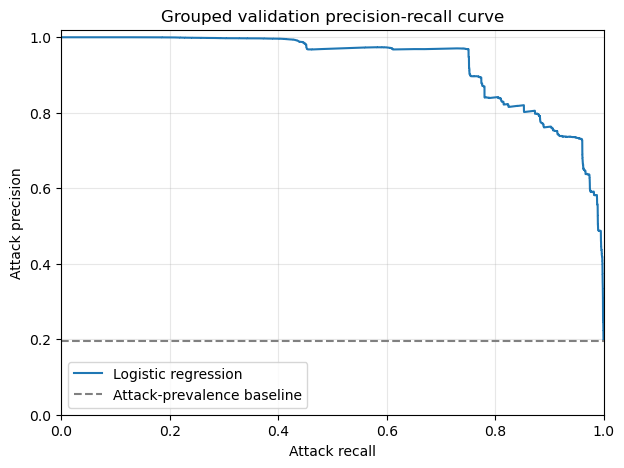

In [94]:
# Purpose: Build the validation precision-recall curve from grouped logistic attack probabilities.
# Explain: Find the attack column by classes_; average precision depends on prevalence.

# ============================================================
# PART 7 - TASK 1
# VALIDATION PRECISION-RECALL CURVE
# ============================================================

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
)

# Probability assigned to the ATTACK class.
part7_attack_class_index = np.flatnonzero(
    grouped_binary_lr.classes_ == 1
)[0]
part7_validation_attack_scores = (
    grouped_binary_lr.predict_proba(
        X_grouped_validation_scaled
    )[:, part7_attack_class_index]
)

(
    part7_validation_precision,
    part7_validation_recall,
    part7_validation_thresholds,
) = precision_recall_curve(
    y_grouped_validation_binary,
    part7_validation_attack_scores,
    pos_label=1,
)

part7_validation_attack_prevalence = np.mean(
    y_grouped_validation_binary == 1
)

part7_curve_summary = pd.Series({
    "selected_C": grouped_best_binary_C,
    "validation_rows":
        len(y_grouped_validation_binary),
    "attack_prevalence":
        part7_validation_attack_prevalence,
    "average_precision":
        average_precision_score(
            y_grouped_validation_binary,
            part7_validation_attack_scores,
        ),
}, name="grouped_binary_logistic_regression")

display(part7_curve_summary.to_frame())

plt.figure(figsize=(7, 5))
plt.plot(
    part7_validation_recall,
    part7_validation_precision,
    label="Logistic regression",
)
plt.axhline(
    part7_validation_attack_prevalence,
    color="gray",
    linestyle="--",
    label="Attack-prevalence baseline",
)
plt.xlabel("Attack recall")
plt.ylabel("Attack precision")
plt.title("Grouped validation precision-recall curve")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Interpretation

The precision-recall curve shows the validation trade-off produced by changing
the attack-alert threshold. Moving toward higher recall detects more attacks but
usually creates more false alerts and lowers precision. Average precision
summarizes the curve, while the dashed line shows the precision expected from the
validation attack prevalence alone. No threshold is selected in this task, and the
test set remains unused for threshold selection.

For many possible thresholds, we will calculate:

- **Attack recall:** proportion of attacks detected.
- **False-positive rate:** proportion of benign flows incorrectly flagged.
- **Precision:** proportion of alerts that are actual attacks.

A lower threshold usually detects more attacks but generates more false alarms. A higher threshold reduces false alarms but misses more attacks.


,attack_recall,false_positive_rate,precision
threshold,,,
0.1,0.974471,0.161574,0.595014
0.3,0.929541,0.080745,0.737148
0.5,0.808123,0.037898,0.838568
0.7,0.608572,0.004429,0.970994
0.9,0.435716,0.000982,0.990831


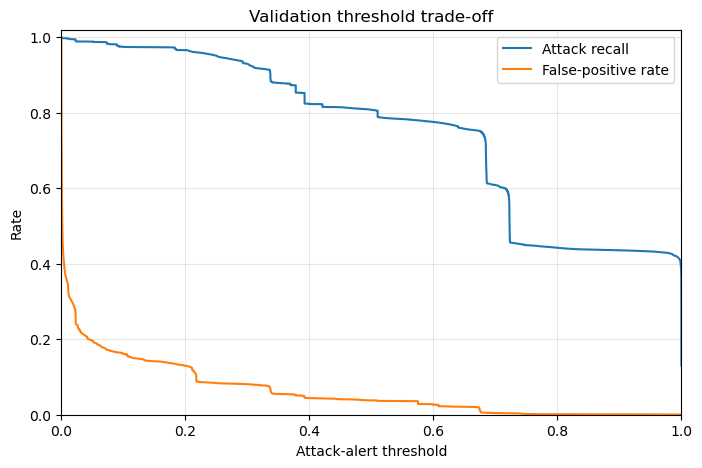

In [95]:
# Purpose: Measure validation recall and false-positive rate across probability thresholds.
# Explain: Changing the threshold changes alerts, not the fitted logistic coefficients.

# ============================================================
# PART 7 - TASK 2
# VALIDATION THRESHOLD TRADE-OFF
# ============================================================

from sklearn.metrics import confusion_matrix, roc_curve

(
    part7_validation_fpr,
    part7_validation_attack_recall,
    part7_validation_roc_thresholds,
) = roc_curve(
    y_grouped_validation_binary,
    part7_validation_attack_scores,
    pos_label=1,
)

part7_finite_thresholds = np.isfinite(
    part7_validation_roc_thresholds
)
part7_validation_fpr = part7_validation_fpr[
    part7_finite_thresholds
]
part7_validation_attack_recall = (
    part7_validation_attack_recall[
        part7_finite_thresholds
    ]
)
part7_validation_roc_thresholds = (
    part7_validation_roc_thresholds[
        part7_finite_thresholds
    ]
)

part7_threshold_rows = []

for threshold in [0.1, 0.3, 0.5, 0.7, 0.9]:
    predictions = (
        part7_validation_attack_scores
        >= threshold
    ).astype(int)

    true_negative, false_positive, false_negative, true_positive = (
        confusion_matrix(
            y_grouped_validation_binary,
            predictions,
            labels=[0, 1],
        ).ravel()
    )

    part7_threshold_rows.append({
        "threshold": threshold,
        "attack_recall":
            true_positive
            / (true_positive + false_negative),
        "false_positive_rate":
            false_positive
            / (false_positive + true_negative),
        "precision":
            true_positive
            / (true_positive + false_positive),
    })

part7_threshold_table = pd.DataFrame(
    part7_threshold_rows
).set_index("threshold")

display(part7_threshold_table.round(6))

part7_threshold_order = np.argsort(
    part7_validation_roc_thresholds
)

plt.figure(figsize=(8, 5))
plt.plot(
    part7_validation_roc_thresholds[
        part7_threshold_order
    ],
    part7_validation_attack_recall[
        part7_threshold_order
    ],
    label="Attack recall",
)
plt.plot(
    part7_validation_roc_thresholds[
        part7_threshold_order
    ],
    part7_validation_fpr[
        part7_threshold_order
    ],
    label="False-positive rate",
)
plt.xlabel("Attack-alert threshold")
plt.ylabel("Rate")
plt.title("Validation threshold trade-off")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Interpretation

The table and plot show the operational cost of changing the validation alert
threshold. Lower thresholds classify more flows as attacks, increasing attack
recall but also increasing the false-positive rate. Higher thresholds reduce
benign false alarms but miss more attacks. These validation results will be used
to declare a target false-positive rate and select one fixed threshold before the
final test evaluation.

In [96]:
# Purpose: Select the highest-recall validation threshold satisfying FPR <= 1%.
# Explain: Freeze this operating point before test; an empirical constraint is not a future guarantee.

# ============================================================
# PART 7 - TASK 3
# SELECT A THRESHOLD USING VALIDATION DATA
# ============================================================

# Declare the acceptable fraction of benign validation flows flagged as attacks.
PART7_TARGET_FPR = 0.01

# Align each threshold with the validation rates obtained at that threshold.
part7_validation_candidates = pd.DataFrame({
    "threshold":
        part7_validation_roc_thresholds,
    "false_positive_rate":
        part7_validation_fpr,
    "attack_recall":
        part7_validation_attack_recall,
})

# Discard operating points that violate the validation false-alarm constraint.
part7_eligible_candidates = (
    part7_validation_candidates.loc[
        part7_validation_candidates[
            "false_positive_rate"
        ] <= PART7_TARGET_FPR
    ]
)

# Sort recall from highest to lowest, then threshold from highest to lowest.
# The first row is the chosen eligible operating point.
part7_selected_candidate = (
    part7_eligible_candidates.sort_values(
        ["attack_recall", "threshold"],
        ascending=[False, False],
    ).iloc[0]
)

# Extract the threshold for later prediction: attack_score >= threshold.
part7_selected_threshold = float(
    part7_selected_candidate["threshold"]
)

part7_selected_validation_predictions = (
    part7_validation_attack_scores
    >= part7_selected_threshold
).astype(int)

(
    part7_validation_tn,
    part7_validation_fp,
    part7_validation_fn,
    part7_validation_tp,
) = confusion_matrix(
    y_grouped_validation_binary,
    part7_selected_validation_predictions,
    labels=[0, 1],
).ravel()

part7_selected_threshold_summary = pd.Series({
    "target_false_positive_rate":
        PART7_TARGET_FPR,
    "selected_threshold":
        part7_selected_threshold,
    "validation_attack_recall":
        part7_validation_tp
        / (part7_validation_tp + part7_validation_fn),
    "validation_false_positive_rate":
        part7_validation_fp
        / (part7_validation_fp + part7_validation_tn),
    "validation_precision":
        part7_validation_tp
        / (part7_validation_tp + part7_validation_fp),
    "validation_false_alarms_per_100k_benign":
        100_000 * part7_validation_fp
        / (part7_validation_fp + part7_validation_tn),
}, name="selected_validation_threshold")

display(
    part7_selected_threshold_summary.to_frame()
        .round(6)
)

,selected_validation_threshold
target_false_positive_rate,0.010000
selected_threshold,0.675704
validation_attack_recall,0.750565
validation_false_positive_rate,0.009734
validation_precision,0.949455
validation_false_alarms_per_100k_benign,973.392471


### Interpretation

The operational target allows at most 1% of benign validation flows to be
flagged as attacks. Among all thresholds meeting that target, the selected
threshold gives the highest validation attack recall. It is now frozen: neither
the threshold nor the model may be changed after the test results are examined.
The next task applies this threshold once to the grouped test set.

,grouped_test
frozen_threshold,0.675704
test_attack_recall,0.749568
test_false_positive_rate,0.009643
test_precision,0.950335
test_false_alarms_per_100k_benign,964.251961
true_negatives,449550.000000
false_positives,4377.000000
false_negatives,27982.000000
true_positives,83753.000000


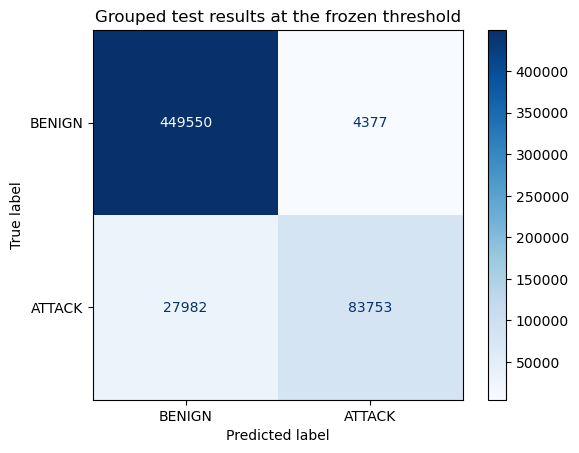

In [97]:
# Purpose: Apply the validation-selected threshold once to grouped test probabilities.
# Explain: Report attack recall, FPR, and false alerts per 100,000 BENIGN flows without retuning.

# ============================================================
# PART 7 - TASK 4
# APPLY THE FROZEN THRESHOLD TO THE GROUPED TEST SET
# ============================================================

part7_test_attack_scores = (
    grouped_binary_lr.predict_proba(
        X_grouped_test_scaled
    )[:, part7_attack_class_index]
)

part7_test_predictions = (
    part7_test_attack_scores
    >= part7_selected_threshold
).astype(int)

part7_test_confusion_matrix = confusion_matrix(
    y_grouped_test_binary,
    part7_test_predictions,
    labels=[0, 1],
)

(
    part7_test_tn,
    part7_test_fp,
    part7_test_fn,
    part7_test_tp,
) = part7_test_confusion_matrix.ravel()

part7_test_summary = pd.Series({
    "frozen_threshold":
        part7_selected_threshold,
    "test_attack_recall":
        part7_test_tp
        / (part7_test_tp + part7_test_fn),
    "test_false_positive_rate":
        part7_test_fp
        / (part7_test_fp + part7_test_tn),
    "test_precision":
        part7_test_tp
        / (part7_test_tp + part7_test_fp),
    "test_false_alarms_per_100k_benign":
        100_000 * part7_test_fp
        / (part7_test_fp + part7_test_tn),
    "true_negatives": part7_test_tn,
    "false_positives": part7_test_fp,
    "false_negatives": part7_test_fn,
    "true_positives": part7_test_tp,
}, name="grouped_test")

display(part7_test_summary.to_frame().round(6))

ConfusionMatrixDisplay(
    confusion_matrix=part7_test_confusion_matrix,
    display_labels=["BENIGN", "ATTACK"],
).plot(cmap="Blues", values_format="d")
plt.title(
    "Grouped test results at the frozen threshold"
)
plt.show()

### Interpretation

This is the final operational evaluation using the threshold selected entirely
from validation data. Test attack recall measures the attacks detected, while the
false-positive rate and FP100k quantify the burden placed on analysts by benign
alerts. Differences from validation show how well the chosen operating point
generalizes. The threshold must not be changed in response to these test results.

In [98]:
# Purpose: Translate test conditional rates into an assumed deployment workload and cost.
# Explain: Different attack prevalence changes precision; this scenario does not prove cost optimality.

# ============================================================
# PART 7 - TASK 5
# ILLUSTRATIVE DEPLOYMENT COSTS
# ============================================================

PART7_DEPLOYMENT_FLOWS = 100_000
PART7_ASSUMED_ATTACK_PREVALENCE = 0.01
PART7_FALSE_POSITIVE_COST = 1
PART7_FALSE_NEGATIVE_COST = 20

part7_expected_attacks = (
    PART7_DEPLOYMENT_FLOWS
    * PART7_ASSUMED_ATTACK_PREVALENCE
)
part7_expected_benign = (
    PART7_DEPLOYMENT_FLOWS
    - part7_expected_attacks
)

part7_expected_detected_attacks = (
    part7_expected_attacks
    * part7_test_summary["test_attack_recall"]
)
part7_expected_missed_attacks = (
    part7_expected_attacks
    - part7_expected_detected_attacks
)
part7_expected_false_alerts = (
    part7_expected_benign
    * part7_test_summary[
        "test_false_positive_rate"
    ]
)
part7_expected_correct_benign = (
    part7_expected_benign
    - part7_expected_false_alerts
)

part7_expected_cost = (
    PART7_FALSE_POSITIVE_COST
    * part7_expected_false_alerts
    + PART7_FALSE_NEGATIVE_COST
    * part7_expected_missed_attacks
)

part7_operational_summary = pd.Series({
    "assumed_attack_prevalence":
        PART7_ASSUMED_ATTACK_PREVALENCE,
    "false_positive_cost_units":
        PART7_FALSE_POSITIVE_COST,
    "false_negative_cost_units":
        PART7_FALSE_NEGATIVE_COST,
    "expected_attacks":
        part7_expected_attacks,
    "expected_detected_attacks":
        part7_expected_detected_attacks,
    "expected_missed_attacks":
        part7_expected_missed_attacks,
    "expected_false_alerts":
        part7_expected_false_alerts,
    "expected_correct_benign":
        part7_expected_correct_benign,
    "expected_total_cost_units":
        part7_expected_cost,
}, name="per_100k_deployment_flows")

display(part7_operational_summary.to_frame().round(2))

,per_100k_deployment_flows
assumed_attack_prevalence,0.01
false_positive_cost_units,1.00
false_negative_cost_units,20.00
expected_attacks,1000.00
expected_detected_attacks,749.57
expected_missed_attacks,250.43
expected_false_alerts,954.61
expected_correct_benign,98045.39
expected_total_cost_units,5963.25


### Interpretation

Assuming 1% attack prevalence, 100,000 deployment flows contain approximately
1,000 attacks and 99,000 benign flows. At the frozen threshold, the test rates
imply about 750 detected attacks, 250 missed attacks, and 955 false alerts. The
illustrative cost assigns one unit to investigating a false alert and 20 units to
a missed attack, giving about 5,963 total cost units. These values are explicit
assumptions rather than measured organizational costs. The threshold represents a
compromise: it keeps the false-alert workload near 1,000 per 100,000 benign flows
while detecting about three quarters of attacks.